In [1]:
import pandas as pd
import numpy as np
import glob
import os
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [2]:
DATA_DIR = "train"  # path to the folder containing input_2023_w*.csv and output_2023_w*.csv
MAX_INPUT_FRAMES = 50
MAX_OUTPUT_FRAMES = 25
FIELD_X, FIELD_Y = 120.0, 53.3

In [3]:
def load_tracking_data(data_dir):
    input_files = sorted(glob.glob(os.path.join(data_dir, "input_2023_w*.csv")))
    output_files = sorted(glob.glob(os.path.join(data_dir, "output_2023_w*.csv")))

    df_input = pd.concat((pd.read_csv(f) for f in input_files), ignore_index=True)
    df_output = pd.concat((pd.read_csv(f) for f in output_files), ignore_index=True)
    return df_input, df_output

df_input, df_output = load_tracking_data(DATA_DIR)

In [4]:
drop_cols = ["player_name", "player_height", "player_weight", "player_birth_date"]
df_input.drop(columns=drop_cols, inplace=True, errors="ignore")

In [5]:
df_output

,game_id,play_id,nfl_id,frame_id,x,y
0,2023090700,101,46137,1,56.22,17.28
1,2023090700,101,46137,2,56.63,16.88
2,2023090700,101,46137,3,57.06,16.46
3,2023090700,101,46137,4,57.48,16.02
4,2023090700,101,46137,5,57.91,15.56
...,...,...,...,...,...,...
562931,2024010713,4018,52457,14,30.99,10.51
562932,2024010713,4018,52457,15,30.78,9.73
562933,2024010713,4018,52457,16,30.63,8.93
562934,2024010713,4018,52457,17,30.52,8.12


In [6]:
cat_cols = ["player_position", "player_role", "player_side", "play_direction"]
encoders = {col: LabelEncoder().fit(df_input[col].astype(str)) for col in cat_cols}

for col, le in encoders.items():
    df_input[col] = le.transform(df_input[col].astype(str))

# Normalize continuous fields
df_input["x_norm"] = df_input["x"] / FIELD_X
df_input["y_norm"] = df_input["y"] / FIELD_Y
df_input["s_norm"] = df_input["s"] / df_input["s"].max()
df_input["a_norm"] = df_input["a"] / df_input["a"].max()

df_output["x"] = df_output["x"] / FIELD_X
df_output["y"] = df_output["y"] / FIELD_Y

# Convert degrees to radians and compute velocity components
df_input["dir_rad"] = np.deg2rad(df_input["dir"])
df_input["vx"] = df_input["s_norm"] * np.cos(df_input["dir_rad"])
df_input["vy"] = df_input["s_norm"] * np.sin(df_input["dir_rad"])

# Ball-relative features
df_input["x_rel_to_ball"] = (df_input["x"] - df_input["ball_land_x"]) / FIELD_X
df_input["y_rel_to_ball"] = (df_input["y"] - df_input["ball_land_y"]) / FIELD_Y
df_input["dist_to_ball"] = np.sqrt(
    (df_input["x_rel_to_ball"] ** 2) + (df_input["y_rel_to_ball"] ** 2)
)


In [7]:
feature_cols = [
    "x_norm",
    "y_norm",
    "vx",
    "vy",
    "a_norm",
    "player_position",
    "player_role",
    "player_side",
    "play_direction",
    "x_rel_to_ball",
    "y_rel_to_ball",
    "dist_to_ball",
]

In [8]:
plays = df_input.groupby(["game_id", "play_id"])

X_data, Y_data, masks, metas = [], [], [], []

for (game_id, play_id), play_df in plays:
    # --- INPUT ---
    frames_in = play_df.sort_values("frame_id")
    player_ids = frames_in["nfl_id"].unique()
    num_players = len(player_ids)

    # Group by frame
    grouped_frames = []
    for frame_id, frame_df in frames_in.groupby("frame_id"):
        mat = frame_df[feature_cols].to_numpy()
        if mat.shape[0] < 22:  # handle missing players
            mat = np.pad(mat, ((0, 22 - mat.shape[0]), (0, 0)), mode="constant")
        grouped_frames.append(mat)
    X_seq = np.stack(grouped_frames)
    if X_seq.shape[0] < MAX_INPUT_FRAMES:
        pad_len = MAX_INPUT_FRAMES - X_seq.shape[0]
        # X_seq = np.pad(X_seq, ((0, pad_len), (0, 0), (0, 0)), mode="constant")
        # Pad with last frame
        last_frame = X_seq[-1:]
        pad_frames = np.repeat(last_frame, pad_len, axis=0)
        X_seq = np.concatenate([X_seq, pad_frames], axis=0)
    else:
        X_seq = X_seq[:MAX_INPUT_FRAMES]

    # --- OUTPUT ---
    play_out = df_output[
        (df_output["game_id"] == game_id) & (df_output["play_id"] == play_id)
    ]
    frames_out = []
    for frame_id, frame_df in play_out.groupby("frame_id"):
        mat = frame_df[["x", "y"]].to_numpy()
        if mat.shape[0] < 22:
            mat = np.pad(mat, ((0, 22 - mat.shape[0]), (0, 0)), mode="constant")
        frames_out.append(mat)
    if not frames_out:
        continue
    Y_seq = np.stack(frames_out)
    if Y_seq.shape[0] < MAX_OUTPUT_FRAMES:
        pad_len = MAX_OUTPUT_FRAMES - Y_seq.shape[0]
        # Y_seq = np.pad(Y_seq, ((0, pad_len), (0, 0), (0, 0)), mode="constant")
        # Pad with last frame
        last_frame = Y_seq[-1:]
        pad_frames = np.repeat(last_frame, pad_len, axis=0)
        Y_seq = np.concatenate([Y_seq, pad_frames], axis=0)
    else:
        Y_seq = Y_seq[:MAX_OUTPUT_FRAMES]

    # --- Mask for predicted players ---
    mask = frames_in.groupby("nfl_id")["player_to_predict"].max().values
    if len(mask) < 22:
        mask = np.pad(mask, (0, 22 - len(mask)), mode="constant")

    X_data.append(X_seq)
    Y_data.append(Y_seq)
    masks.append(mask)
    metas.append((game_id, play_id))

X_data = np.array(X_data)
Y_data = np.array(Y_data)
masks = np.array(masks)

print("X_data:", X_data.shape)  # (num_plays, MAX_INPUT_FRAMES, 22, feature_dim)
print("Y_data:", Y_data.shape)  # (num_plays, MAX_OUTPUT_FRAMES, 22, 2)
print("masks:", masks.shape)

X_data: (14108, 50, 22, 12)
Y_data: (14108, 25, 22, 2)
masks: (14108, 22)


In [9]:
import torch
from torch.utils.data import Dataset, DataLoader

class NFLPassDataset(Dataset):
    def __init__(self, X, Y, masks):
        """
        X: np.array of shape (num_plays, seq_in, 22, feature_dim)
        Y: np.array of shape (num_plays, seq_out, 22, 2)
        masks: np.array of shape (num_plays, 22)
        """
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)
        self.masks = torch.tensor(masks, dtype=torch.bool)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return {
            "X": self.X[idx],           # (seq_in, 22, feature_dim)
            "Y": self.Y[idx],           # (seq_out, 22, 2)
            "mask": self.masks[idx]     # (22,)
        }

# =========================
# Create Dataset & DataLoader
# =========================
dataset = NFLPassDataset(X_data, Y_data, masks)
batch_size = 32
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)


In [10]:
def masked_rmse(pred, target, mask):
    """
    pred, target: (batch_size, seq_out, 22, 2)
    mask: (batch_size, 22) boolean
    """
    # mask = mask.unsqueeze(1).unsqueeze(-1)  # -> (batch, 1, 22, 1)
    mask = mask.unsqueeze(1).expand(-1, seq_out, -1).unsqueeze(-1)  # (batch, seq_out, 22, 1)
    diff = (pred - target) ** 2
    masked_diff = diff * mask.float()
    mse = masked_diff.sum() / mask.sum().float()
    return torch.sqrt(mse)


In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class PlayerAttention(nn.Module):
    """Attention across all players in a single frame"""
    def __init__(self, in_dim, hidden_dim):
        super().__init__()
        self.q = nn.Linear(in_dim, hidden_dim)
        self.k = nn.Linear(in_dim, hidden_dim)
        self.v = nn.Linear(in_dim, hidden_dim)
        self.out = nn.Linear(hidden_dim, in_dim)

    def forward(self, x):
        # x: (batch, num_players, feat_dim)
        Q = self.q(x)
        K = self.k(x)
        V = self.v(x)
        attn_scores = torch.matmul(Q, K.transpose(-2, -1)) / (Q.shape[-1] ** 0.5)
        attn_weights = F.softmax(attn_scores, dim=-1)
        out = torch.matmul(attn_weights, V)
        out = self.out(out)
        return out + x  # residual

class TemporalTransformer(nn.Module):
    """Temporal transformer across frames"""
    def __init__(self, feat_dim, n_heads=4, n_layers=2, seq_len=50, seq_out=25):
        super().__init__()
        self.frame_attention = PlayerAttention(feat_dim, feat_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=22*feat_dim, nhead=n_heads, batch_first=True
        )
        self.temporal_encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.seq_out = seq_out
        self.feat_dim = feat_dim
        self.output_proj = nn.Linear(22*feat_dim, 22*2)  # output x,y for each player

    def forward(self, x):
        # x: (batch, seq_in, 22, feat_dim)
        batch, seq_in, num_players, feat_dim = x.shape

        # Player attention per frame
        x = x.view(batch*seq_in, num_players, feat_dim)
        x = self.frame_attention(x)
        x = x.view(batch, seq_in, num_players*feat_dim)

        # Temporal transformer
        x = self.temporal_encoder(x)  # (batch, seq_in, 22*feat_dim)

        # Project to output frames using last seq_out hidden states
        out = self.output_proj(x[:, -self.seq_out:, :])  # (batch, seq_out, 22*2)
        out = out.view(batch, self.seq_out, num_players, 2)
        return out


In [12]:
feat_dim = X_data.shape[-1]
seq_in = X_data.shape[1]
seq_out = Y_data.shape[1]

model = TemporalTransformer(feat_dim=feat_dim, seq_len=seq_in, seq_out=seq_out)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


In [13]:
device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
model.to(device)

for epoch in range(10):
    model.train()
    total_loss = 0
    for batch in dataloader:
        # Move everything to the same device
        X = batch['X'].to(device)
        Y = batch['Y'].to(device)
        mask = batch['mask'].to(device)

        pred = model(X)
        loss = masked_rmse(pred, Y, mask)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1} | Loss: {total_loss/len(dataloader):.5f}")


Epoch 1 | Loss: 0.26326
Epoch 2 | Loss: 0.20741
Epoch 3 | Loss: 0.19895
Epoch 4 | Loss: 0.18899
Epoch 5 | Loss: 0.18436
Epoch 6 | Loss: 0.18176
Epoch 7 | Loss: 0.17953
Epoch 8 | Loss: 0.17773
Epoch 9 | Loss: 0.17608
Epoch 10 | Loss: 0.17476


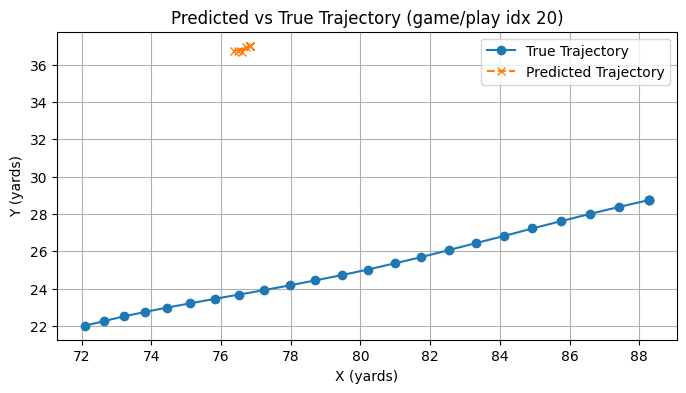

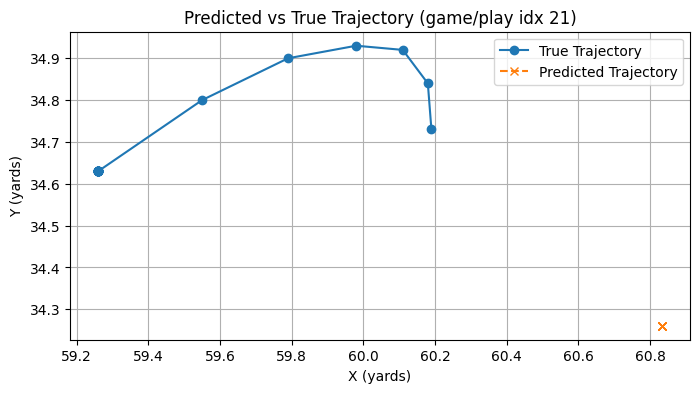

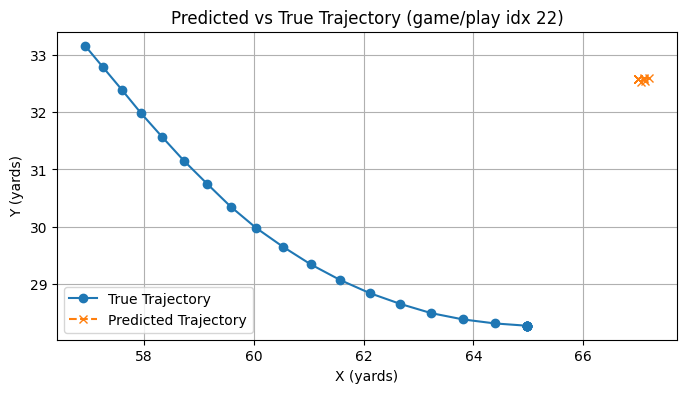

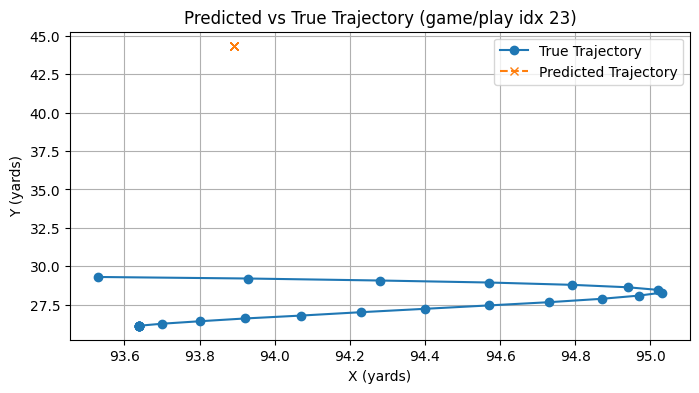

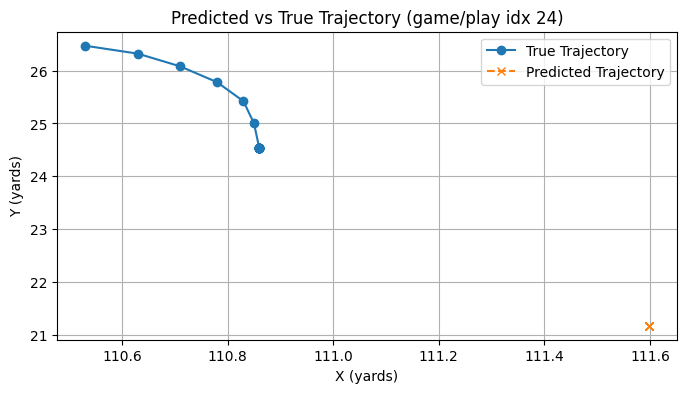

...

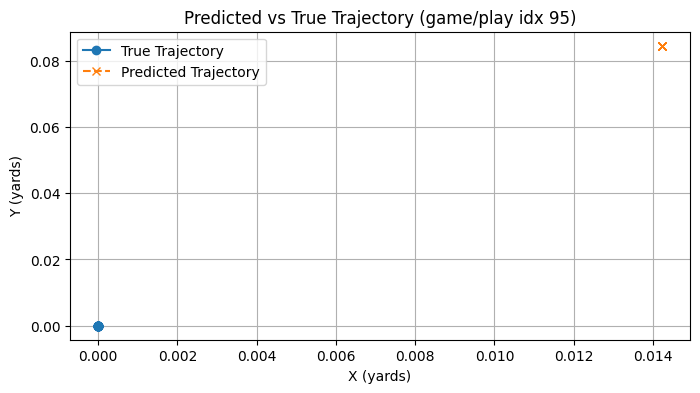

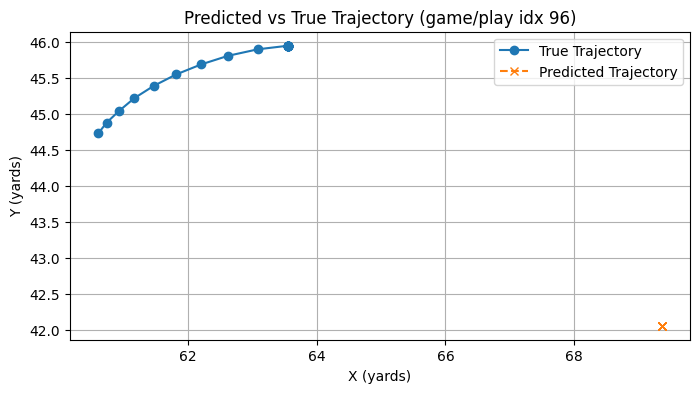

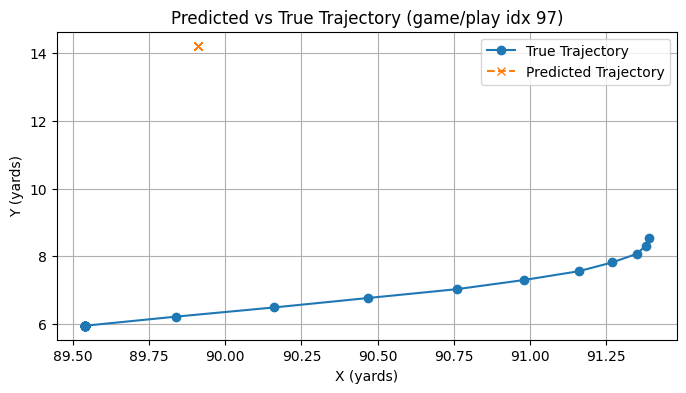

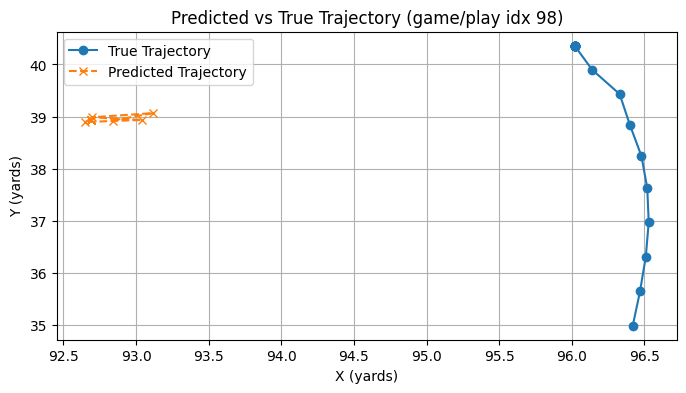

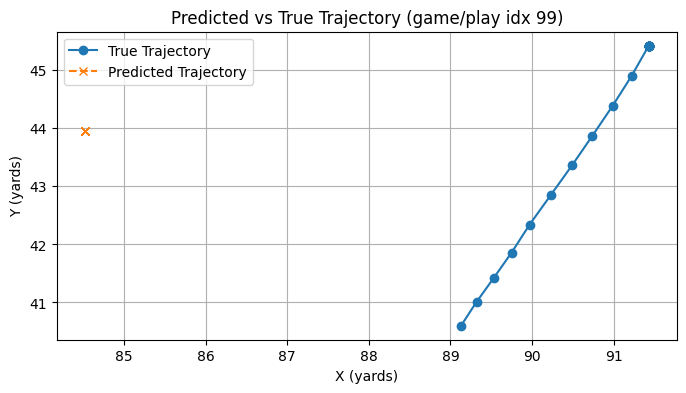

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Pick one play from validation or training set
for sample_idx in range(20, 100): # any index from your dataset
    X_sample = torch.tensor(X_data[sample_idx:sample_idx+1], dtype=torch.float32).to(device)
    Y_true = Y_data[sample_idx]  # shape (25, 22, 2)
    mask = masks[sample_idx]
    
    # Get prediction
    model.eval()
    with torch.no_grad():
        Y_pred = model(X_sample).cpu().numpy()[0]  # shape (25, 22, 2)
    
    # Denormalize for plotting
    Y_true_denorm = Y_true.copy()
    Y_true_denorm[..., 0] *= FIELD_X
    Y_true_denorm[..., 1] *= FIELD_Y
    Y_pred_denorm = Y_pred.copy()
    Y_pred_denorm[..., 0] *= FIELD_X
    Y_pred_denorm[..., 1] *= FIELD_Y
    
    # Plot one targeted player or all players
    target_idx = np.where(mask == 1)[0][0] if mask.sum() == 1 else 0
    
    plt.figure(figsize=(8, 4))
    plt.plot(
        Y_true_denorm[:, target_idx, 0],
        Y_true_denorm[:, target_idx, 1],
        "o-", label="True Trajectory"
    )
    plt.plot(
        Y_pred_denorm[:, target_idx, 0],
        Y_pred_denorm[:, target_idx, 1],
        "x--", label="Predicted Trajectory"
    )
    plt.title(f"Predicted vs True Trajectory (game/play idx {sample_idx})")
    plt.xlabel("X (yards)")
    plt.ylabel("Y (yards)")
    plt.legend()
    plt.grid(True)
    plt.show()


In [15]:
## Graph Model

In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------
# Graph module per frame
# ------------------------
class FrameGraphModule(nn.Module):
    def __init__(self, feat_dim, hidden_dim):
        super().__init__()
        self.intra_team_fc = nn.Linear(feat_dim, hidden_dim)
        self.bipartite_fc = nn.Linear(feat_dim, hidden_dim)
        self.to_landing_fc = nn.Linear(feat_dim, hidden_dim)
        self.out_fc = nn.Linear(hidden_dim * 3, feat_dim)  # combine all graph outputs

    def forward(self, x, adj_intra, adj_bipartite, adj_to_landing):
        """
        x: (batch, num_players, feat_dim)
        adj_*: (batch, num_players, num_players)
        """
        # Simple graph aggregation: sum neighbors
        intra_msg = torch.matmul(adj_intra, self.intra_team_fc(x))
        bip_msg = torch.matmul(adj_bipartite, self.bipartite_fc(x))
        landing_msg = torch.matmul(adj_to_landing, self.to_landing_fc(x))

        # Concatenate messages and residual
        combined = torch.cat([intra_msg, bip_msg, landing_msg], dim=-1)
        out = self.out_fc(combined) + x  # residual
        return out

# ------------------------
# Seq-to-Seq model
# ------------------------
class Seq2SeqGraphTransformer(nn.Module):
    def __init__(self, feat_dim, hidden_dim, n_heads=4, n_layers=2, seq_out=25):
        super().__init__()
        self.frame_graph = FrameGraphModule(feat_dim, hidden_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=22*feat_dim, nhead=n_heads, batch_first=True
        )
        self.temporal_encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.seq_out = seq_out
        self.feat_dim = feat_dim
        self.output_proj = nn.Linear(22*feat_dim, 22*2)  # predict x,y per player

    def forward(self, x, adj_intra_seq, adj_bipartite_seq, adj_to_landing_seq):
        """
        x: (batch, seq_in, 22, feat_dim)
        adj_*_seq: (batch, seq_in, 22, 22)
        """
        batch, seq_in, num_players, feat_dim = x.shape

        # Vectorized frame-wise graph updates - process all frames at once
        # Flatten time into batch to do one big matmul per edge type
        x_bt = x.view(batch * seq_in, num_players, feat_dim)
        adj_intra_bt = adj_intra_seq.view(batch * seq_in, num_players, num_players)
        adj_bipartite_bt = adj_bipartite_seq.view(batch * seq_in, num_players, num_players)
        adj_to_landing_bt = adj_to_landing_seq.view(batch * seq_in, num_players, num_players)

        # Graph operations on all frames simultaneously
        intra_msg = torch.matmul(adj_intra_bt, self.frame_graph.intra_team_fc(x_bt))
        bip_msg = torch.matmul(adj_bipartite_bt, self.frame_graph.bipartite_fc(x_bt))
        landing_msg = torch.matmul(adj_to_landing_bt, self.frame_graph.to_landing_fc(x_bt))

        # Concatenate messages and residual
        combined = torch.cat([intra_msg, bip_msg, landing_msg], dim=-1)
        x_bt_out = self.frame_graph.out_fc(combined) + x_bt  # residual

        # Reshape back to sequence format
        x_seq = x_bt_out.view(batch, seq_in, num_players * feat_dim)

        # Temporal transformer
        x_seq = self.temporal_encoder(x_seq)  # (batch, seq_in, 22*feat_dim)

        # Improved autoregressive prediction with state updates
        preds = []
        hidden_state = x_seq[:, -1, :]  # Start with last input frame
        
        for t in range(self.seq_out):
            # Predict next frame
            out = self.output_proj(hidden_state)  # (batch, 22*2)
            pred_frame = out.view(batch, num_players, 2)
            preds.append(pred_frame)
            
            # Update hidden state for next prediction (simple approach)
            # Convert prediction back to feature space and update hidden state
            pred_features = pred_frame.view(batch, num_players * 2)
            # Simple linear transformation to map (x,y) back to feature space
            if not hasattr(self, 'pred_to_feat'):
                self.pred_to_feat = nn.Linear(num_players * 2, num_players * feat_dim).to(hidden_state.device)
            
            # Update hidden state with predicted features
            hidden_state = hidden_state + 0.1 * self.pred_to_feat(pred_features)  # Residual update
            
        preds = torch.stack(preds, dim=1)  # (batch, seq_out, 22, 2)
        return preds


In [17]:
def compute_intra_team_adj(frame_df):
    """
    frame_df: pandas DataFrame for a single frame
    returns: (22, 22) adjacency matrix for intra-team edges
    """
    team_labels = frame_df['player_side'].values  # "Offense" or "Defense"
    num_players = len(team_labels)
    adj = np.zeros((num_players, num_players))
    for i in range(num_players):
        for j in range(num_players):
            if i != j and team_labels[i] == team_labels[j]:
                adj[i, j] = 1
    return adj

def compute_bipartite_adj(frame_df):
    num_players = len(frame_df)
    sides = frame_df['player_side'].values
    adj = np.zeros((num_players, num_players))
    for i in range(num_players):
        for j in range(num_players):
            if sides[i] != sides[j]:
                adj[i, j] = 1
    return adj


def compute_player_to_landing_adj(frame_df):
    num_players = len(frame_df)
    adj = np.ones((num_players, 1))
    return adj

def compute_adjacency_seq(X_data, df_input):
    """
    X_data: numpy array of shape (batch, seq_in, 22, feat_dim)
    df_input: original dataframe with player information
    Returns:
        adj_intra_seq: (batch, seq_in, 22, 22)
        adj_bipartite_seq: (batch, seq_in, 22, 22)
        adj_to_landing_seq: (batch, seq_in, 22, 22)
    """
    batch_size, seq_in, num_players, feat_dim = X_data.shape
    
    adj_intra_seq = np.zeros((batch_size, seq_in, num_players, num_players))
    adj_bipartite_seq = np.zeros_like(adj_intra_seq)
    adj_to_landing_seq = np.zeros_like(adj_intra_seq)

    # Use original dataframe grouped by plays to infer sides per frame
    plays = df_input.groupby(["game_id", "play_id"])
    
    for batch_idx, ((game_id, play_id), play_df) in enumerate(plays):
        if batch_idx >= batch_size:
            break
        
        frames_in = play_df.sort_values("frame_id")
        
        for frame_idx, (frame_id, frame_df) in enumerate(frames_in.groupby("frame_id")):
            if frame_idx >= seq_in:
                break
            
            # Get sides for players actually present in this frame
            player_sides = frame_df['player_side'].values
            present = min(len(player_sides), num_players)
            
            # Build edges only among present players; padded slots remain zero
            for i in range(present):
                for j in range(present):
                    if i == j:
                        continue
                    if player_sides[i] == player_sides[j]:
                        adj_intra_seq[batch_idx, frame_idx, i, j] = 1
                    else:
                        adj_bipartite_seq[batch_idx, frame_idx, i, j] = 1
            
            # Connect present players to landing point via a star graph centered at an implicit landing node
            # Here, approximate by fully connecting present players (dense influence of landing target)
            for i in range(present):
                for j in range(present):
                    if i != j:
                        adj_to_landing_seq[batch_idx, frame_idx, i, j] = 1

    return (
        torch.tensor(adj_intra_seq, dtype=torch.float32),
        torch.tensor(adj_bipartite_seq, dtype=torch.float32),
        torch.tensor(adj_to_landing_seq, dtype=torch.float32),
    )


In [18]:
# Precompute adjacency matrices for all plays (run once)
print("Precomputing adjacency matrices for all plays...")
adj_intra_all, adj_bipartite_all, adj_to_landing_all = compute_adjacency_seq(X_data, df_input)

# Move to device once
adj_intra_all = adj_intra_all.to(device)
adj_bipartite_all = adj_bipartite_all.to(device)
adj_to_landing_all = adj_to_landing_all.to(device)

print(f"Adjacency matrices shape: {adj_intra_all.shape}")
print(f"Adjacency matrices moved to device: {adj_intra_all.device}")
print("✅ Precomputation complete!")


Precomputing adjacency matrices for all plays...
Adjacency matrices shape: torch.Size([14108, 50, 22, 22])
Adjacency matrices moved to device: mps:0
✅ Precomputation complete!


In [19]:
# Create the graph model instance
feat_dim = X_data.shape[-1]
hidden_dim = 64  # Hidden dimension for graph operations

graph_model = Seq2SeqGraphTransformer(
    feat_dim=feat_dim, 
    hidden_dim=hidden_dim, 
    n_heads=4, 
    n_layers=2, 
    seq_out=seq_out
)
device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")

# Move model to device
graph_model.to(device)

print(f"Graph model created with feat_dim={feat_dim}, hidden_dim={hidden_dim}")
print(f"Model parameters: {sum(p.numel() for p in graph_model.parameters()):,}")


Graph model created with feat_dim=12, hidden_dim=64
Model parameters: 2,745,576


In [20]:
# Train the graph model with optimized GPU usage
graph_optimizer = torch.optim.Adam(graph_model.parameters(), lr=1e-3)

print("Training Graph Neural Network with optimized GPU usage...")
for epoch in range(5):  # Fewer epochs for testing
    graph_model.train()
    total_loss = 0
    num_batches = 0
    
    # Process in larger batches for better GPU utilization
    batch_size = 16  # Increased from 8
    for i in range(0, len(X_data), batch_size):
        batch_end = min(i + batch_size, len(X_data))
        
        # Create tensors directly on device
        X_batch = torch.tensor(X_data[i:batch_end], dtype=torch.float32, device=device)
        Y_batch = torch.tensor(Y_data[i:batch_end], dtype=torch.float32, device=device)
        mask_batch = torch.tensor(masks[i:batch_end], dtype=torch.bool, device=device)
        
        # Use precomputed adjacency matrices
        adj_intra = adj_intra_all[i:batch_end]
        adj_bipartite = adj_bipartite_all[i:batch_end]
        adj_to_landing = adj_to_landing_all[i:batch_end]
        
        # Forward pass
        pred = graph_model(X_batch, adj_intra, adj_bipartite, adj_to_landing)
        loss = masked_rmse(pred, Y_batch, mask_batch)
        
        # Backward pass
        graph_optimizer.zero_grad()
        loss.backward()
        graph_optimizer.step()
        
        total_loss += loss.item()
        num_batches += 1
    
    avg_loss = total_loss / num_batches
    print(f"Epoch {epoch+1} | Loss: {avg_loss:.5f}")

print("Graph model training completed!")


Training Graph Neural Network with optimized GPU usage...
Epoch 1 | Loss: 0.27145
Epoch 2 | Loss: 0.21150
Epoch 3 | Loss: 0.20703
Epoch 4 | Loss: 0.21201
Epoch 5 | Loss: 0.20581
Graph model training completed!


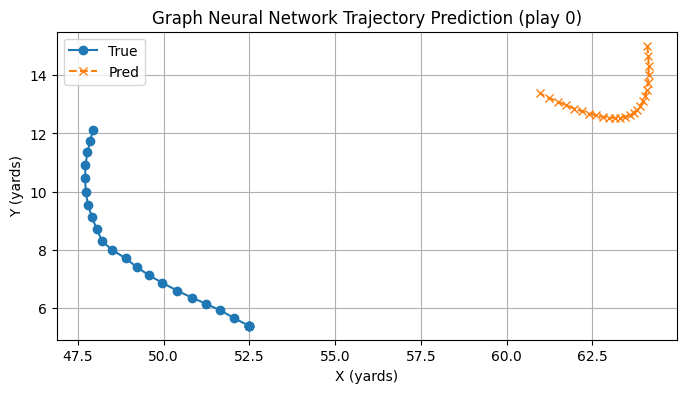

Sample 0 - Target player 1
True trajectory range: X=[47.7, 52.5], Y=[5.4, 12.1]
Pred trajectory range: X=[61.0, 64.1], Y=[12.5, 15.0]


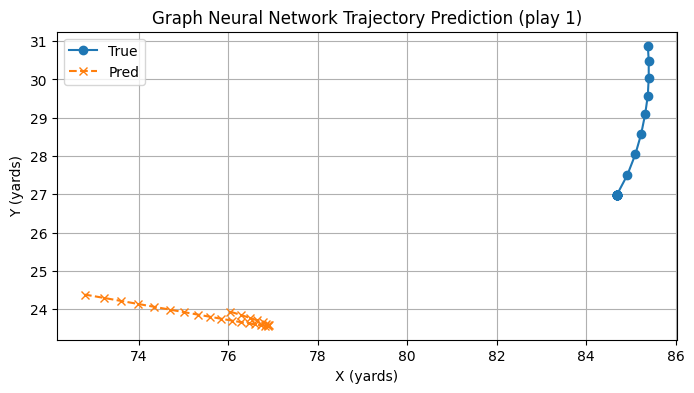

Sample 1 - Target player 0
True trajectory range: X=[84.7, 85.4], Y=[27.0, 30.9]
Pred trajectory range: X=[72.8, 76.9], Y=[23.6, 24.4]


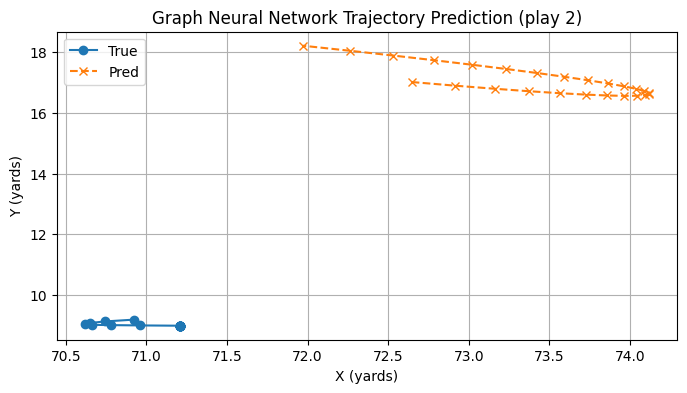

Sample 2 - Target player 1
True trajectory range: X=[70.6, 71.2], Y=[9.0, 9.2]
Pred trajectory range: X=[72.0, 74.1], Y=[16.6, 18.2]


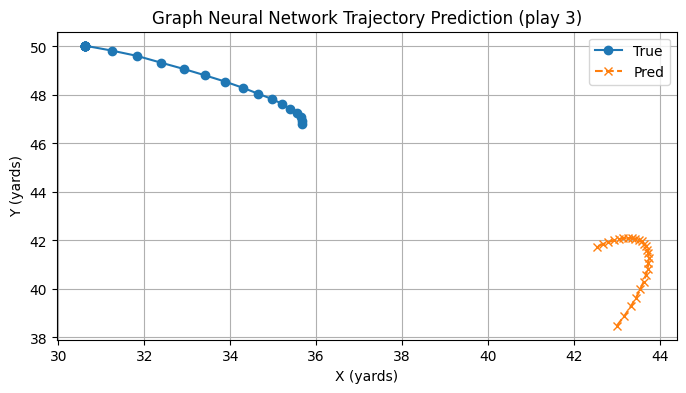

Sample 3 - Target player 0
True trajectory range: X=[30.6, 35.7], Y=[46.8, 50.0]
Pred trajectory range: X=[42.5, 43.7], Y=[38.5, 42.1]


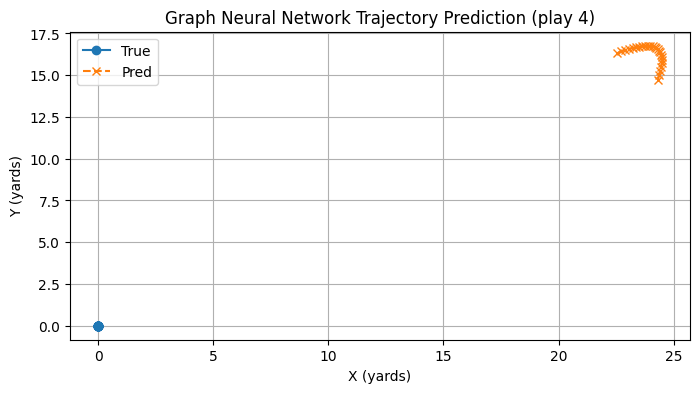

Sample 4 - Target player 3
True trajectory range: X=[0.0, 0.0], Y=[0.0, 0.0]
Pred trajectory range: X=[22.6, 24.5], Y=[14.7, 16.8]


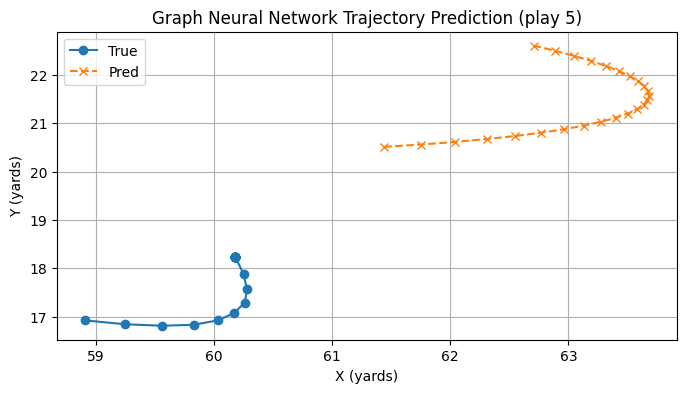

Sample 5 - Target player 1
True trajectory range: X=[58.9, 60.3], Y=[16.8, 18.2]
Pred trajectory range: X=[61.4, 63.7], Y=[20.5, 22.6]


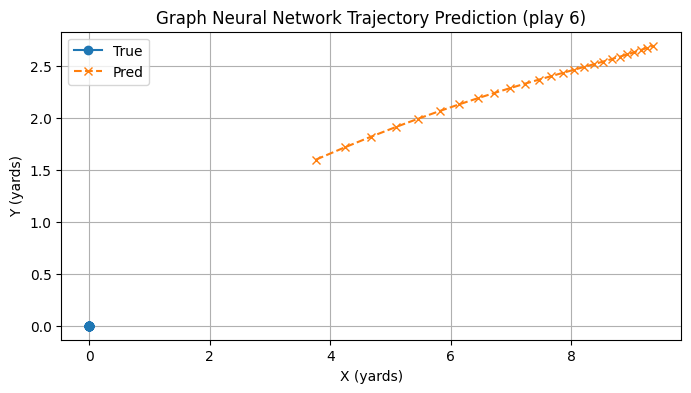

Sample 6 - Target player 5
True trajectory range: X=[0.0, 0.0], Y=[0.0, 0.0]
Pred trajectory range: X=[3.8, 9.4], Y=[1.6, 2.7]


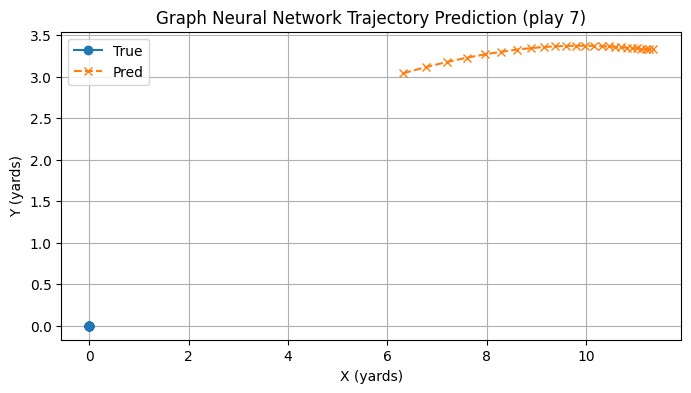

Sample 7 - Target player 5
True trajectory range: X=[0.0, 0.0], Y=[0.0, 0.0]
Pred trajectory range: X=[6.3, 11.3], Y=[3.0, 3.4]


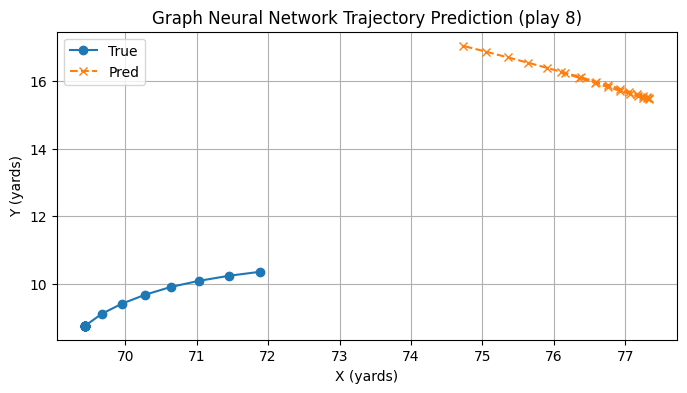

Sample 8 - Target player 1
True trajectory range: X=[69.4, 71.9], Y=[8.8, 10.3]
Pred trajectory range: X=[74.7, 77.3], Y=[15.5, 17.1]


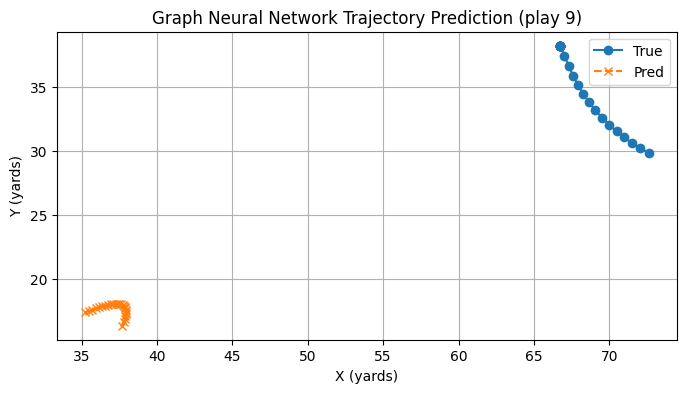

Sample 9 - Target player 3
True trajectory range: X=[66.8, 72.6], Y=[29.9, 38.3]
Pred trajectory range: X=[35.2, 37.9], Y=[16.3, 18.0]


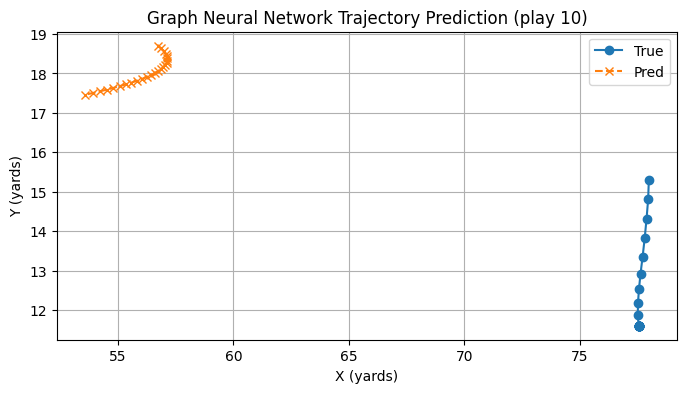

Sample 10 - Target player 2
True trajectory range: X=[77.5, 78.0], Y=[11.6, 15.3]
Pred trajectory range: X=[53.6, 57.1], Y=[17.5, 18.7]


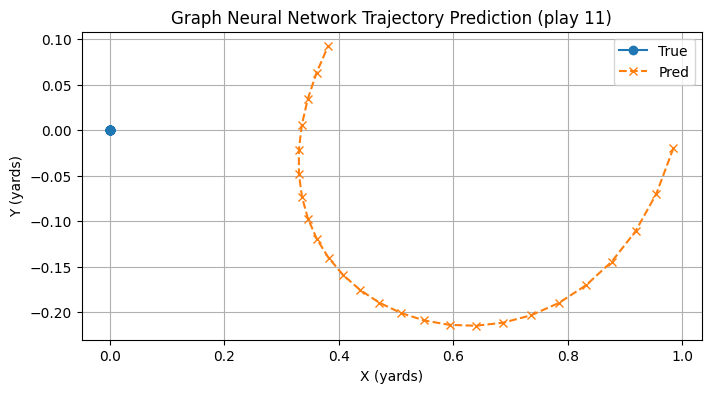

Sample 11 - Target player 7
True trajectory range: X=[0.0, 0.0], Y=[0.0, 0.0]
Pred trajectory range: X=[0.3, 1.0], Y=[-0.2, 0.1]


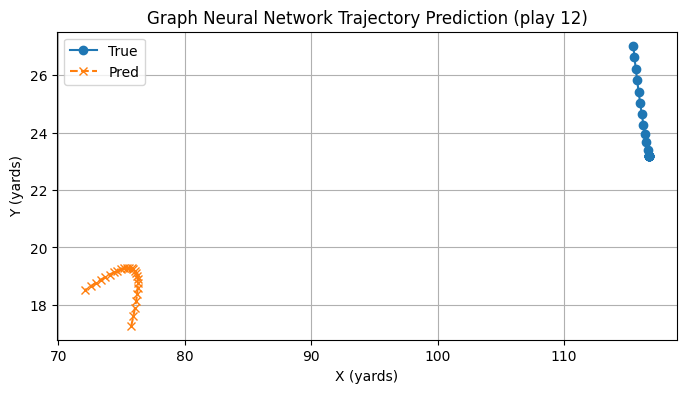

Sample 12 - Target player 3
True trajectory range: X=[115.5, 116.7], Y=[23.2, 27.0]
Pred trajectory range: X=[72.1, 76.3], Y=[17.3, 19.3]


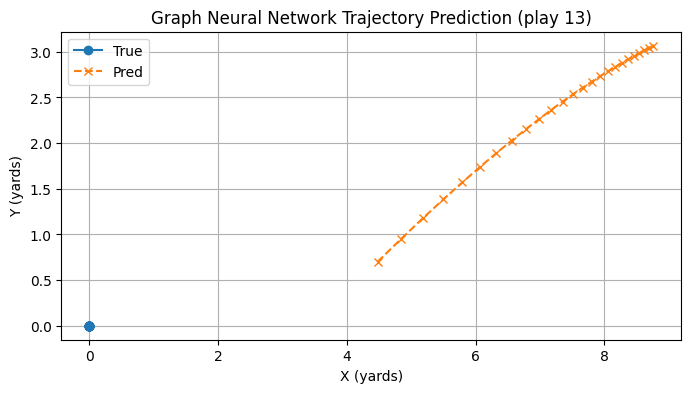

Sample 13 - Target player 5
True trajectory range: X=[0.0, 0.0], Y=[0.0, 0.0]
Pred trajectory range: X=[4.5, 8.8], Y=[0.7, 3.1]


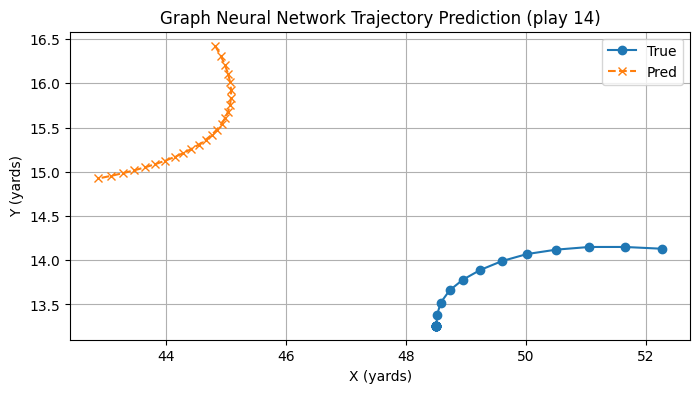

Sample 14 - Target player 2
True trajectory range: X=[48.5, 52.3], Y=[13.3, 14.2]
Pred trajectory range: X=[42.9, 45.1], Y=[14.9, 16.4]


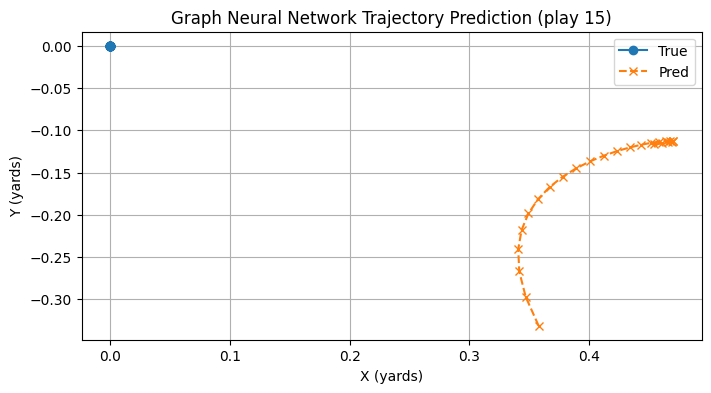

Sample 15 - Target player 6
True trajectory range: X=[0.0, 0.0], Y=[0.0, 0.0]
Pred trajectory range: X=[0.3, 0.5], Y=[-0.3, -0.1]


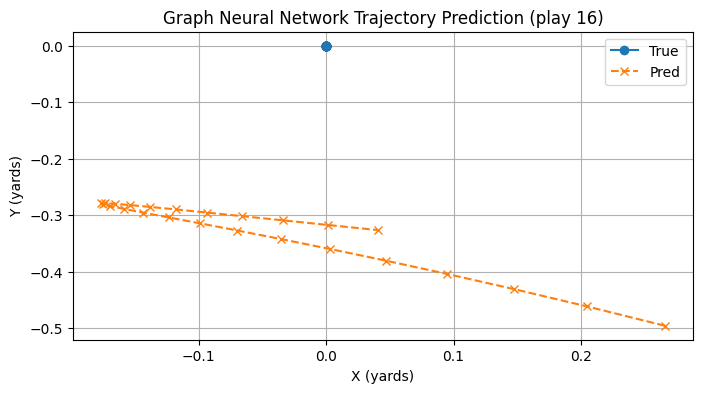

Sample 16 - Target player 10
True trajectory range: X=[0.0, 0.0], Y=[0.0, 0.0]
Pred trajectory range: X=[-0.2, 0.3], Y=[-0.5, -0.3]


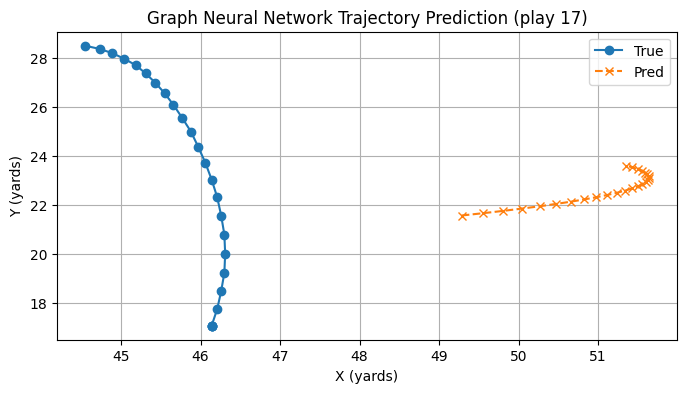

Sample 17 - Target player 1
True trajectory range: X=[44.5, 46.3], Y=[17.1, 28.5]
Pred trajectory range: X=[49.3, 51.6], Y=[21.6, 23.6]


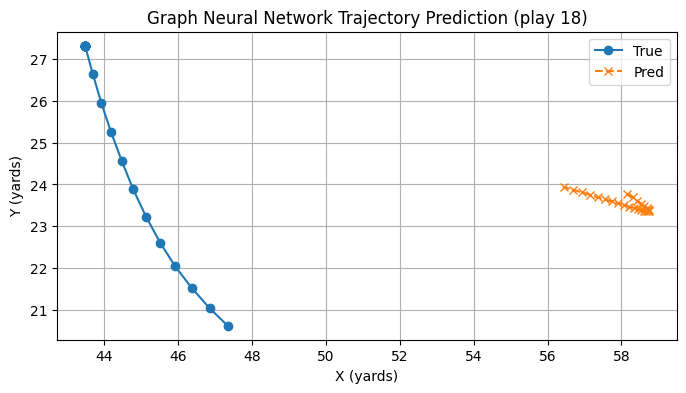

Sample 18 - Target player 0
True trajectory range: X=[43.5, 47.3], Y=[20.6, 27.3]
Pred trajectory range: X=[56.4, 58.7], Y=[23.4, 23.9]


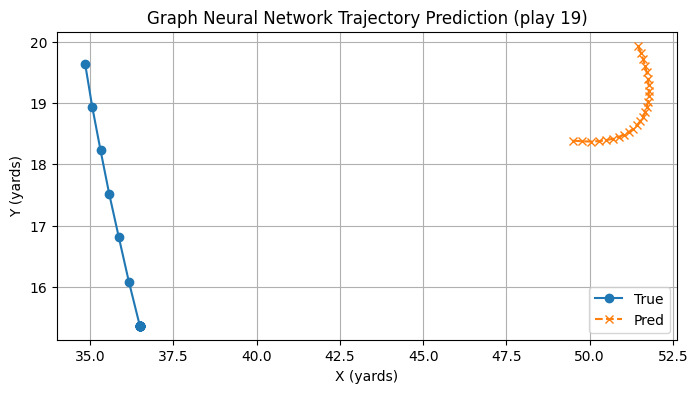

Sample 19 - Target player 1
True trajectory range: X=[34.9, 36.5], Y=[15.4, 19.6]
Pred trajectory range: X=[49.5, 51.8], Y=[18.4, 19.9]


In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Pick a sample
for sample_idx in range(20): # any index from your dataset
    X_sample = torch.tensor(X_data[sample_idx:sample_idx+1], dtype=torch.float32).to(device)
    mask = masks[sample_idx]

    # Compute adjacency matrices for this sample
    adj_intra_seq, adj_bipartite_seq, adj_to_landing_seq = compute_adjacency_seq(
        X_data[sample_idx:sample_idx+1], df_input
    )

    adj_intra_seq = adj_intra_seq.to(device)
    adj_bipartite_seq = adj_bipartite_seq.to(device)
    adj_to_landing_seq = adj_to_landing_seq.to(device)

    # Get prediction using the graph model
    graph_model.eval()
    with torch.no_grad():
        Y_pred = graph_model(
            X_sample, 
            adj_intra_seq, 
            adj_bipartite_seq, 
            adj_to_landing_seq
        ).cpu().numpy()[0]

    # Denormalize
    Y_pred_denorm = Y_pred.copy()
    Y_pred_denorm[..., 0] *= FIELD_X
    Y_pred_denorm[..., 1] *= FIELD_Y

    Y_true_denorm = Y_data[sample_idx].copy()
    Y_true_denorm[..., 0] *= FIELD_X
    Y_true_denorm[..., 1] *= FIELD_Y

    # Plot one targeted player
    target_idx = np.where(mask==1)[0][0] if mask.sum()>=1 else 0
    plt.figure(figsize=(8,4))
    plt.plot(Y_true_denorm[:, target_idx,0], Y_true_denorm[:, target_idx,1], 'o-', label='True')
    plt.plot(Y_pred_denorm[:, target_idx,0], Y_pred_denorm[:, target_idx,1], 'x--', label='Pred')
    plt.title(f"Graph Neural Network Trajectory Prediction (play {sample_idx})")
    plt.xlabel("X (yards)")
    plt.ylabel("Y (yards)")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Print some statistics
    print(f"Sample {sample_idx} - Target player {target_idx}")
    print(f"True trajectory range: X=[{Y_true_denorm[:, target_idx,0].min():.1f}, {Y_true_denorm[:, target_idx,0].max():.1f}], Y=[{Y_true_denorm[:, target_idx,1].min():.1f}, {Y_true_denorm[:, target_idx,1].max():.1f}]")
    print(f"Pred trajectory range: X=[{Y_pred_denorm[:, target_idx,0].min():.1f}, {Y_pred_denorm[:, target_idx,0].max():.1f}], Y=[{Y_pred_denorm[:, target_idx,1].min():.1f}, {Y_pred_denorm[:, target_idx,1].max():.1f}]")


In [22]:
# Improved training with stability fixes
graph_optimizer_improved = torch.optim.Adam(graph_model.parameters(), lr=5e-4)  # Lower learning rate

print("Training Graph Neural Network with stability improvements...")
for epoch in range(5):
    graph_model.train()
    total_loss = 0
    num_batches = 0
    
    batch_size = 16
    for i in range(0, len(X_data), batch_size):
        batch_end = min(i + batch_size, len(X_data))
        
        # Create tensors directly on device
        X_batch = torch.tensor(X_data[i:batch_end], dtype=torch.float32, device=device)
        Y_batch = torch.tensor(Y_data[i:batch_end], dtype=torch.float32, device=device)
        mask_batch = torch.tensor(masks[i:batch_end], dtype=torch.bool, device=device)
        
        # Use precomputed adjacency matrices
        adj_intra = adj_intra_all[i:batch_end]
        adj_bipartite = adj_bipartite_all[i:batch_end]
        adj_to_landing = adj_to_landing_all[i:batch_end]
        
        # Forward pass
        pred = graph_model(X_batch, adj_intra, adj_bipartite, adj_to_landing)
        loss = masked_rmse(pred, Y_batch, mask_batch)
        
        # Backward pass with gradient clipping
        graph_optimizer_improved.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(graph_model.parameters(), max_norm=1.0)
        graph_optimizer_improved.step()
        
        total_loss += loss.item()
        num_batches += 1
    
    avg_loss = total_loss / num_batches
    print(f"Epoch {epoch+1} | Loss: {avg_loss:.5f}")

print("Improved graph model training completed!")


Training Graph Neural Network with stability improvements...
Epoch 1 | Loss: 0.20048
Epoch 2 | Loss: 0.19918
Epoch 3 | Loss: 0.19805
Epoch 4 | Loss: 0.19763
Epoch 5 | Loss: 0.19698
Improved graph model training completed!


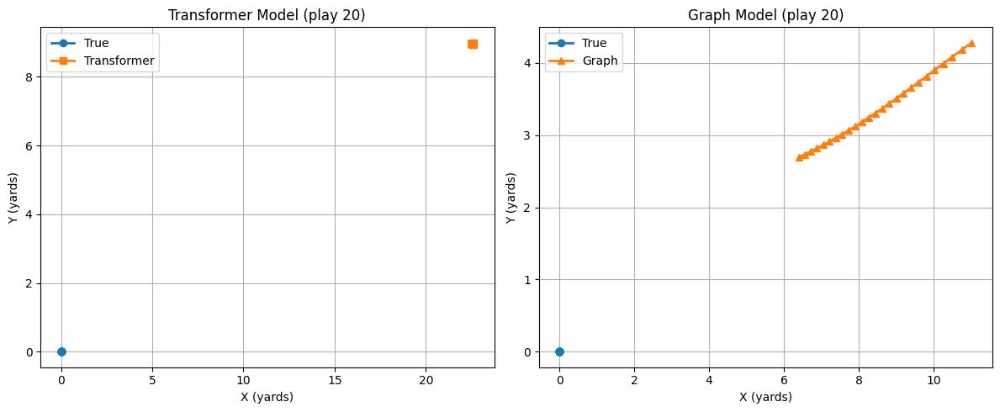

Target player 5 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.1 yards
Graph pred: X range = 4.6 yards


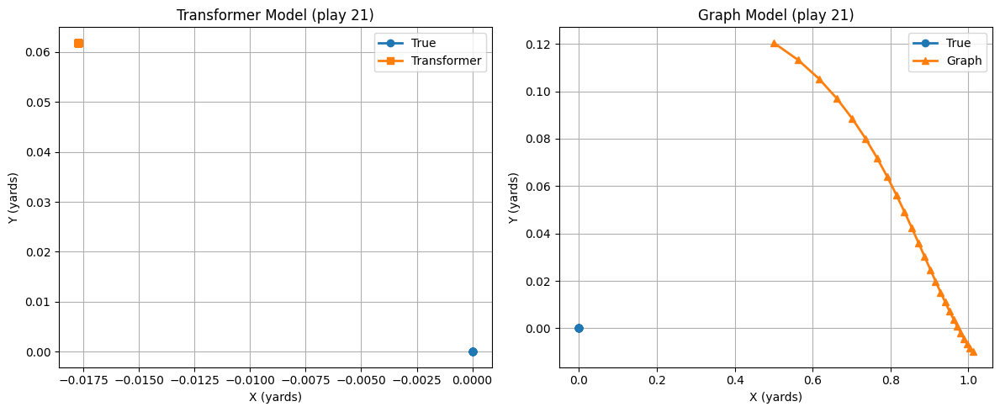

Target player 10 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 0.5 yards


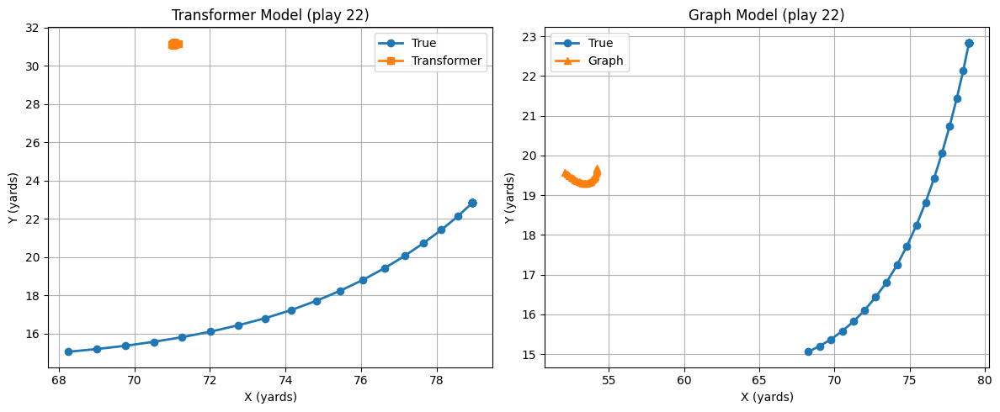

Target player 2 movement analysis:
True trajectory: X range = 10.7 yards
Transformer pred: X range = 0.2 yards
Graph pred: X range = 2.1 yards


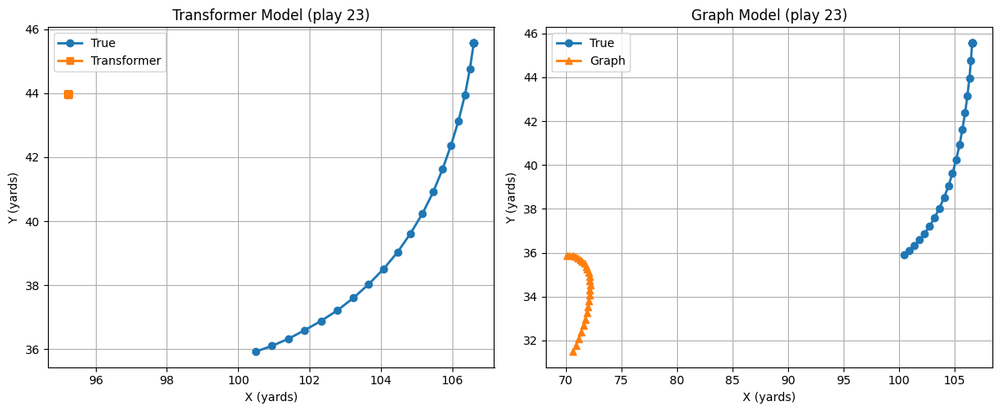

Target player 2 movement analysis:
True trajectory: X range = 6.1 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 2.1 yards


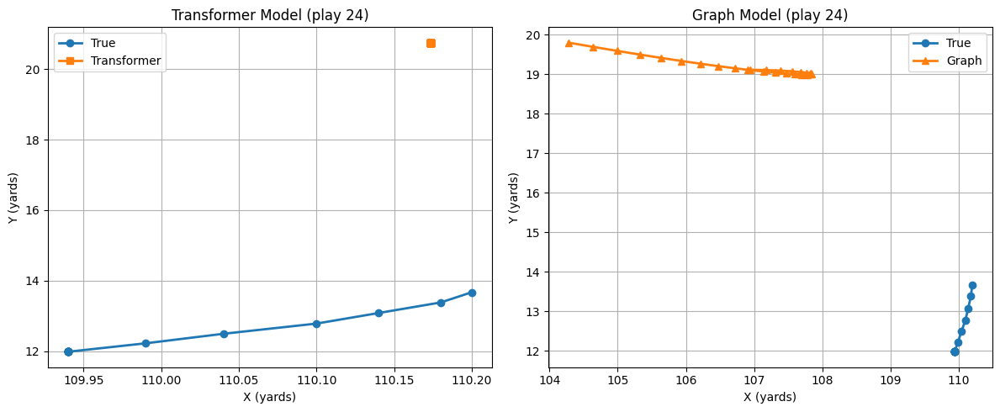

Target player 1 movement analysis:
True trajectory: X range = 0.3 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 3.6 yards


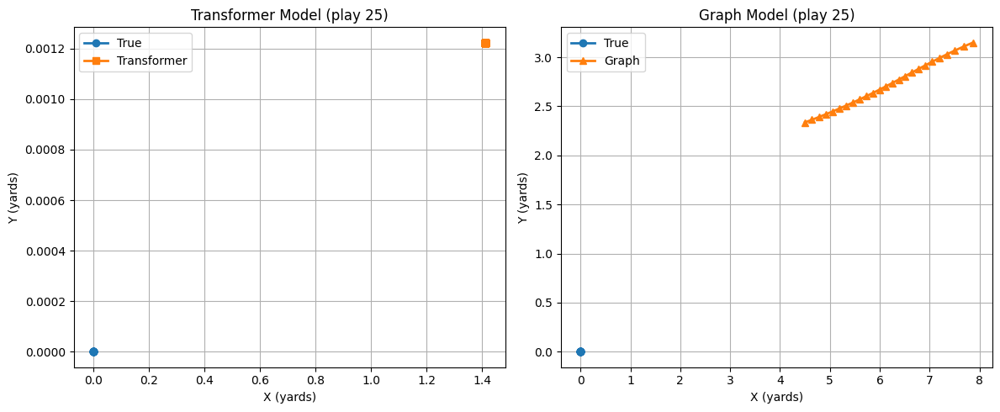

Target player 5 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 3.4 yards


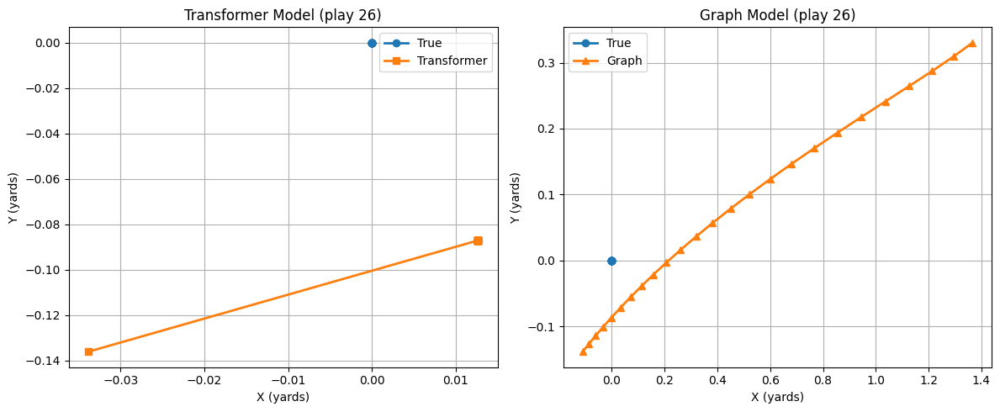

Target player 12 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 1.5 yards


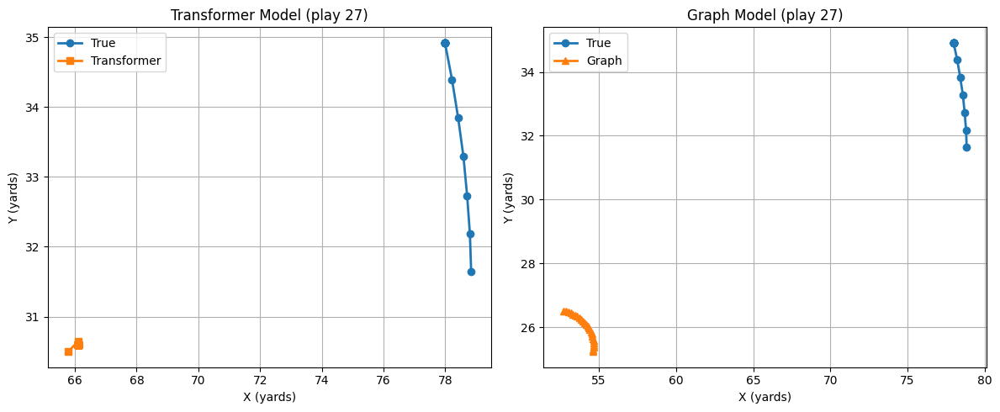

Target player 2 movement analysis:
True trajectory: X range = 0.9 yards
Transformer pred: X range = 0.3 yards
Graph pred: X range = 2.0 yards


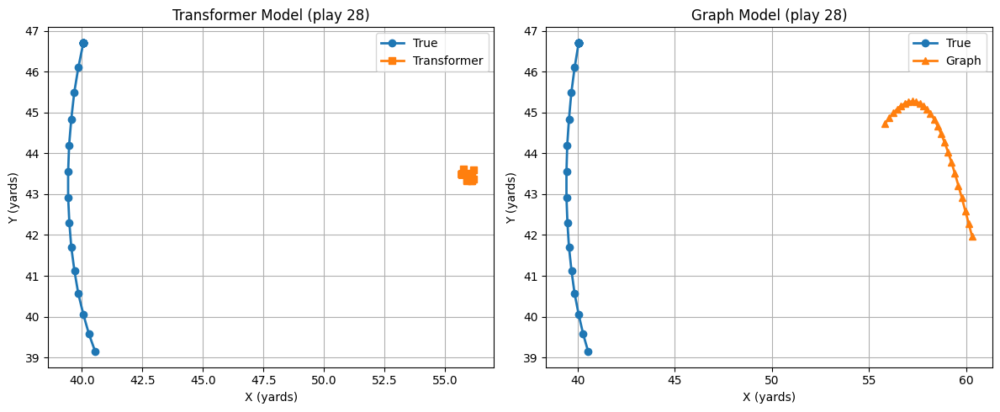

Target player 0 movement analysis:
True trajectory: X range = 1.1 yards
Transformer pred: X range = 0.5 yards
Graph pred: X range = 4.5 yards


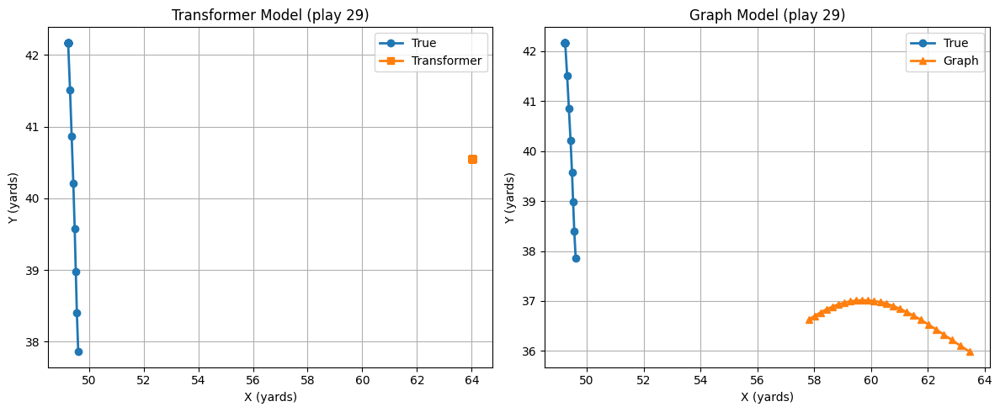

Target player 0 movement analysis:
True trajectory: X range = 0.4 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 5.7 yards


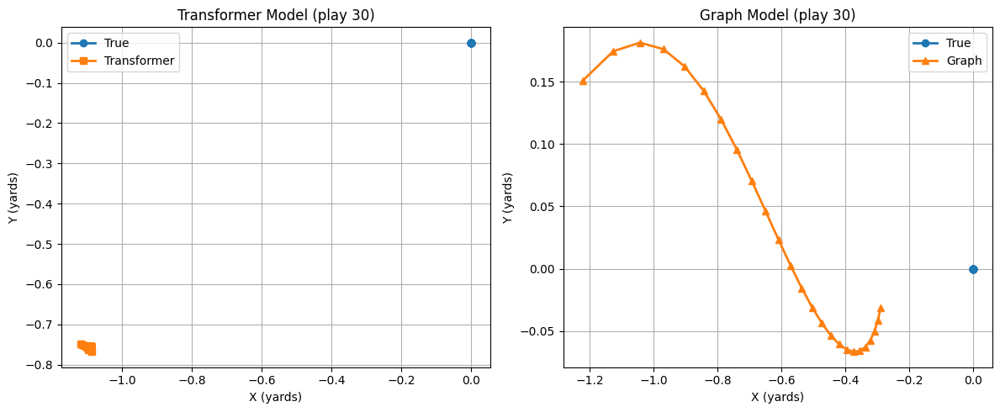

Target player 7 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 0.9 yards


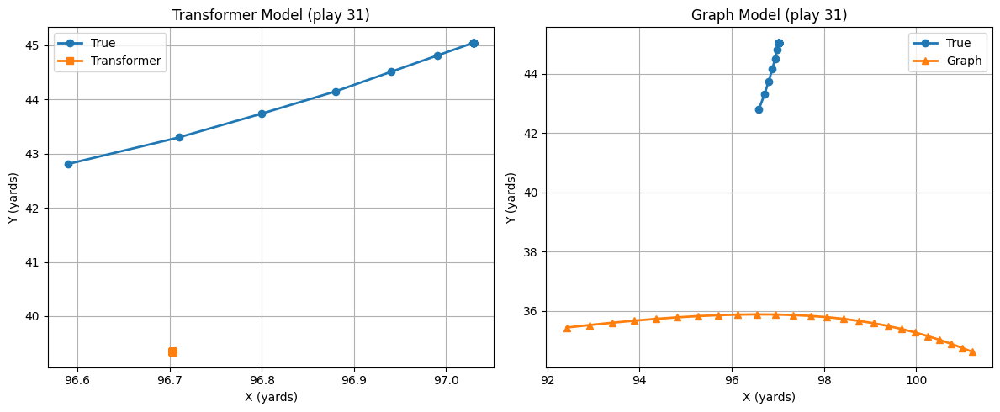

Target player 0 movement analysis:
True trajectory: X range = 0.4 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 8.8 yards


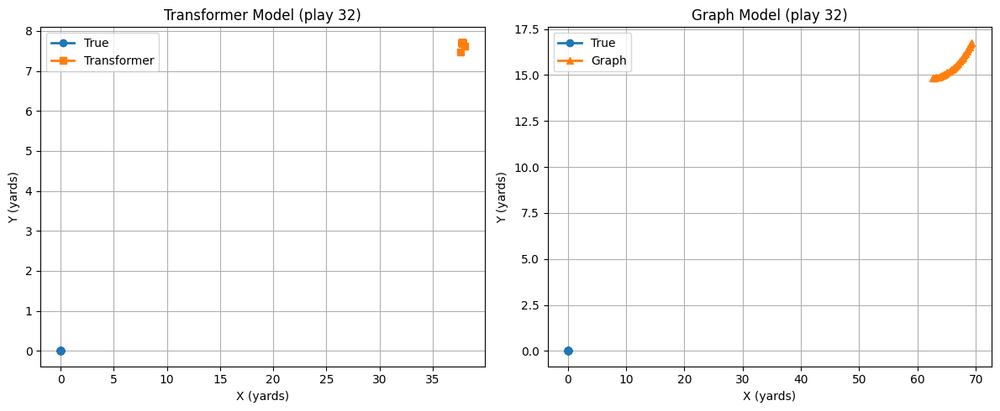

Target player 3 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.4 yards
Graph pred: X range = 6.6 yards


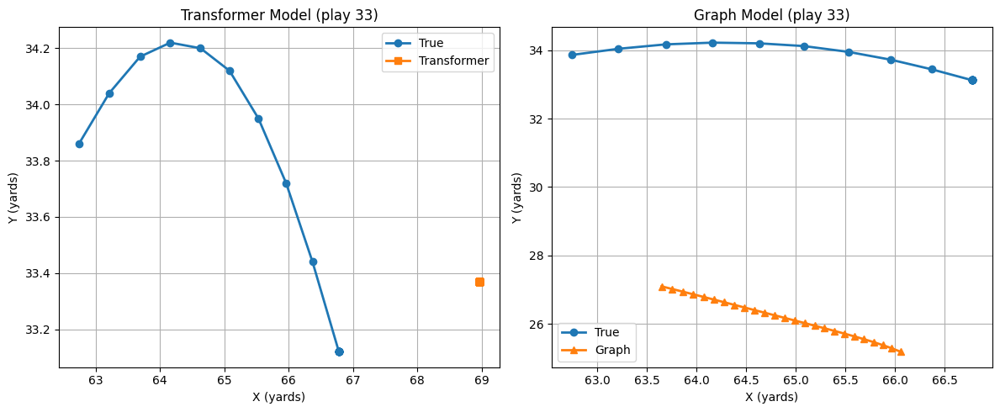

Target player 1 movement analysis:
True trajectory: X range = 4.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 2.4 yards


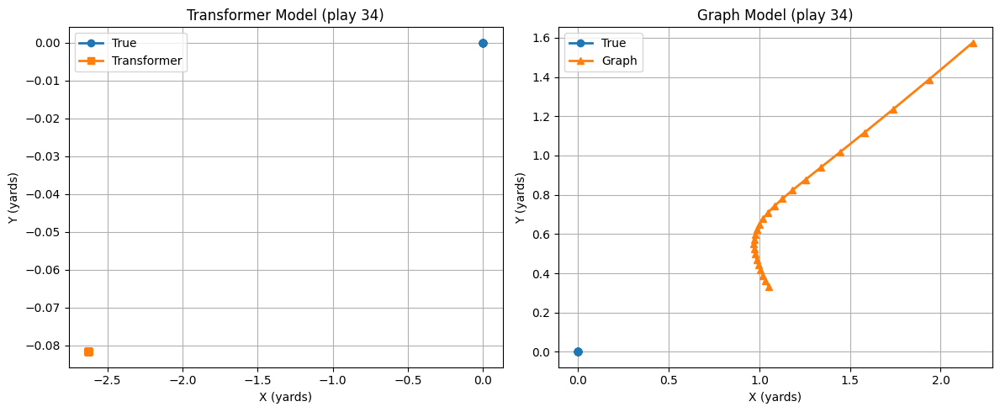

Target player 6 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 1.2 yards


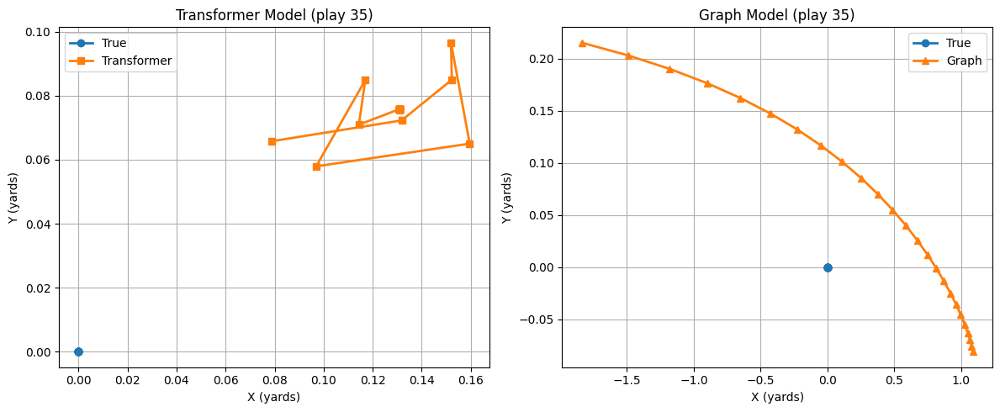

Target player 10 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.1 yards
Graph pred: X range = 2.9 yards


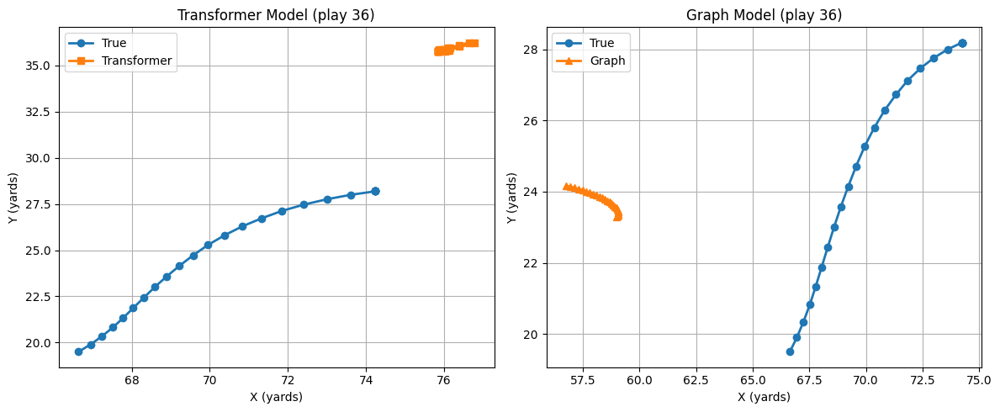

Target player 2 movement analysis:
True trajectory: X range = 7.6 yards
Transformer pred: X range = 0.9 yards
Graph pred: X range = 2.3 yards


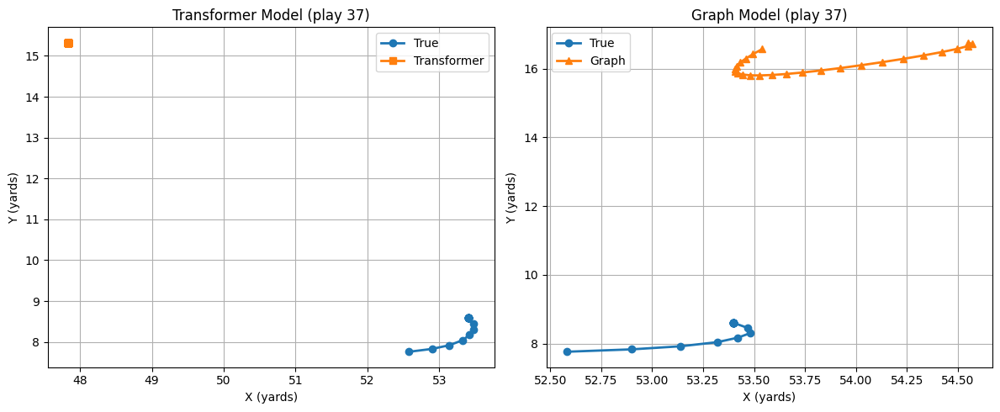

Target player 1 movement analysis:
True trajectory: X range = 0.9 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 1.2 yards


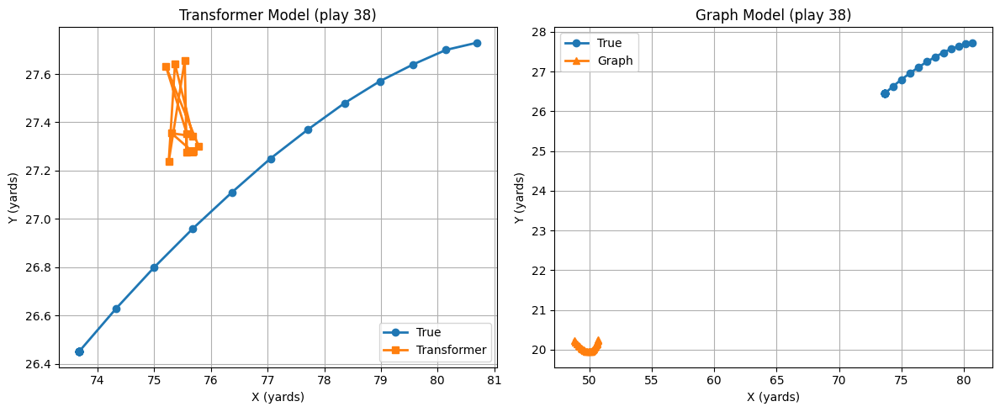

Target player 2 movement analysis:
True trajectory: X range = 7.0 yards
Transformer pred: X range = 0.6 yards
Graph pred: X range = 1.9 yards


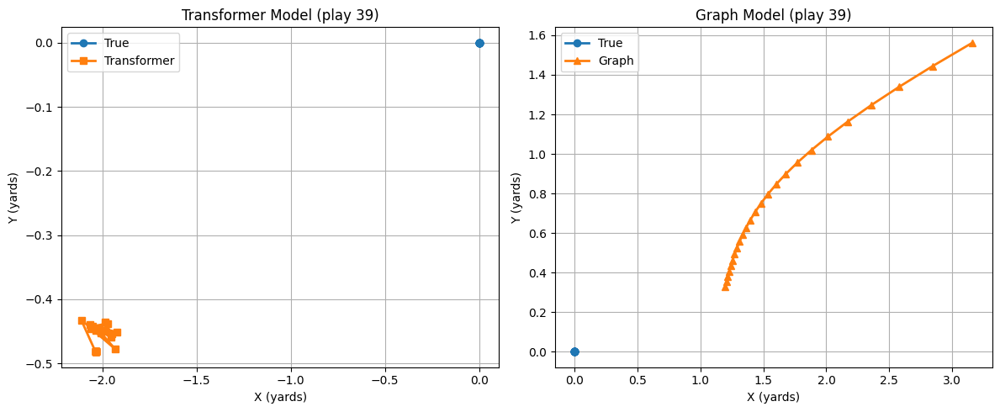

Target player 6 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.2 yards
Graph pred: X range = 2.0 yards


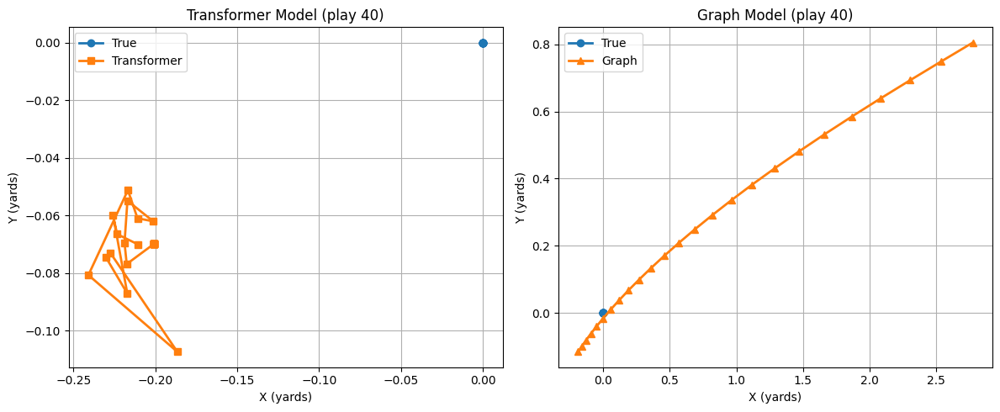

Target player 12 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.1 yards
Graph pred: X range = 3.0 yards


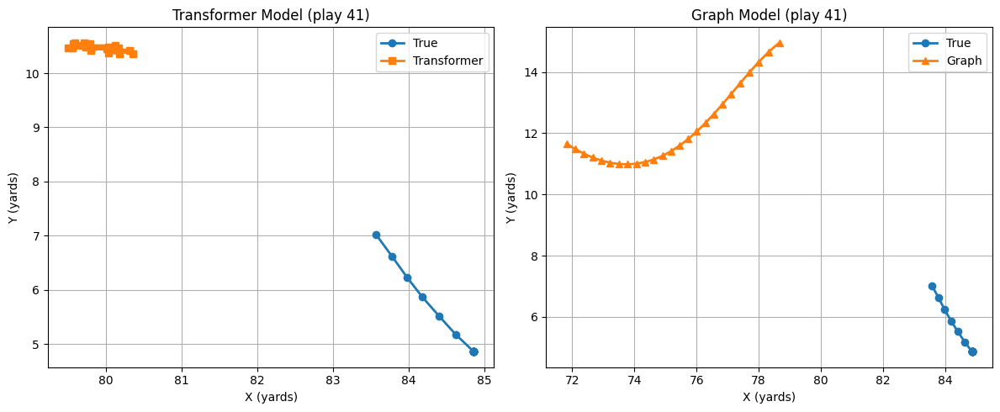

Target player 0 movement analysis:
True trajectory: X range = 1.3 yards
Transformer pred: X range = 0.9 yards
Graph pred: X range = 6.8 yards


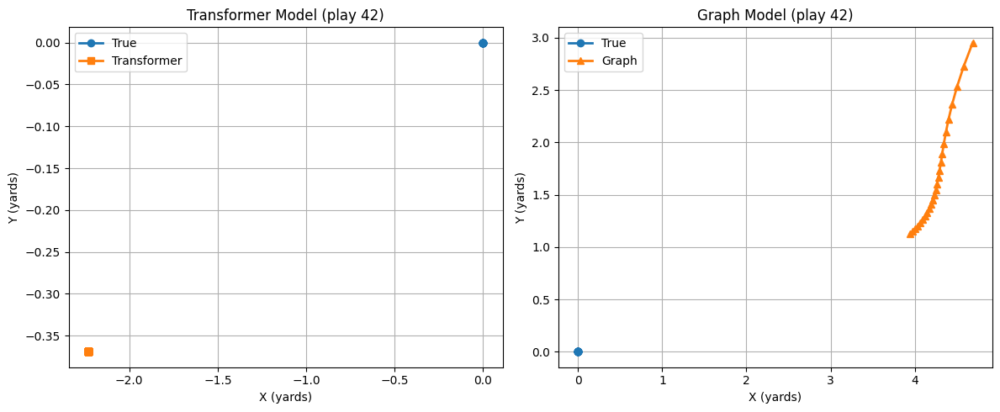

Target player 6 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 0.7 yards


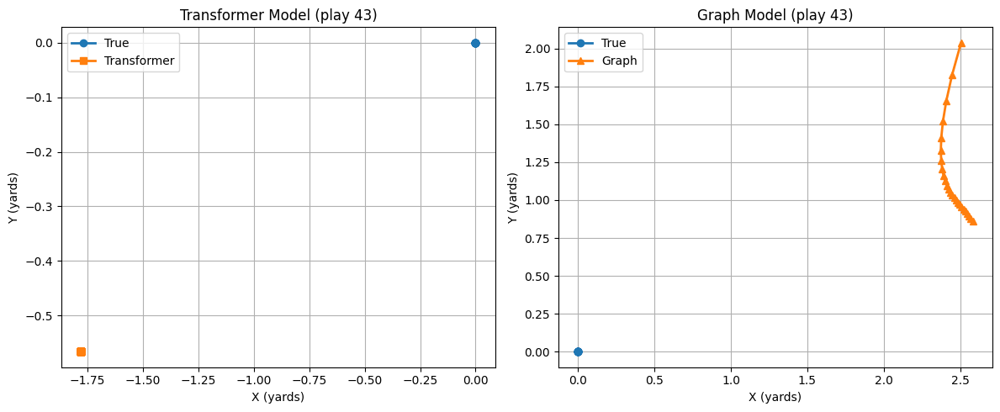

Target player 6 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 0.2 yards


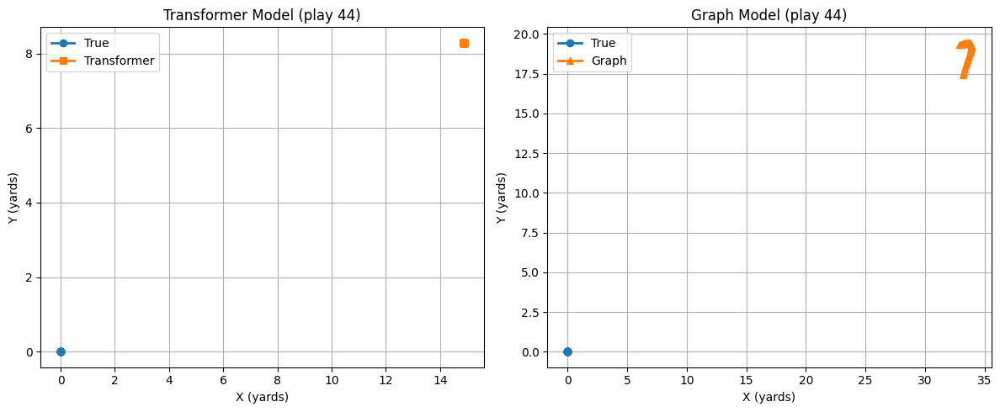

Target player 3 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 1.0 yards


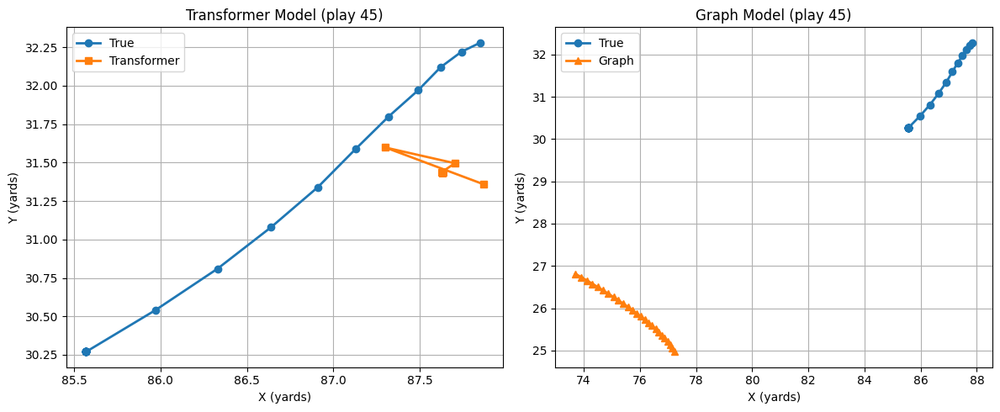

Target player 1 movement analysis:
True trajectory: X range = 2.3 yards
Transformer pred: X range = 0.6 yards
Graph pred: X range = 3.5 yards


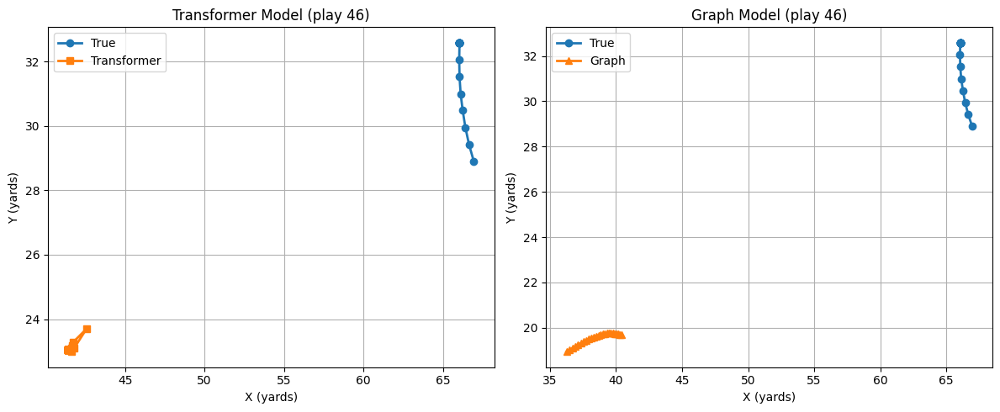

Target player 3 movement analysis:
True trajectory: X range = 0.9 yards
Transformer pred: X range = 1.2 yards
Graph pred: X range = 4.2 yards


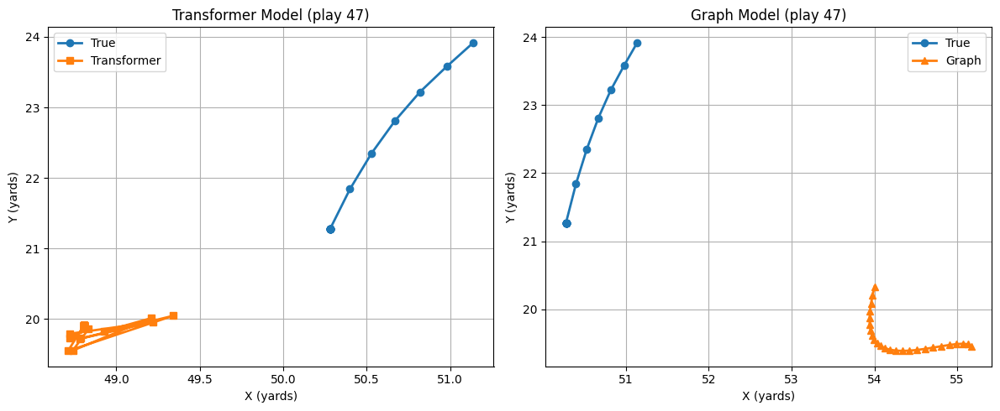

Target player 1 movement analysis:
True trajectory: X range = 0.9 yards
Transformer pred: X range = 0.6 yards
Graph pred: X range = 1.2 yards


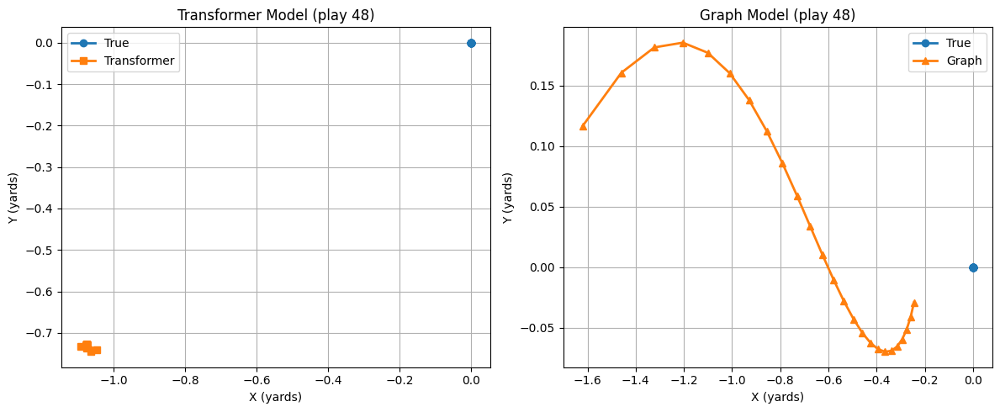

Target player 7 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 1.4 yards


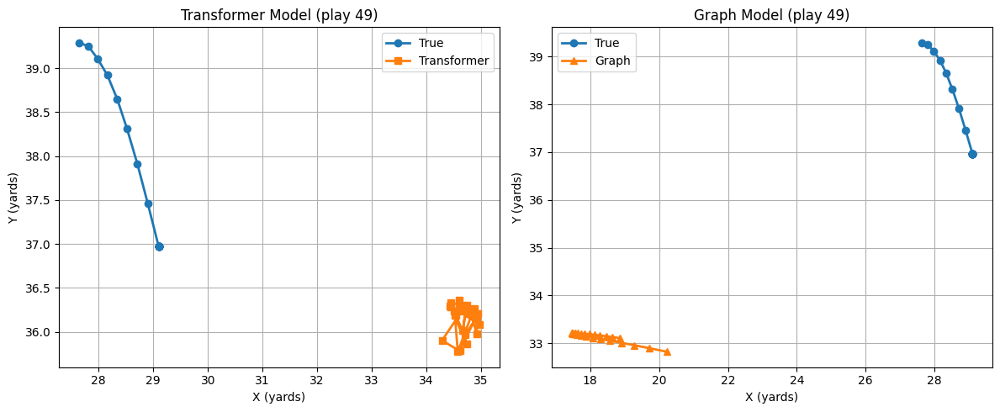

Target player 0 movement analysis:
True trajectory: X range = 1.5 yards
Transformer pred: X range = 0.7 yards
Graph pred: X range = 2.8 yards


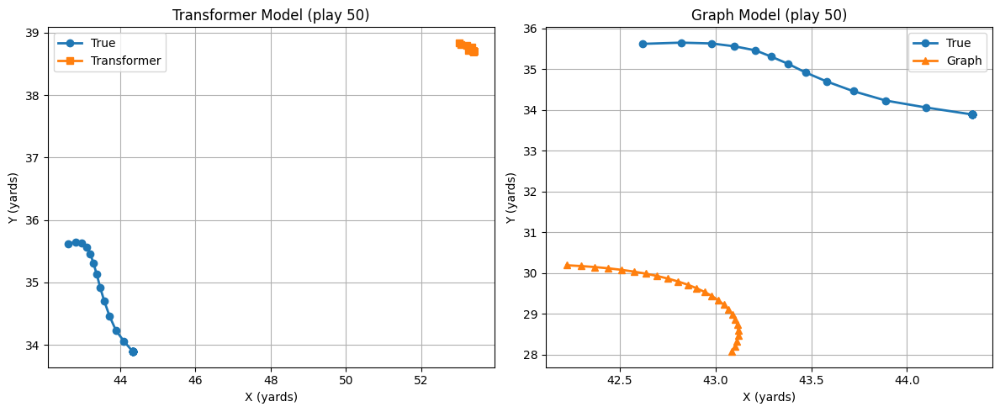

Target player 2 movement analysis:
True trajectory: X range = 1.7 yards
Transformer pred: X range = 0.4 yards
Graph pred: X range = 0.9 yards


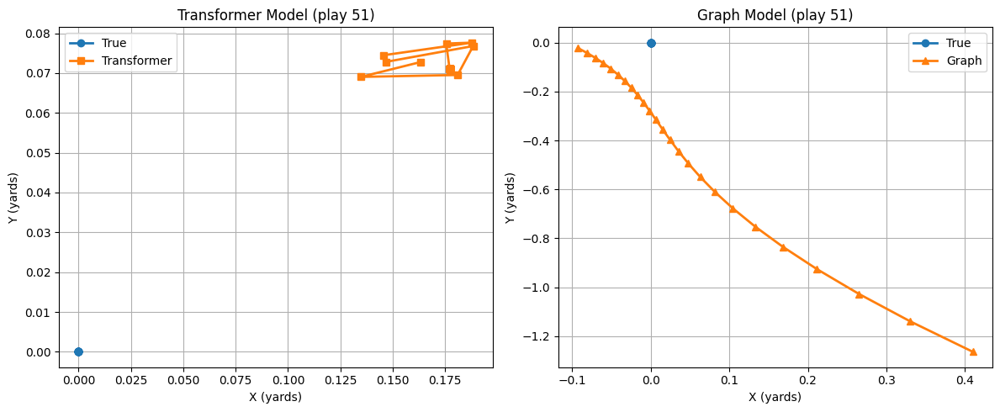

Target player 9 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.1 yards
Graph pred: X range = 0.5 yards


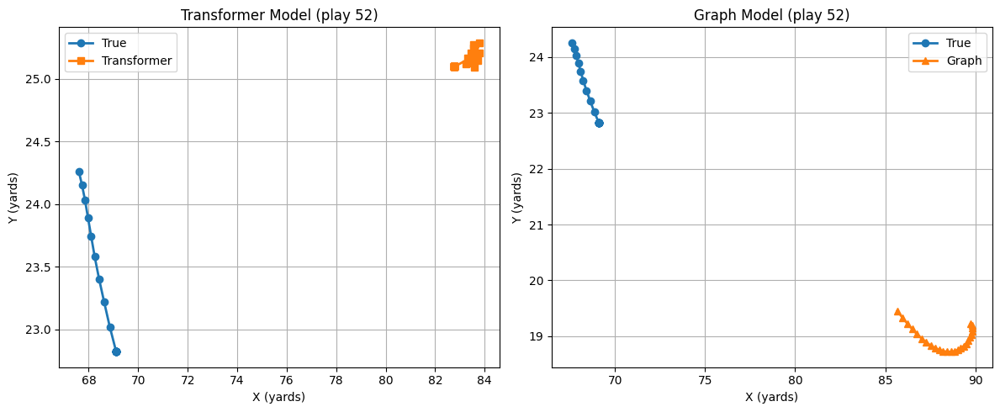

Target player 1 movement analysis:
True trajectory: X range = 1.5 yards
Transformer pred: X range = 1.0 yards
Graph pred: X range = 4.2 yards


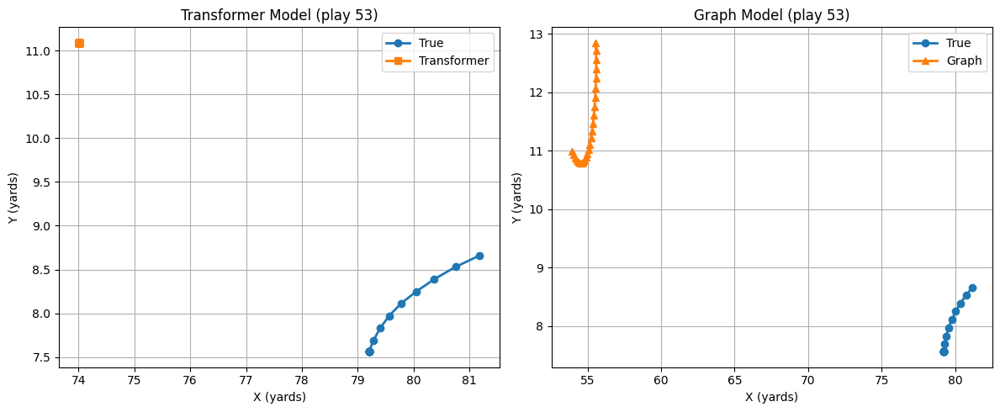

Target player 2 movement analysis:
True trajectory: X range = 2.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 1.7 yards


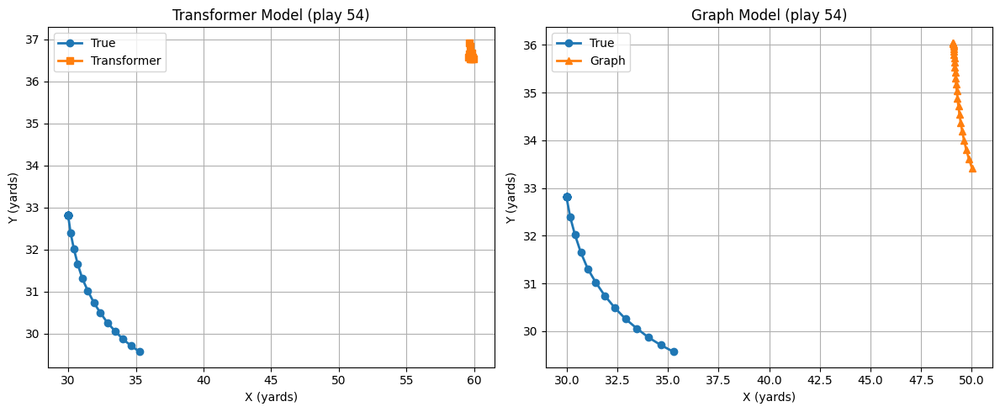

Target player 1 movement analysis:
True trajectory: X range = 5.3 yards
Transformer pred: X range = 0.4 yards
Graph pred: X range = 1.0 yards


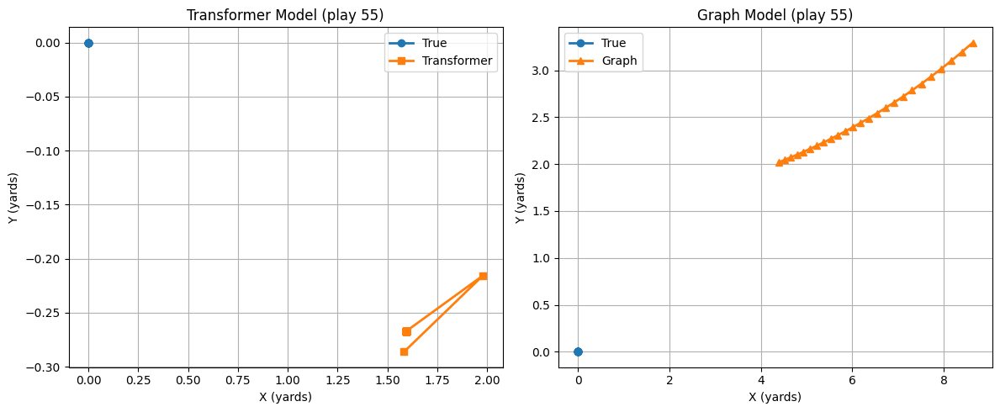

Target player 5 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.4 yards
Graph pred: X range = 4.2 yards


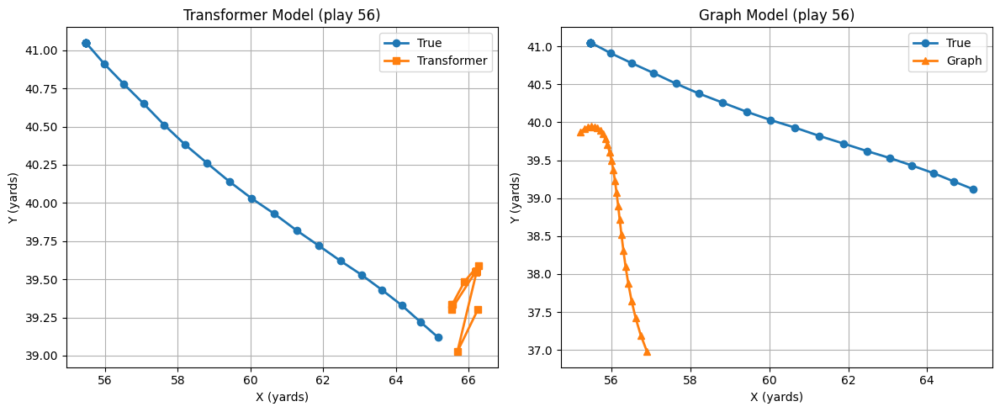

Target player 1 movement analysis:
True trajectory: X range = 9.7 yards
Transformer pred: X range = 0.7 yards
Graph pred: X range = 1.7 yards


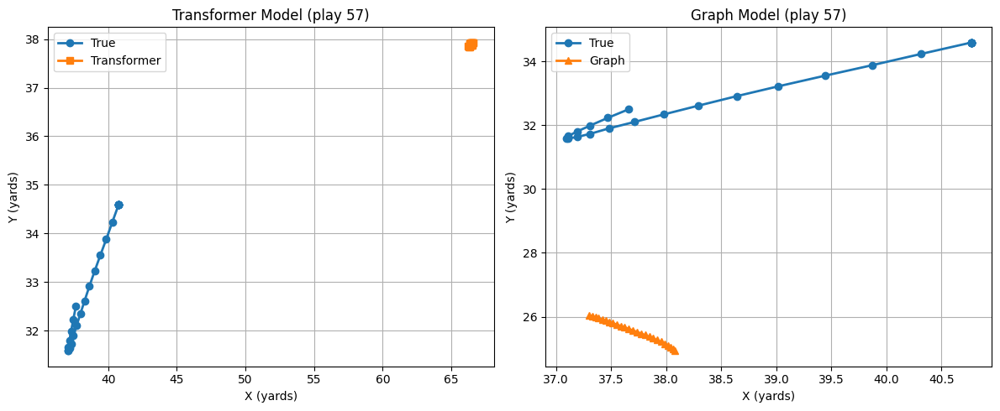

Target player 2 movement analysis:
True trajectory: X range = 3.7 yards
Transformer pred: X range = 0.4 yards
Graph pred: X range = 0.8 yards


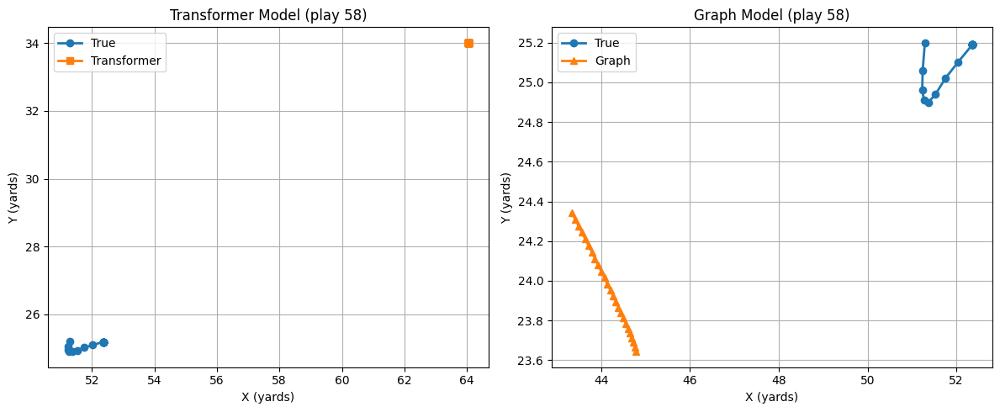

Target player 2 movement analysis:
True trajectory: X range = 1.1 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 1.4 yards


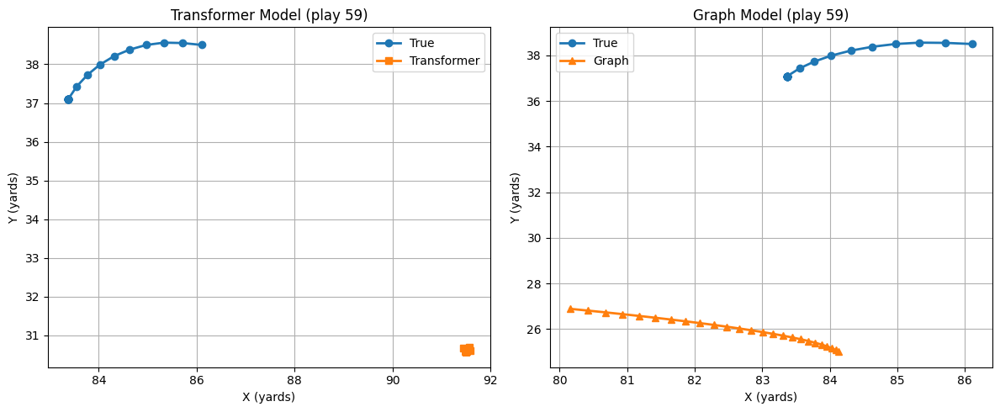

Target player 1 movement analysis:
True trajectory: X range = 2.7 yards
Transformer pred: X range = 0.1 yards
Graph pred: X range = 4.0 yards


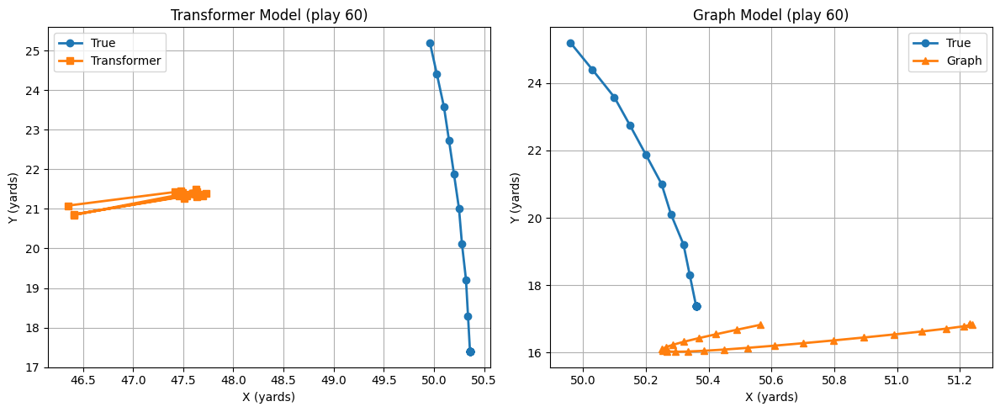

Target player 1 movement analysis:
True trajectory: X range = 0.4 yards
Transformer pred: X range = 1.4 yards
Graph pred: X range = 1.0 yards


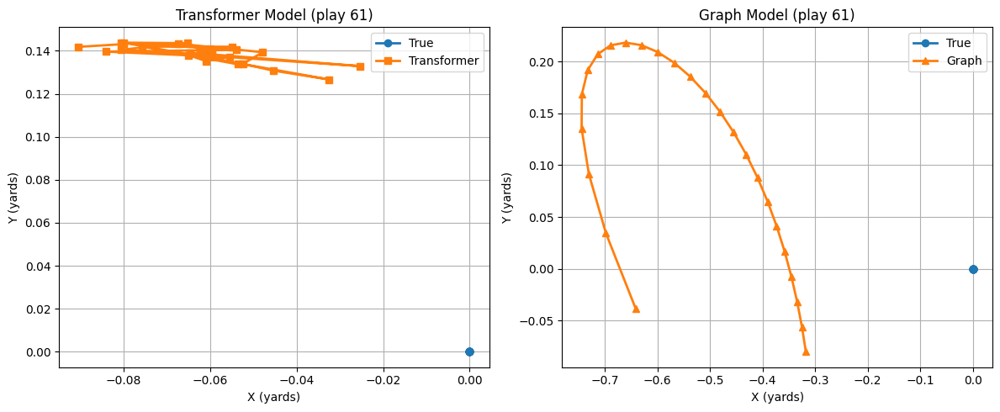

Target player 9 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.1 yards
Graph pred: X range = 0.4 yards


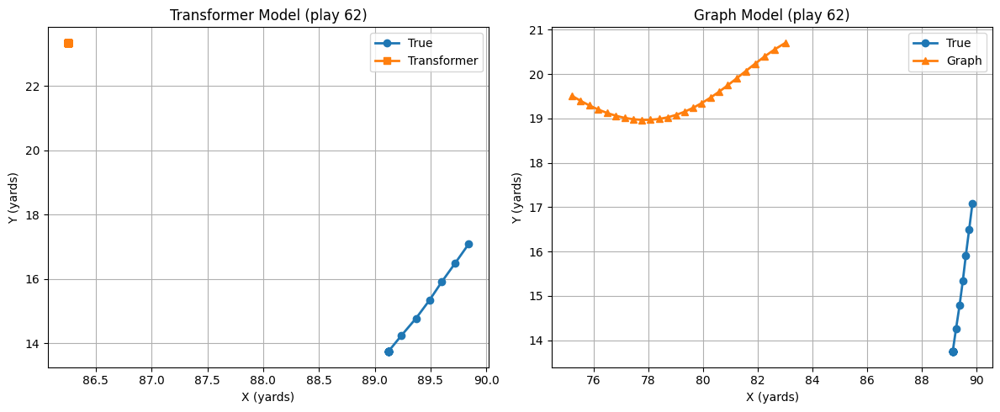

Target player 0 movement analysis:
True trajectory: X range = 0.7 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 7.8 yards


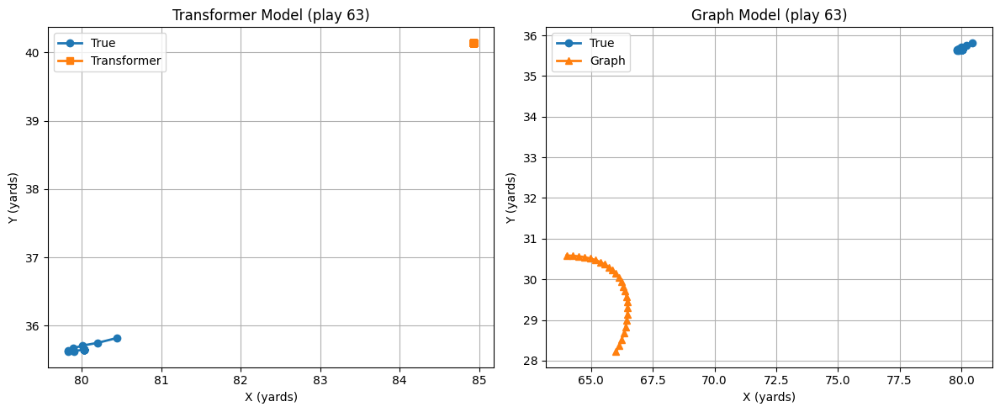

Target player 2 movement analysis:
True trajectory: X range = 0.6 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 2.5 yards


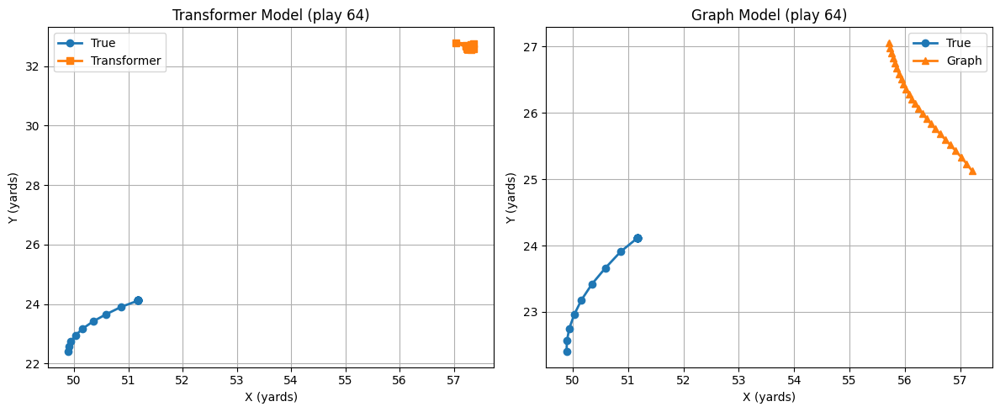

Target player 1 movement analysis:
True trajectory: X range = 1.3 yards
Transformer pred: X range = 0.3 yards
Graph pred: X range = 1.5 yards


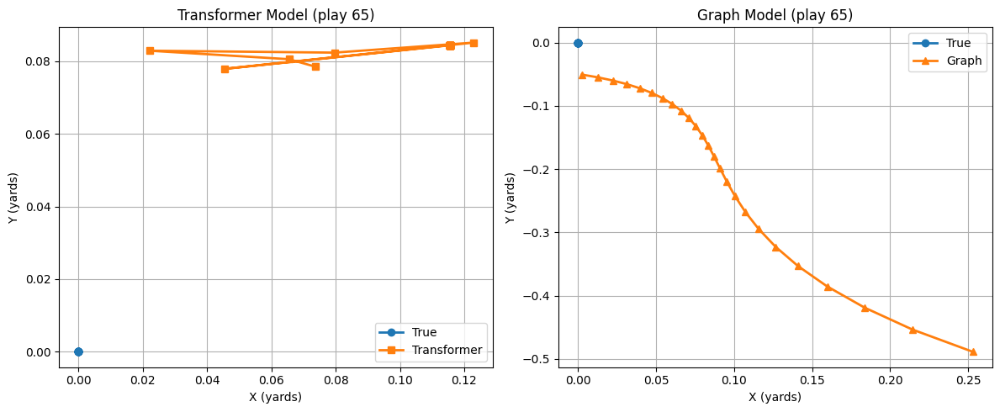

Target player 9 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.1 yards
Graph pred: X range = 0.3 yards


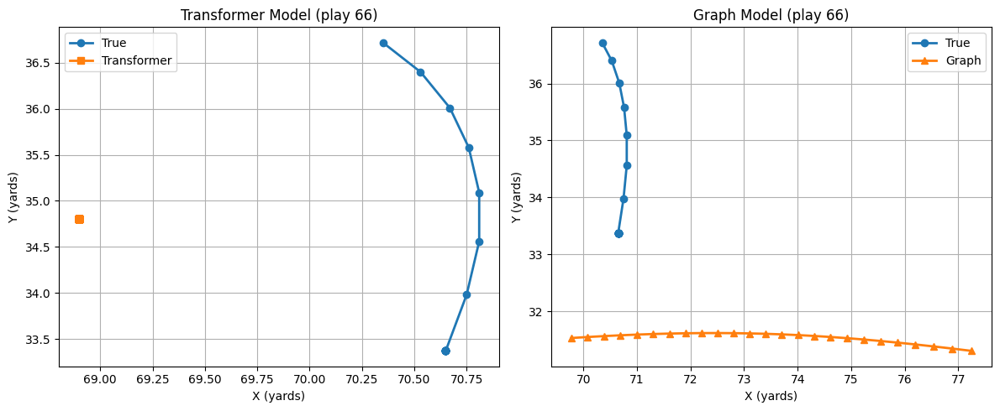

Target player 0 movement analysis:
True trajectory: X range = 0.5 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 7.5 yards


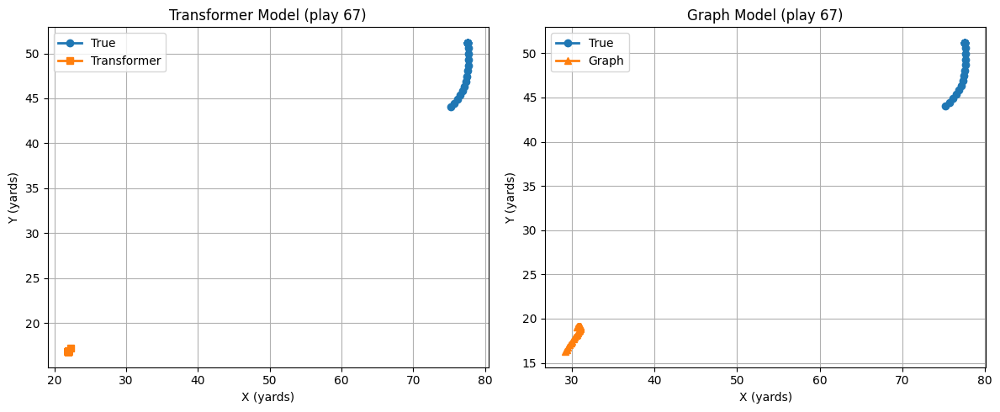

Target player 3 movement analysis:
True trajectory: X range = 2.4 yards
Transformer pred: X range = 0.4 yards
Graph pred: X range = 1.8 yards


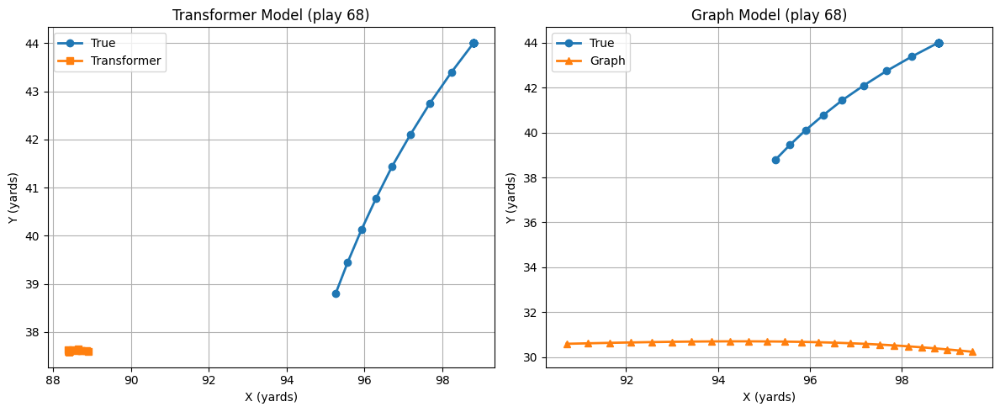

Target player 0 movement analysis:
True trajectory: X range = 3.5 yards
Transformer pred: X range = 0.5 yards
Graph pred: X range = 8.8 yards


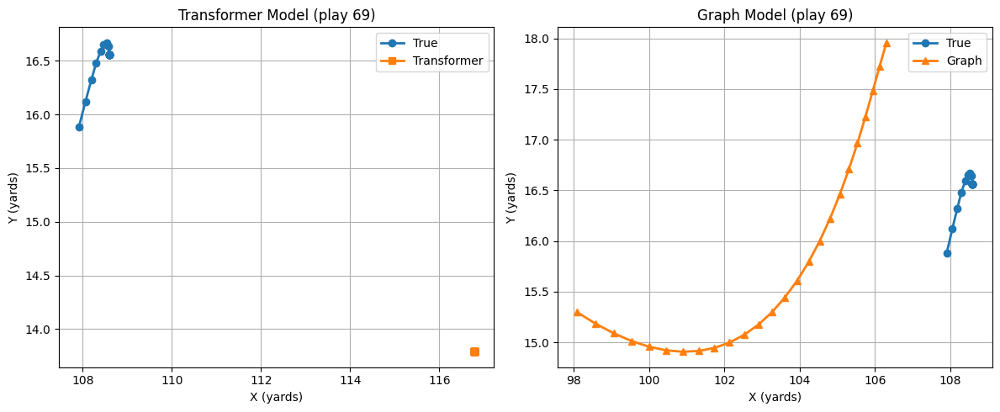

Target player 0 movement analysis:
True trajectory: X range = 0.7 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 8.2 yards


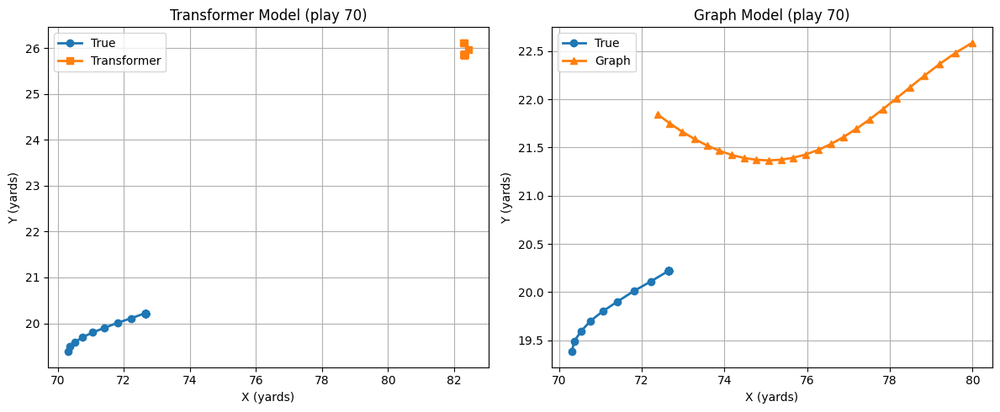

Target player 0 movement analysis:
True trajectory: X range = 2.3 yards
Transformer pred: X range = 0.2 yards
Graph pred: X range = 7.6 yards


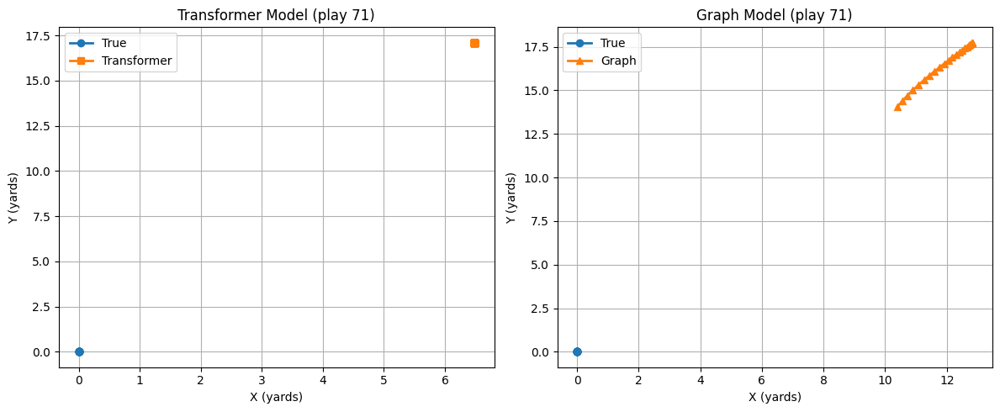

Target player 3 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 2.4 yards


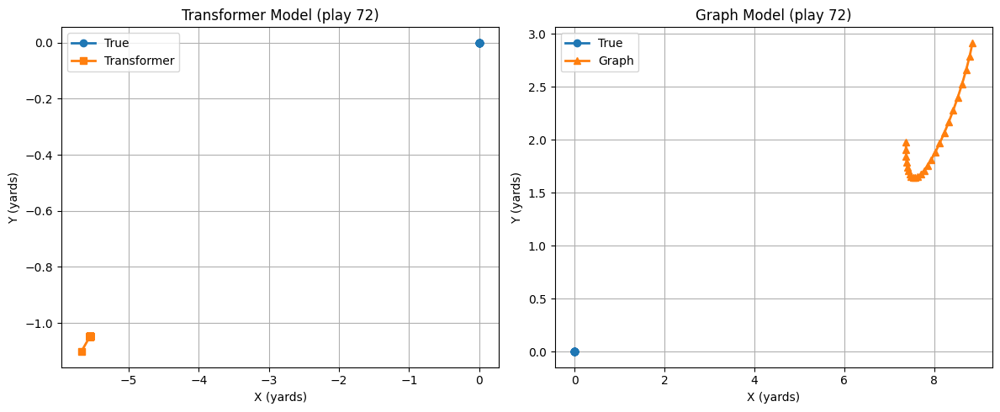

Target player 4 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.1 yards
Graph pred: X range = 1.5 yards


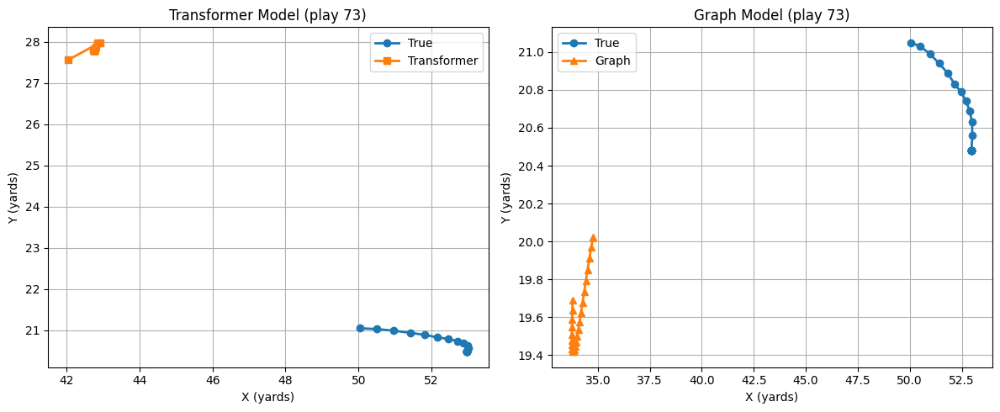

Target player 2 movement analysis:
True trajectory: X range = 3.0 yards
Transformer pred: X range = 0.9 yards
Graph pred: X range = 1.0 yards


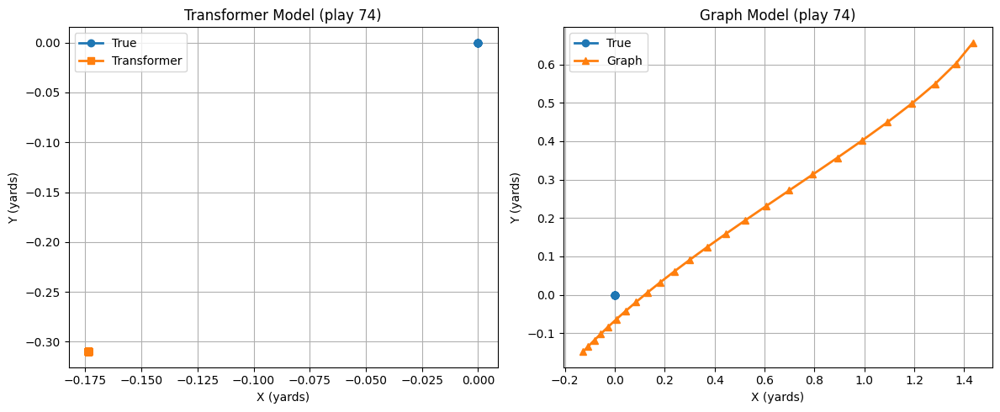

Target player 12 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 1.6 yards


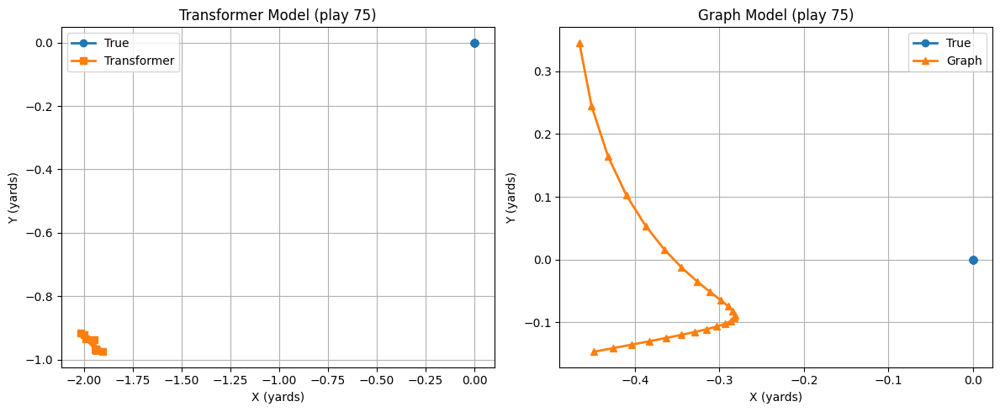

Target player 7 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.1 yards
Graph pred: X range = 0.2 yards


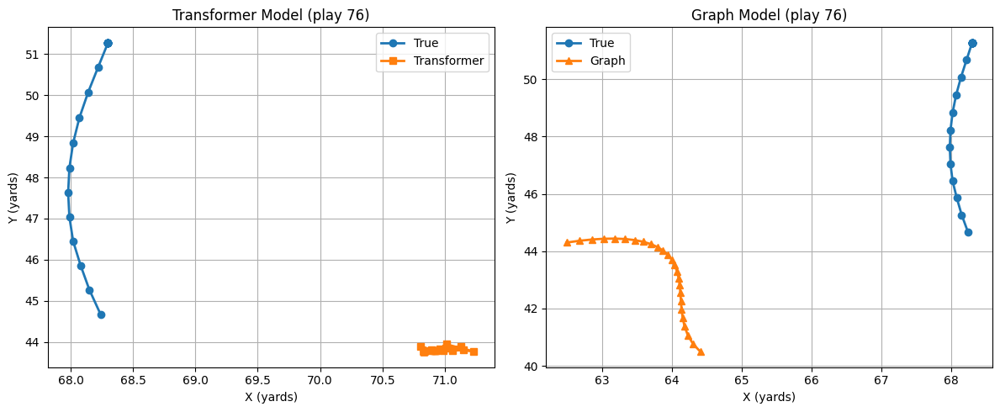

Target player 1 movement analysis:
True trajectory: X range = 0.3 yards
Transformer pred: X range = 0.4 yards
Graph pred: X range = 1.9 yards


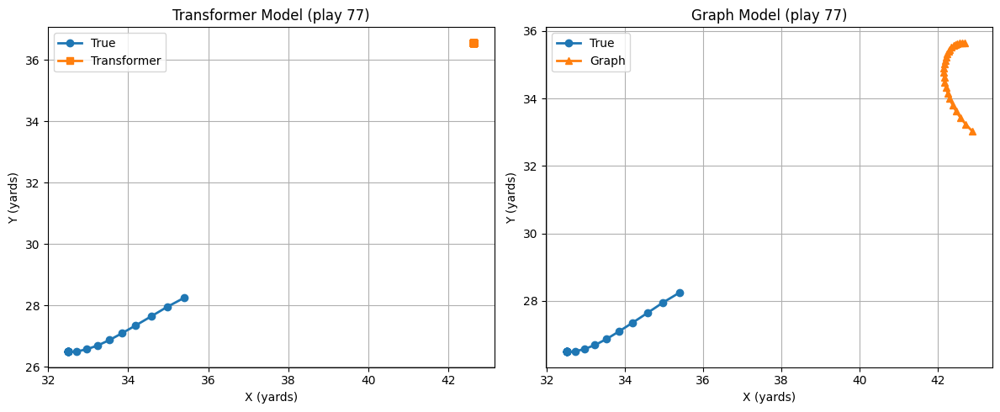

Target player 1 movement analysis:
True trajectory: X range = 2.9 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 0.7 yards


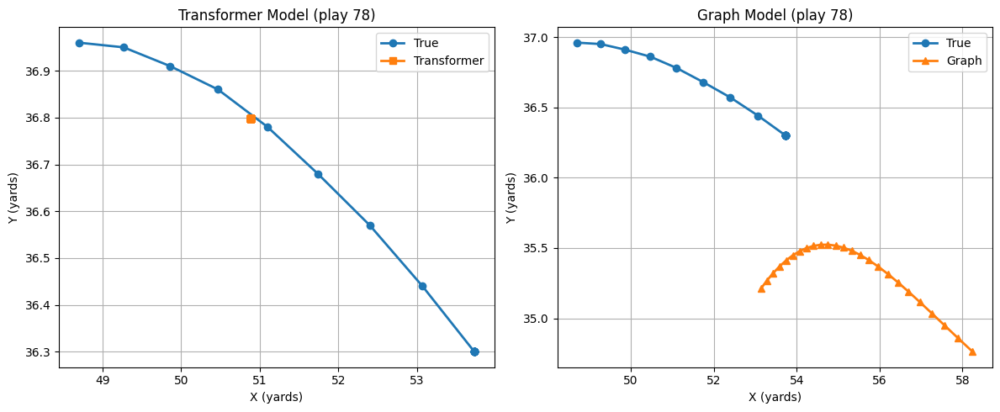

Target player 0 movement analysis:
True trajectory: X range = 5.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 5.1 yards


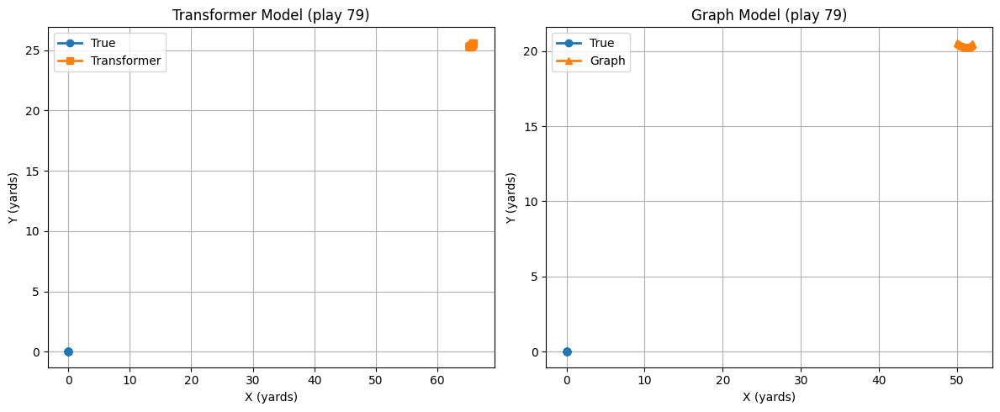

Target player 2 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.8 yards
Graph pred: X range = 2.0 yards


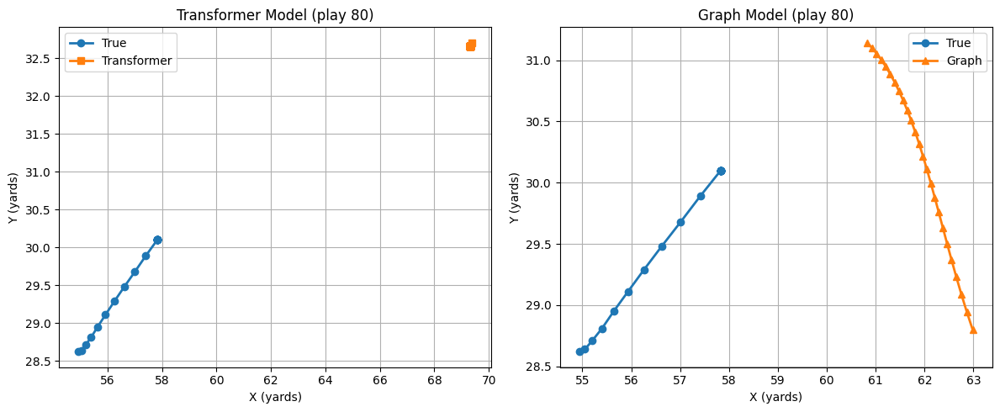

Target player 1 movement analysis:
True trajectory: X range = 2.9 yards
Transformer pred: X range = 0.1 yards
Graph pred: X range = 2.2 yards


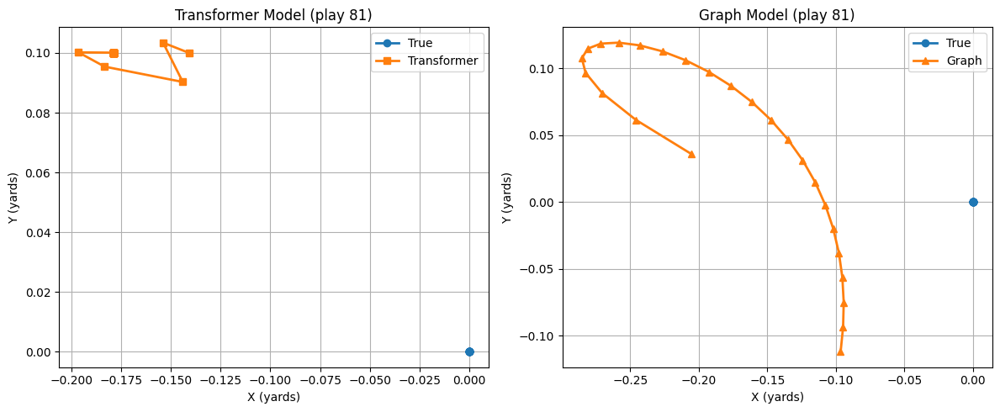

Target player 9 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.1 yards
Graph pred: X range = 0.2 yards


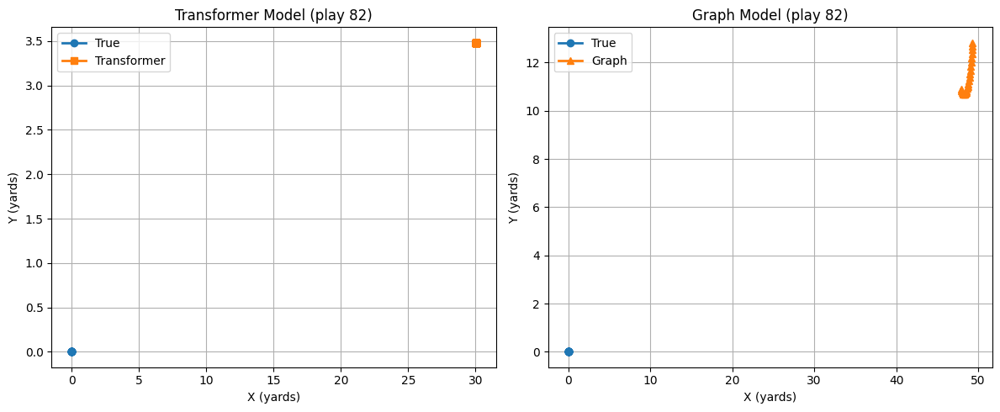

Target player 2 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 1.4 yards


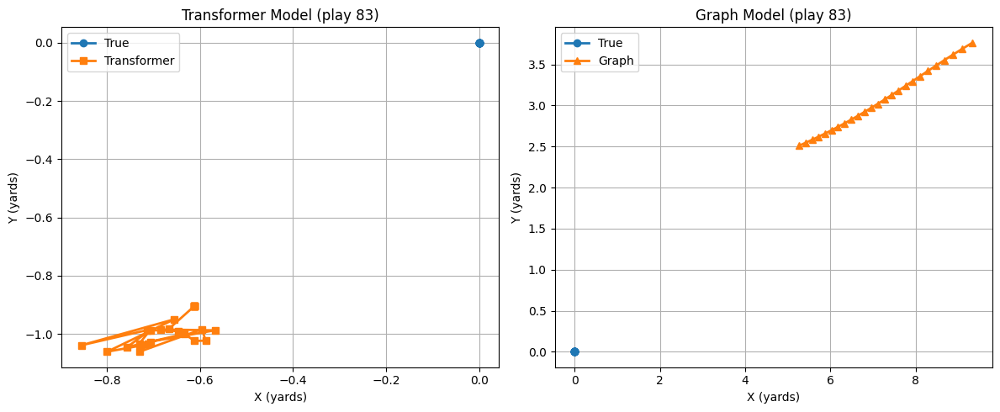

Target player 5 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.3 yards
Graph pred: X range = 4.1 yards


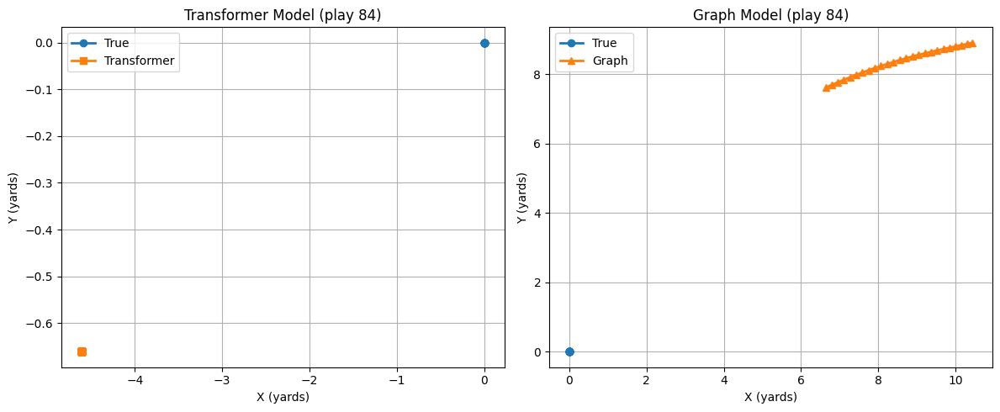

Target player 4 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 3.8 yards


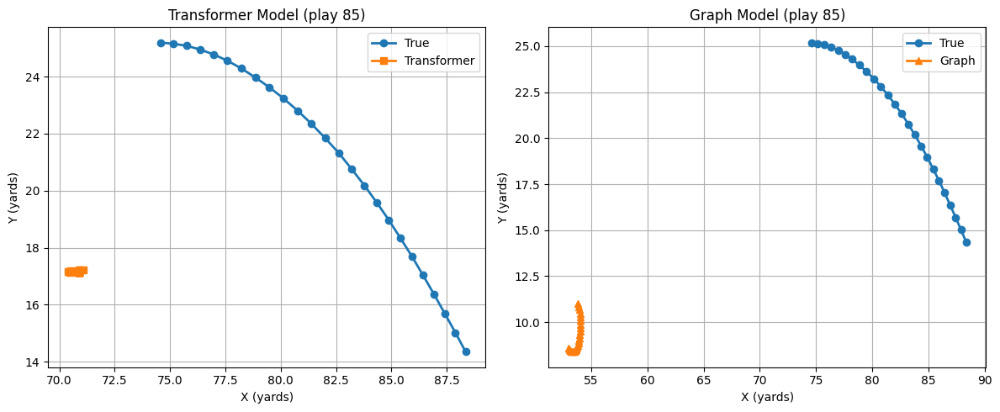

Target player 2 movement analysis:
True trajectory: X range = 13.8 yards
Transformer pred: X range = 0.7 yards
Graph pred: X range = 1.1 yards


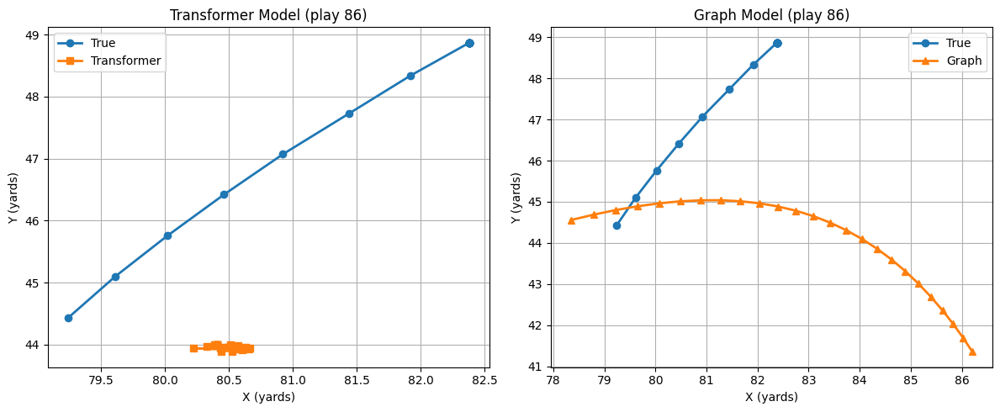

Target player 0 movement analysis:
True trajectory: X range = 3.1 yards
Transformer pred: X range = 0.4 yards
Graph pred: X range = 7.9 yards


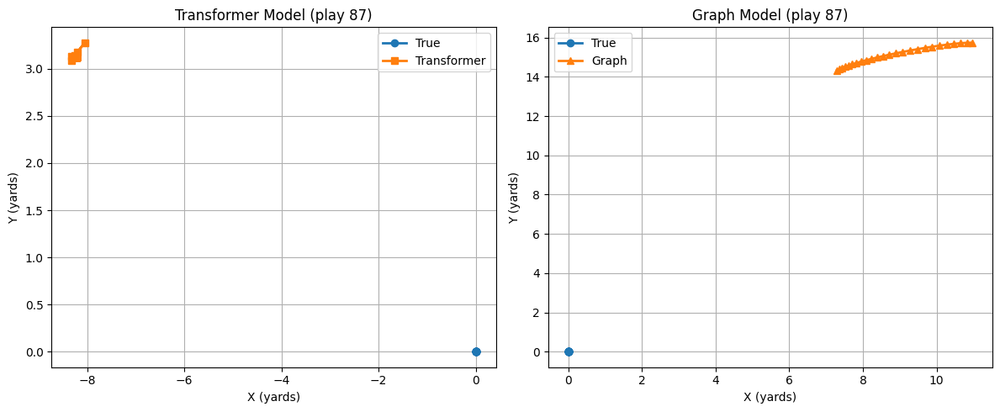

Target player 3 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.3 yards
Graph pred: X range = 3.7 yards


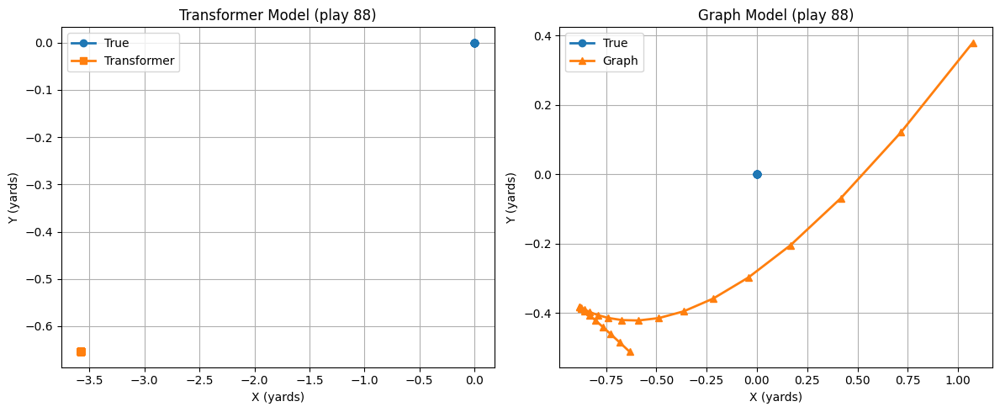

Target player 6 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 2.0 yards


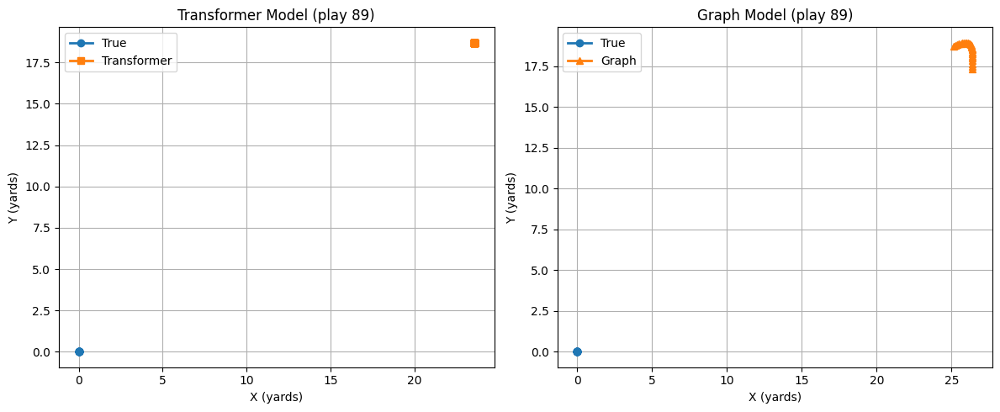

Target player 3 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 1.3 yards


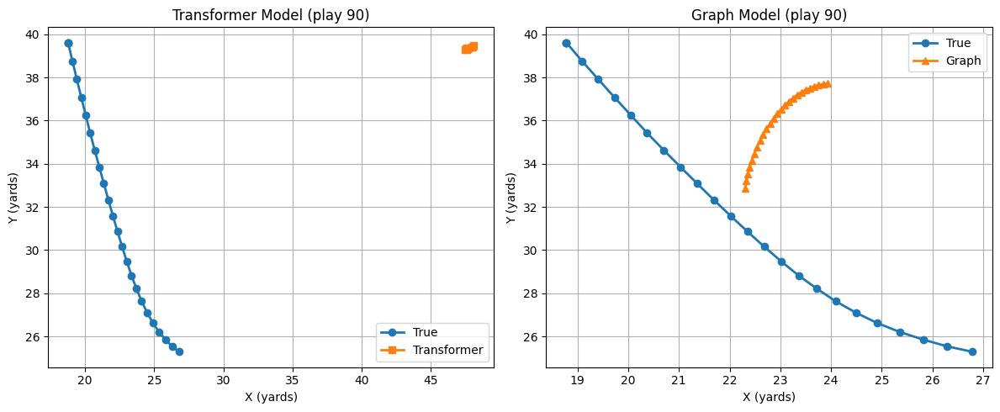

Target player 2 movement analysis:
True trajectory: X range = 8.0 yards
Transformer pred: X range = 0.6 yards
Graph pred: X range = 1.6 yards


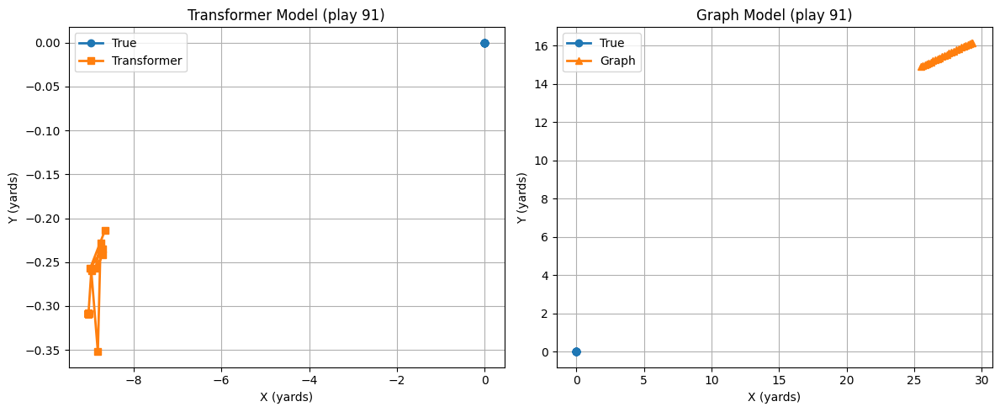

Target player 3 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.4 yards
Graph pred: X range = 3.8 yards


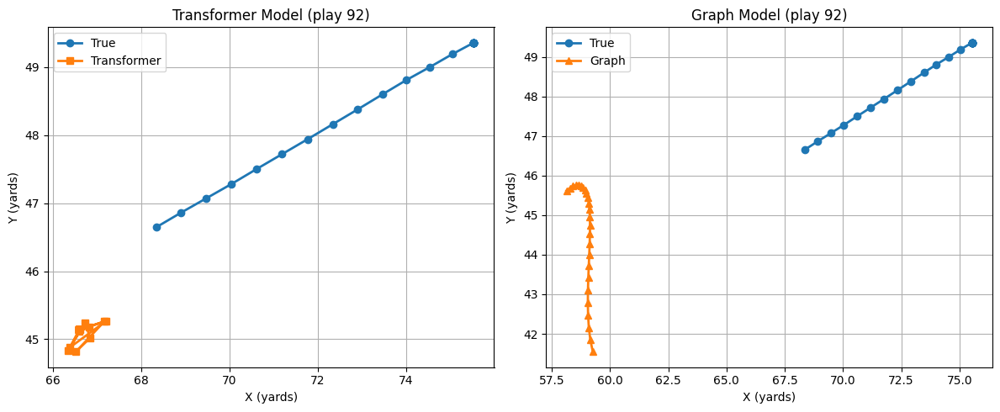

Target player 1 movement analysis:
True trajectory: X range = 7.2 yards
Transformer pred: X range = 0.9 yards
Graph pred: X range = 1.1 yards


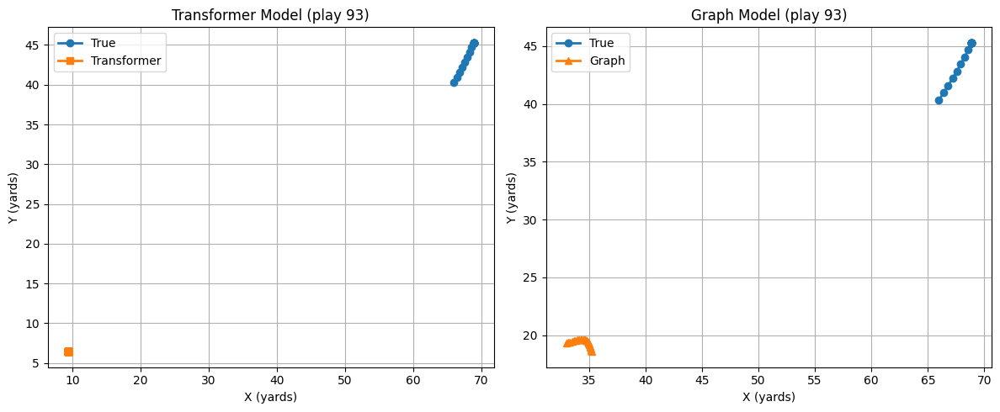

Target player 3 movement analysis:
True trajectory: X range = 2.9 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 2.2 yards


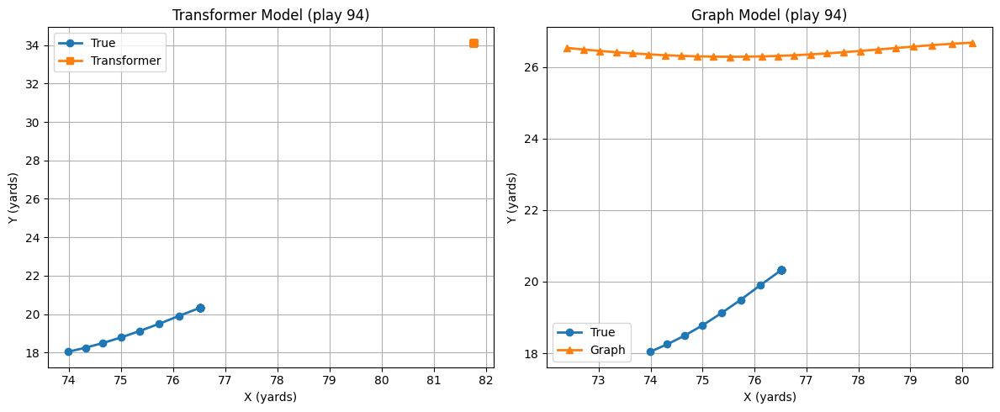

Target player 0 movement analysis:
True trajectory: X range = 2.5 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 7.8 yards


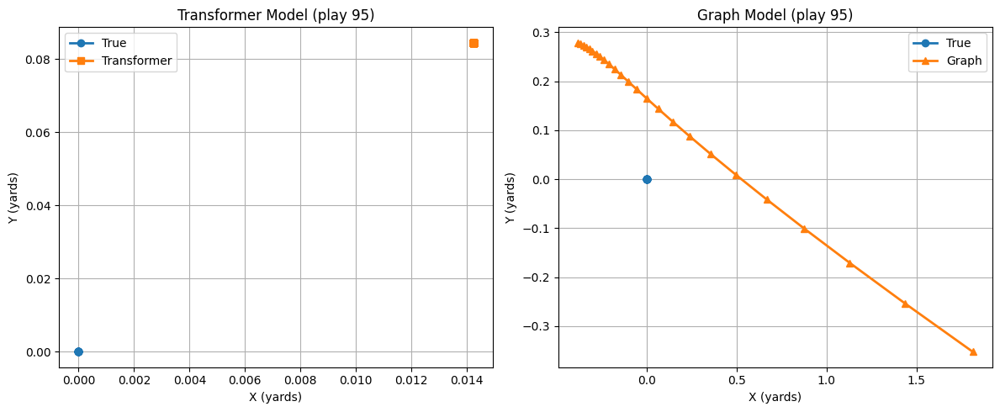

Target player 11 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 2.2 yards


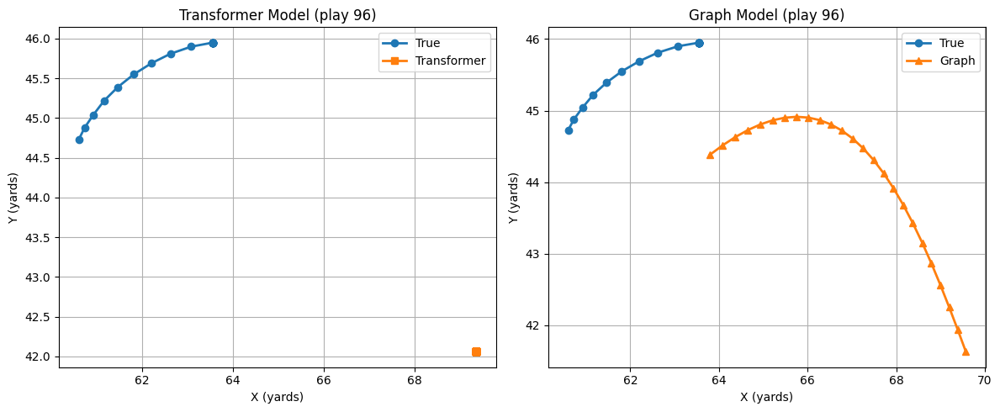

Target player 0 movement analysis:
True trajectory: X range = 2.9 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 5.8 yards


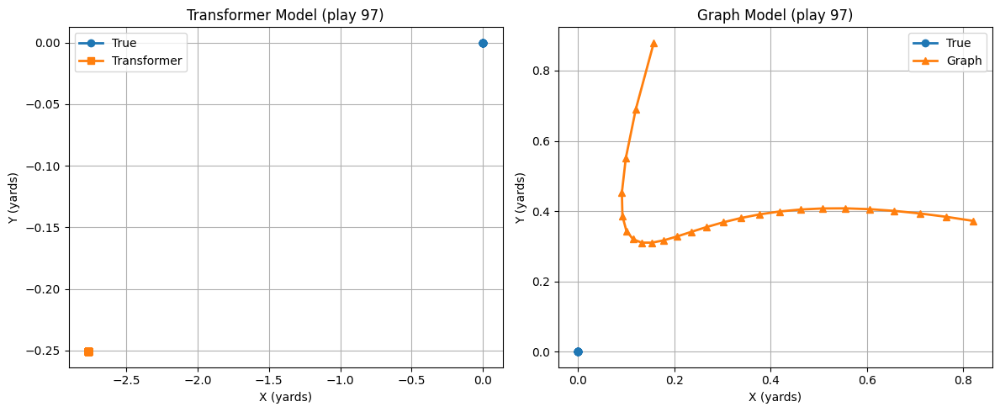

Target player 6 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 0.7 yards


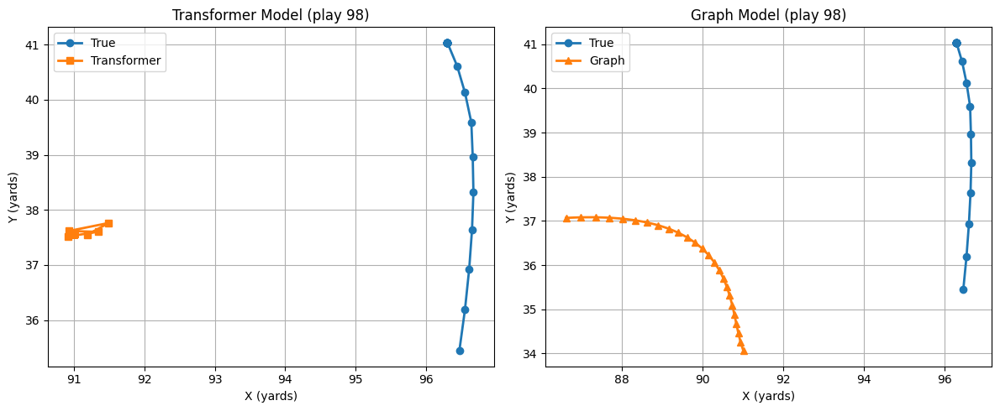

Target player 1 movement analysis:
True trajectory: X range = 0.4 yards
Transformer pred: X range = 0.6 yards
Graph pred: X range = 4.4 yards


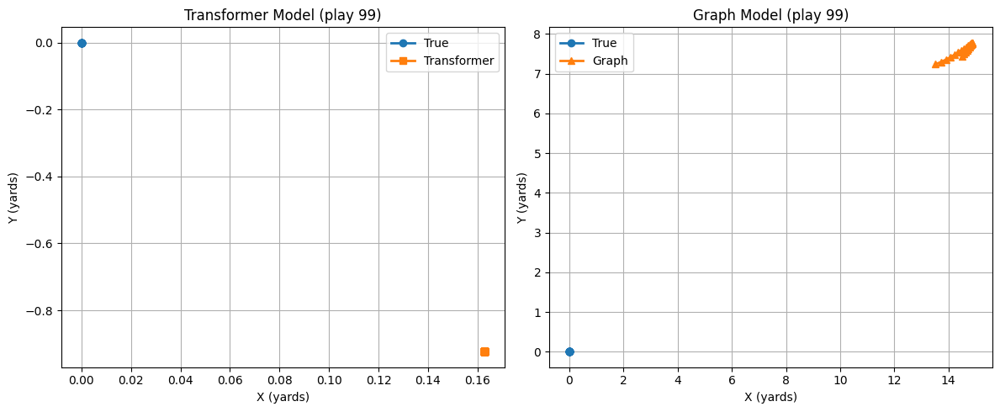

Target player 4 movement analysis:
True trajectory: X range = 0.0 yards
Transformer pred: X range = 0.0 yards
Graph pred: X range = 1.4 yards


In [23]:
# Debug: Compare transformer vs graph model predictions
import matplotlib.pyplot as plt
import numpy as np

for sample_idx in range(20, 100):
    X_sample = torch.tensor(X_data[sample_idx:sample_idx+1], dtype=torch.float32, device=device)
    mask = masks[sample_idx]

    # Get transformer model prediction
    model.eval()  # Original transformer model
    with torch.no_grad():
        Y_pred_transformer = model(X_sample).cpu().numpy()[0]

    # Get graph model prediction
    graph_model.eval()
    with torch.no_grad():
        adj_intra_seq = adj_intra_all[sample_idx:sample_idx+1]
        adj_bipartite_seq = adj_bipartite_all[sample_idx:sample_idx+1]
        adj_to_landing_seq = adj_to_landing_all[sample_idx:sample_idx+1]
        
        Y_pred_graph = graph_model(
            X_sample, 
            adj_intra_seq, 
            adj_bipartite_seq, 
            adj_to_landing_seq
        ).cpu().numpy()[0]

    # Denormalize
    Y_true_denorm = Y_data[sample_idx].copy()
    Y_true_denorm[..., 0] *= FIELD_X
    Y_true_denorm[..., 1] *= FIELD_Y

    Y_pred_transformer_denorm = Y_pred_transformer.copy()
    Y_pred_transformer_denorm[..., 0] *= FIELD_X
    Y_pred_transformer_denorm[..., 1] *= FIELD_Y

    Y_pred_graph_denorm = Y_pred_graph.copy()
    Y_pred_graph_denorm[..., 0] *= FIELD_X
    Y_pred_graph_denorm[..., 1] *= FIELD_Y

    # Plot comparison
    target_idx = np.where(mask==1)[0][0] if mask.sum()>=1 else 0

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(Y_true_denorm[:, target_idx,0], Y_true_denorm[:, target_idx,1], 'o-', label='True', linewidth=2)
    plt.plot(Y_pred_transformer_denorm[:, target_idx,0], Y_pred_transformer_denorm[:, target_idx,1], 's-', label='Transformer', linewidth=2)
    plt.title(f"Transformer Model (play {sample_idx})")
    plt.xlabel("X (yards)")
    plt.ylabel("Y (yards)")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(Y_true_denorm[:, target_idx,0], Y_true_denorm[:, target_idx,1], 'o-', label='True', linewidth=2)
    plt.plot(Y_pred_graph_denorm[:, target_idx,0], Y_pred_graph_denorm[:, target_idx,1], '^-', label='Graph', linewidth=2)
    plt.title(f"Graph Model (play {sample_idx})")
    plt.xlabel("X (yards)")
    plt.ylabel("Y (yards)")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    # Print movement statistics
    print(f"Target player {target_idx} movement analysis:")
    print(f"True trajectory: X range = {Y_true_denorm[:, target_idx,0].max() - Y_true_denorm[:, target_idx,0].min():.1f} yards")
    print(f"Transformer pred: X range = {Y_pred_transformer_denorm[:, target_idx,0].max() - Y_pred_transformer_denorm[:, target_idx,0].min():.1f} yards")
    print(f"Graph pred: X range = {Y_pred_graph_denorm[:, target_idx,0].max() - Y_pred_graph_denorm[:, target_idx,0].min():.1f} yards")


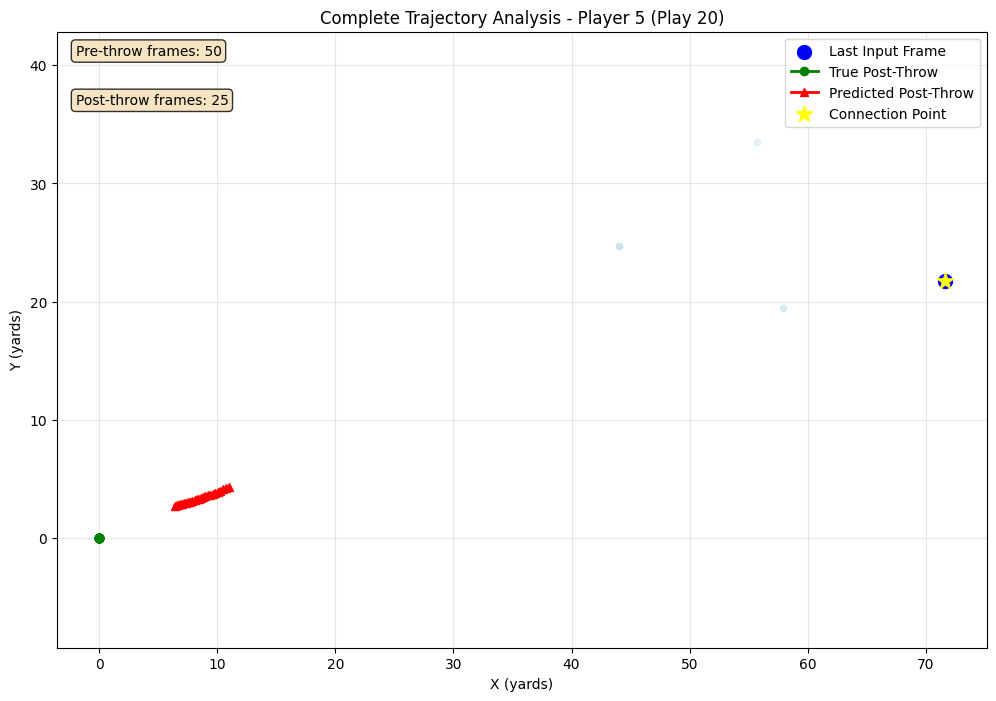


Connection Analysis for Player 5:
Last input position: (71.59, 21.76)
First predicted position: (11.02, 4.28)
First true position: (0.00, 0.00)
Prediction gap: 63.04 yards
True gap: 74.82 yards


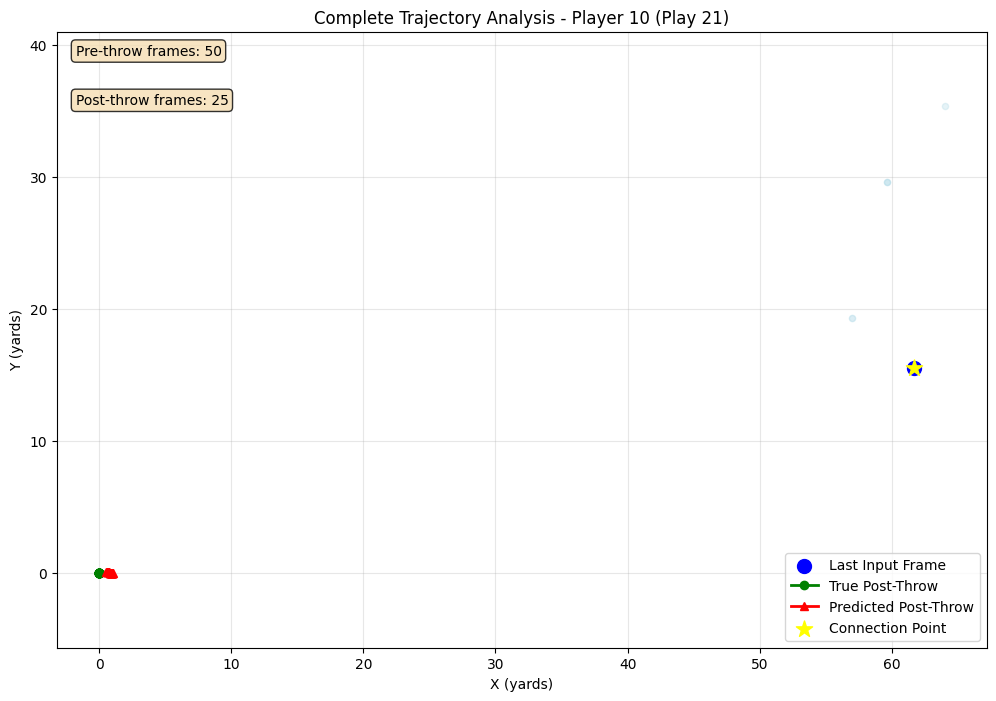


Connection Analysis for Player 10:
Last input position: (61.70, 15.54)
First predicted position: (0.50, 0.12)
First true position: (0.00, 0.00)
Prediction gap: 63.11 yards
True gap: 63.63 yards


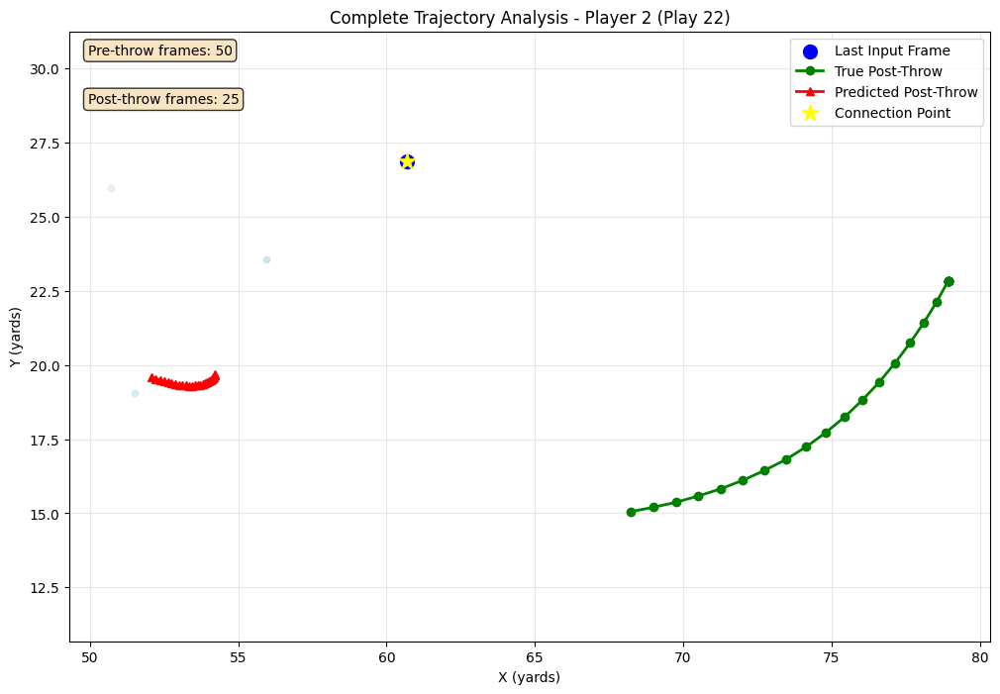


Connection Analysis for Player 2:
Last input position: (60.69, 26.87)
First predicted position: (54.22, 19.69)
First true position: (68.25, 15.06)
Prediction gap: 9.67 yards
True gap: 14.02 yards


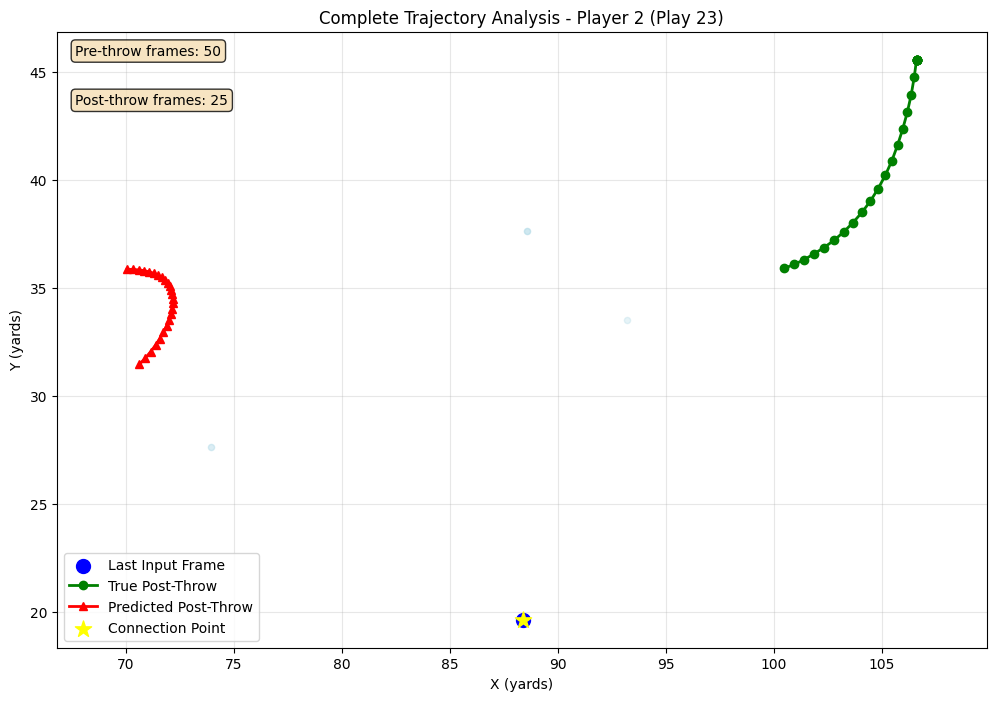


Connection Analysis for Player 2:
Last input position: (88.38, 19.65)
First predicted position: (70.63, 31.48)
First true position: (100.48, 35.92)
Prediction gap: 21.33 yards
True gap: 20.28 yards


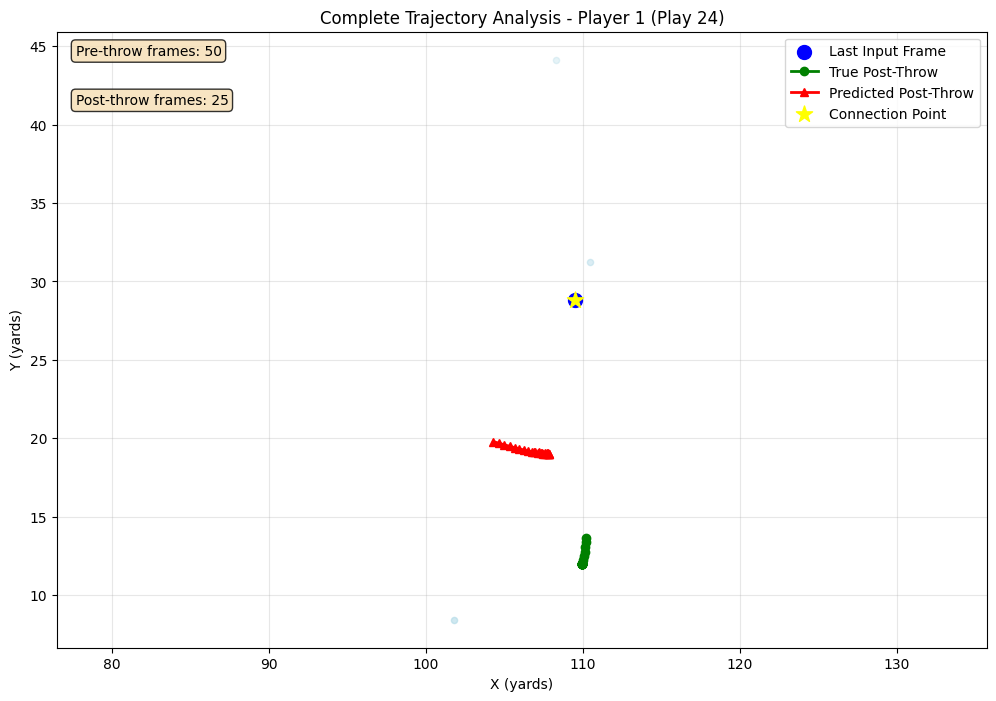


Connection Analysis for Player 1:
Last input position: (109.49, 28.82)
First predicted position: (106.91, 19.11)
First true position: (110.20, 13.67)
Prediction gap: 10.05 yards
True gap: 15.17 yards


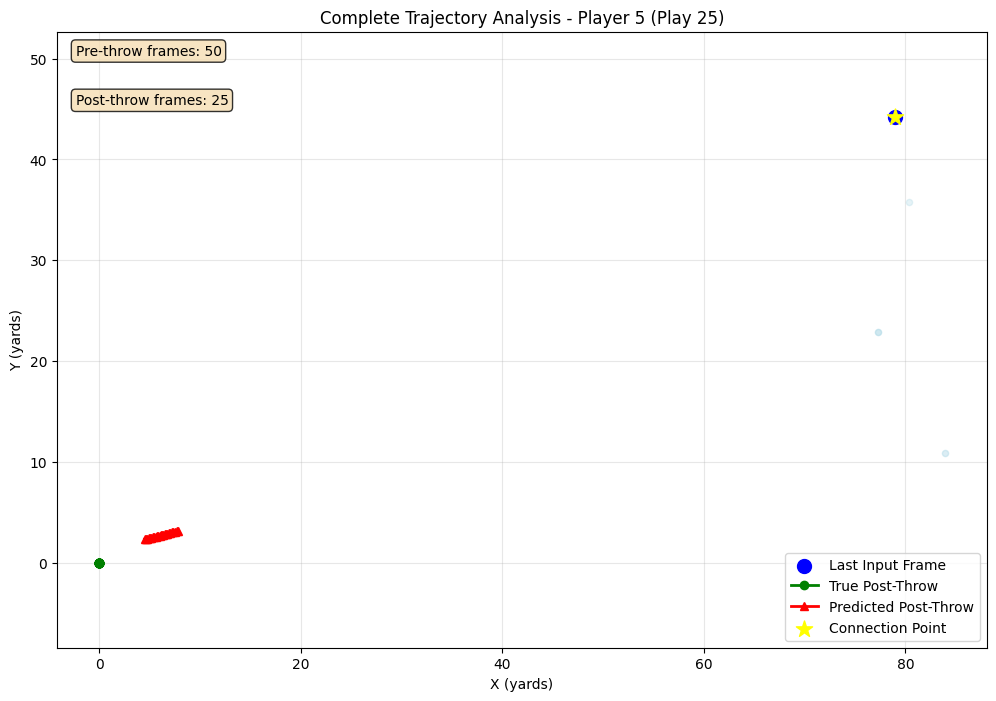


Connection Analysis for Player 5:
Last input position: (78.98, 44.23)
First predicted position: (7.87, 3.15)
First true position: (0.00, 0.00)
Prediction gap: 82.13 yards
True gap: 90.52 yards


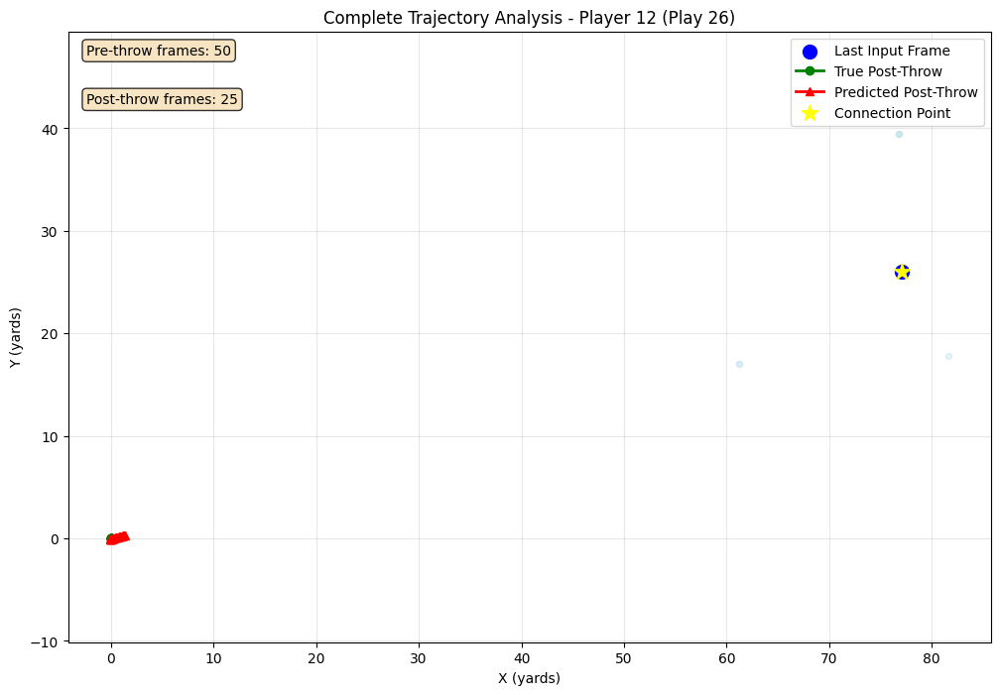


Connection Analysis for Player 12:
Last input position: (77.11, 25.99)
First predicted position: (1.37, 0.33)
First true position: (0.00, 0.00)
Prediction gap: 79.97 yards
True gap: 81.37 yards


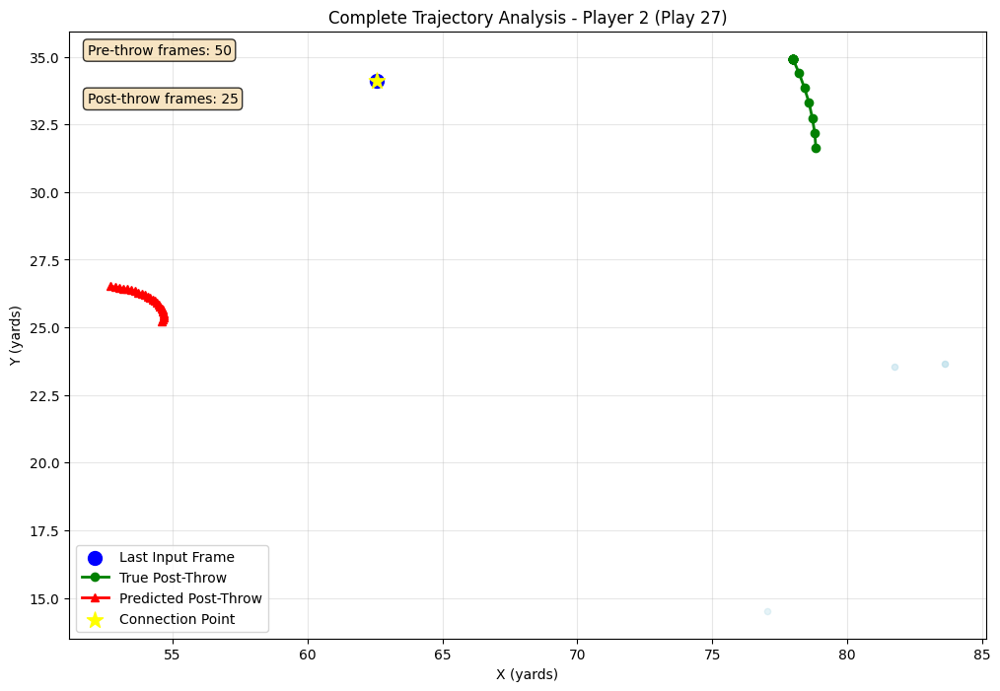


Connection Analysis for Player 2:
Last input position: (62.56, 34.10)
First predicted position: (54.60, 25.23)
First true position: (78.84, 31.64)
Prediction gap: 11.92 yards
True gap: 16.46 yards


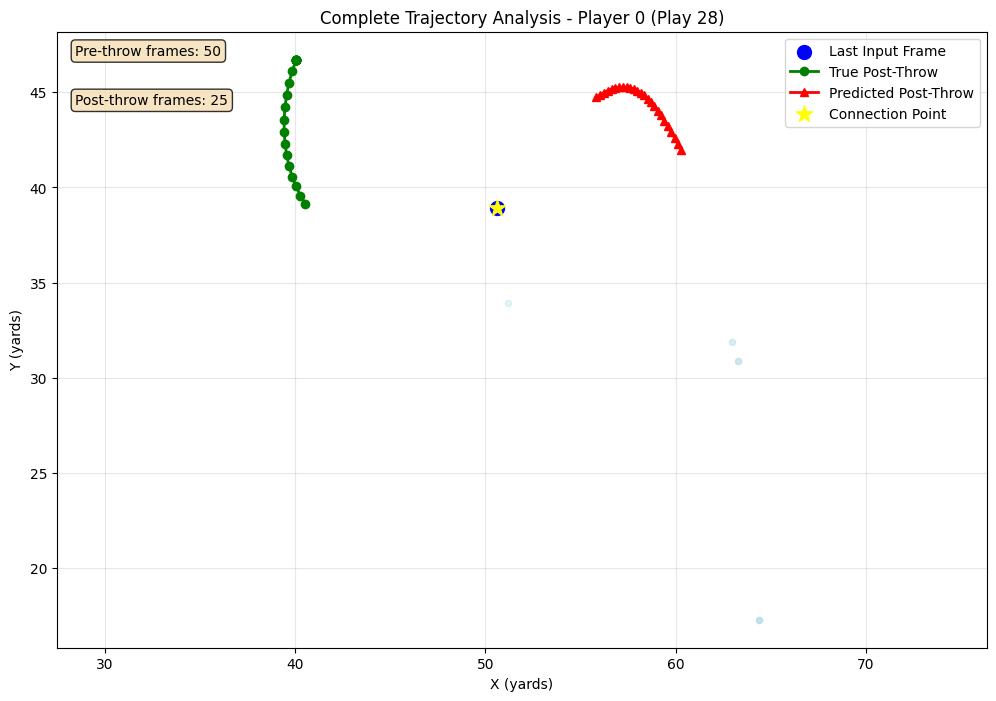


Connection Analysis for Player 0:
Last input position: (50.60, 38.93)
First predicted position: (60.30, 41.96)
First true position: (40.55, 39.14)
Prediction gap: 10.16 yards
True gap: 10.05 yards


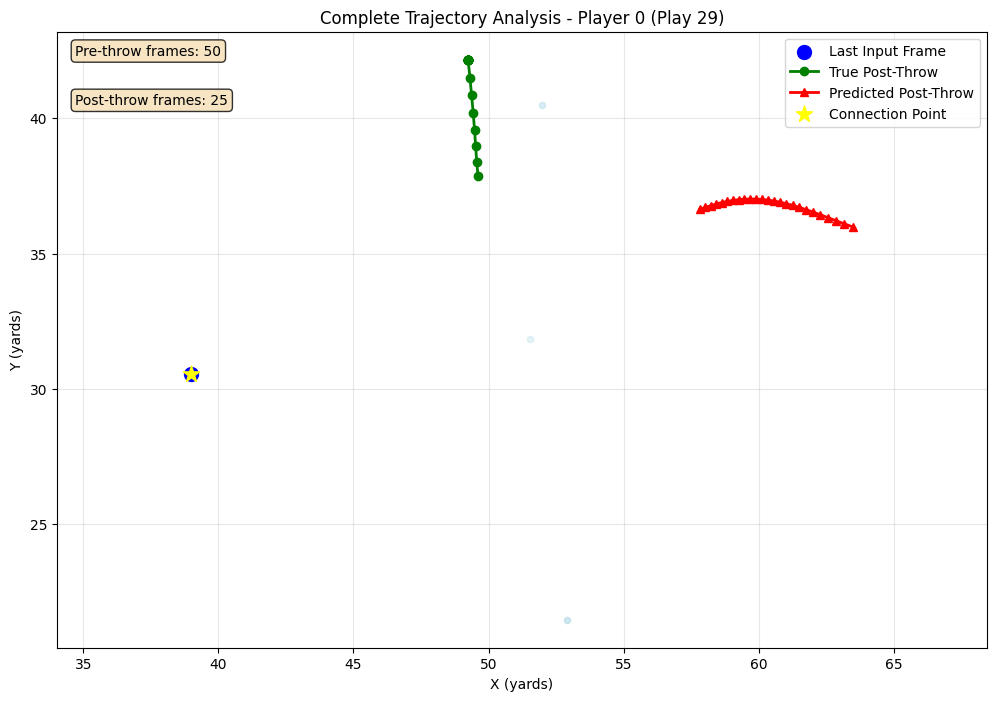


Connection Analysis for Player 0:
Last input position: (38.99, 30.53)
First predicted position: (63.47, 35.98)
First true position: (49.61, 37.86)
Prediction gap: 25.08 yards
True gap: 12.90 yards


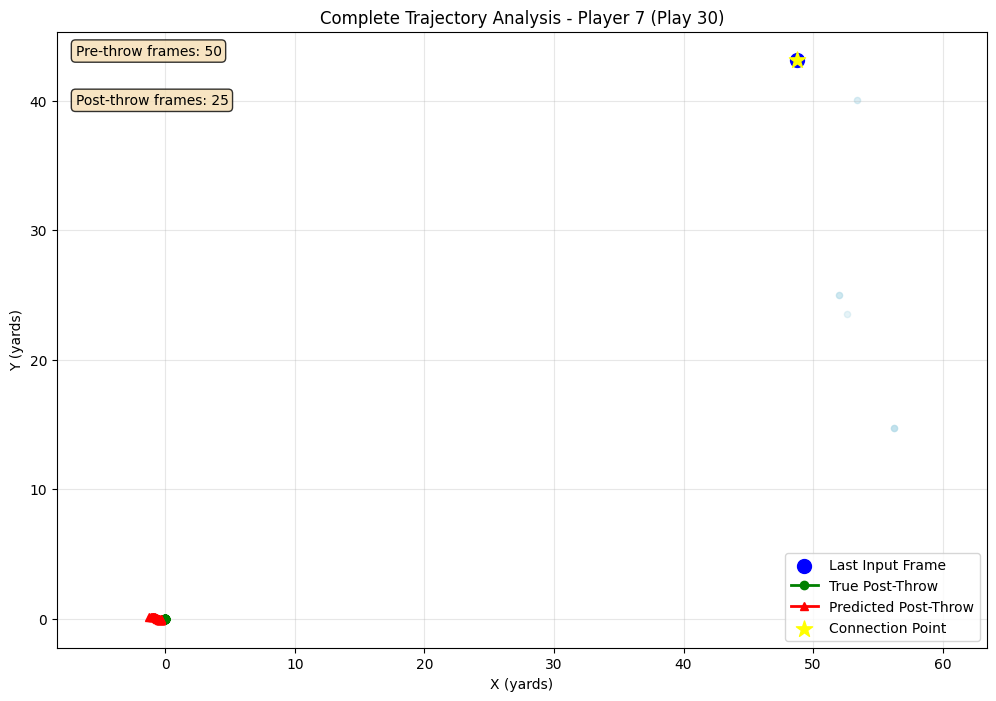


Connection Analysis for Player 7:
Last input position: (48.73, 43.15)
First predicted position: (-1.22, 0.15)
First true position: (0.00, 0.00)
Prediction gap: 65.91 yards
True gap: 65.09 yards


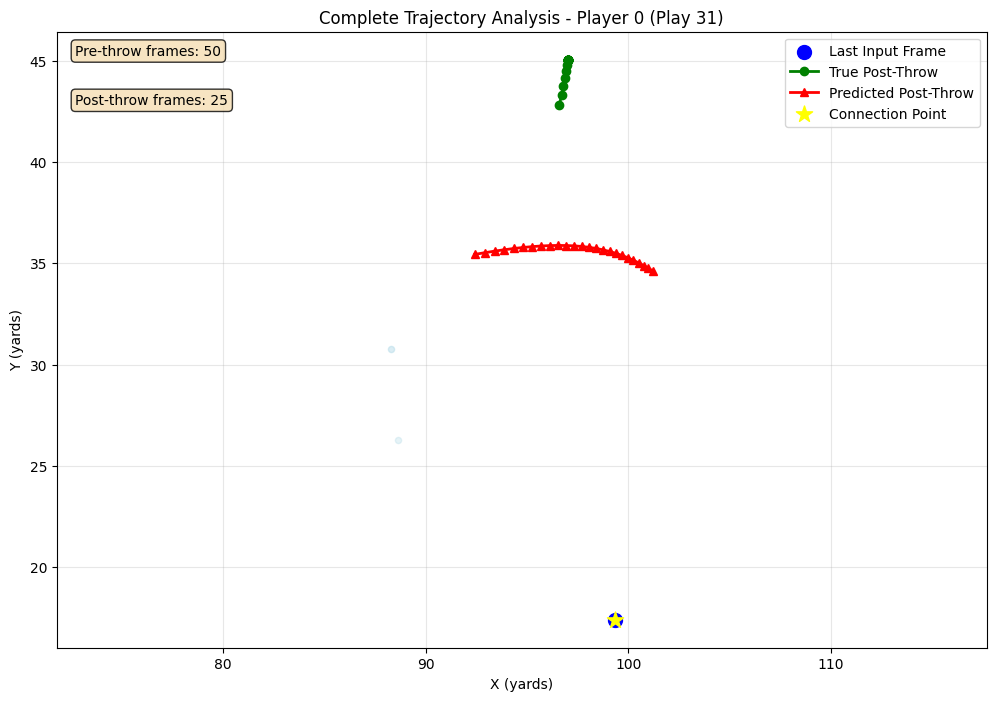


Connection Analysis for Player 0:
Last input position: (99.33, 17.40)
First predicted position: (101.22, 34.62)
First true position: (96.59, 42.81)
Prediction gap: 17.32 yards
True gap: 25.56 yards


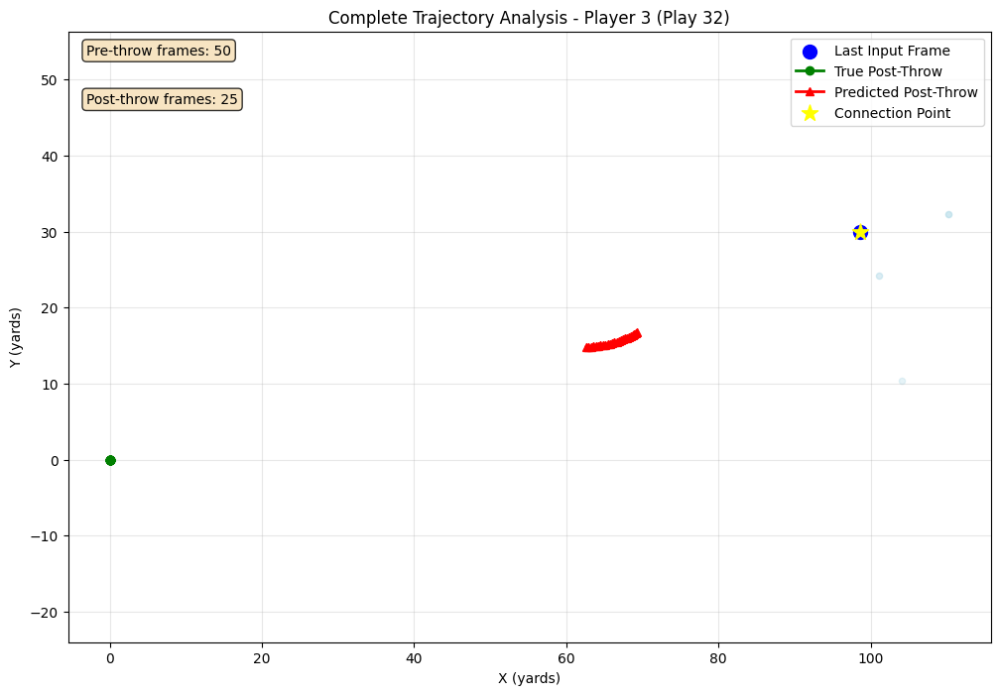


Connection Analysis for Player 3:
Last input position: (98.66, 29.93)
First predicted position: (69.25, 16.77)
First true position: (0.00, 0.00)
Prediction gap: 32.22 yards
True gap: 103.10 yards


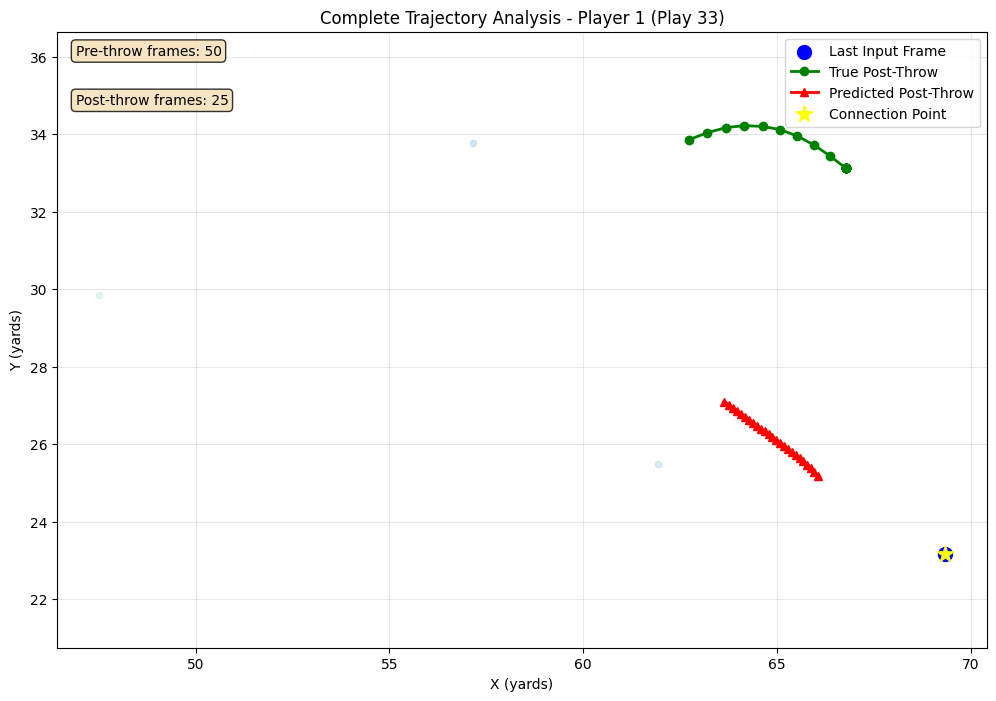


Connection Analysis for Player 1:
Last input position: (69.33, 23.17)
First predicted position: (66.06, 25.19)
First true position: (62.74, 33.86)
Prediction gap: 3.84 yards
True gap: 12.56 yards


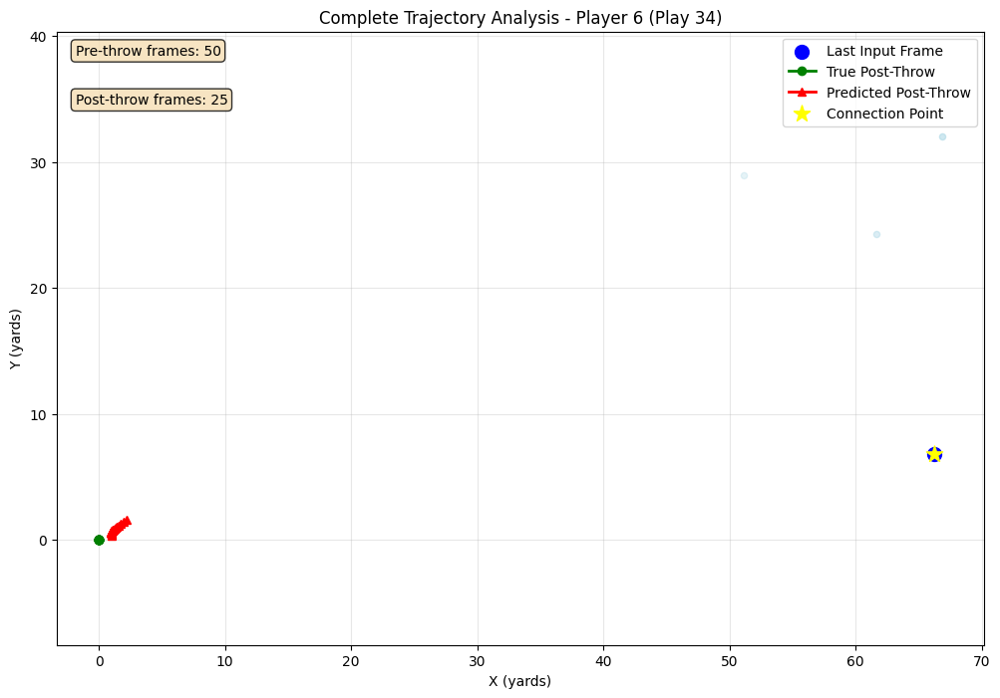


Connection Analysis for Player 6:
Last input position: (66.25, 6.80)
First predicted position: (2.18, 1.58)
First true position: (0.00, 0.00)
Prediction gap: 64.29 yards
True gap: 66.60 yards


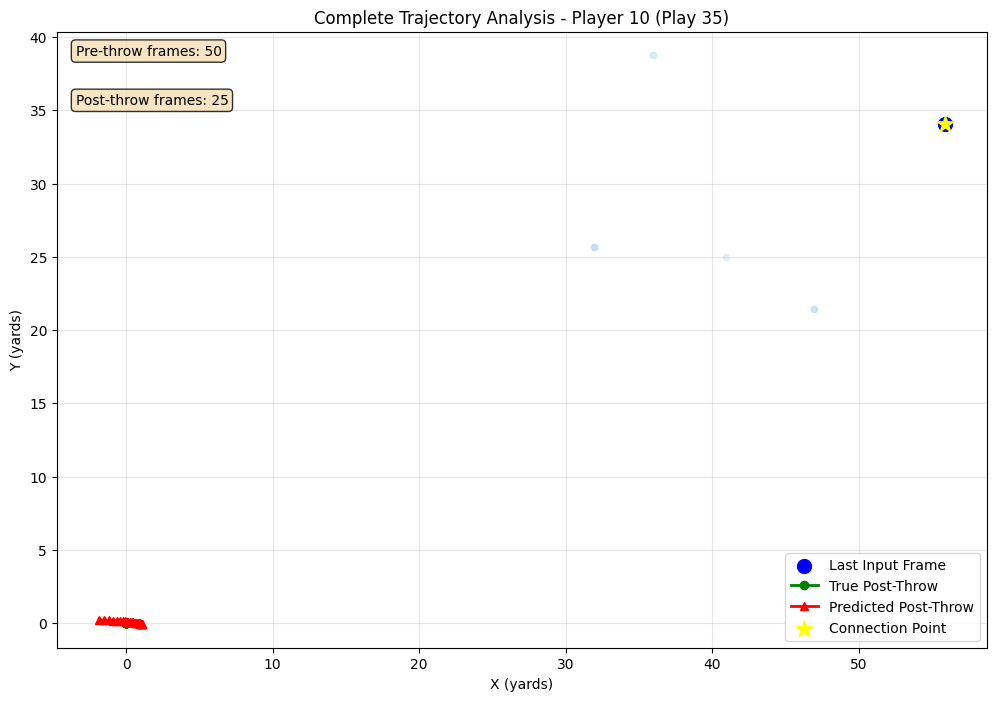


Connection Analysis for Player 10:
Last input position: (55.87, 34.04)
First predicted position: (-1.84, 0.22)
First true position: (0.00, 0.00)
Prediction gap: 66.89 yards
True gap: 65.42 yards


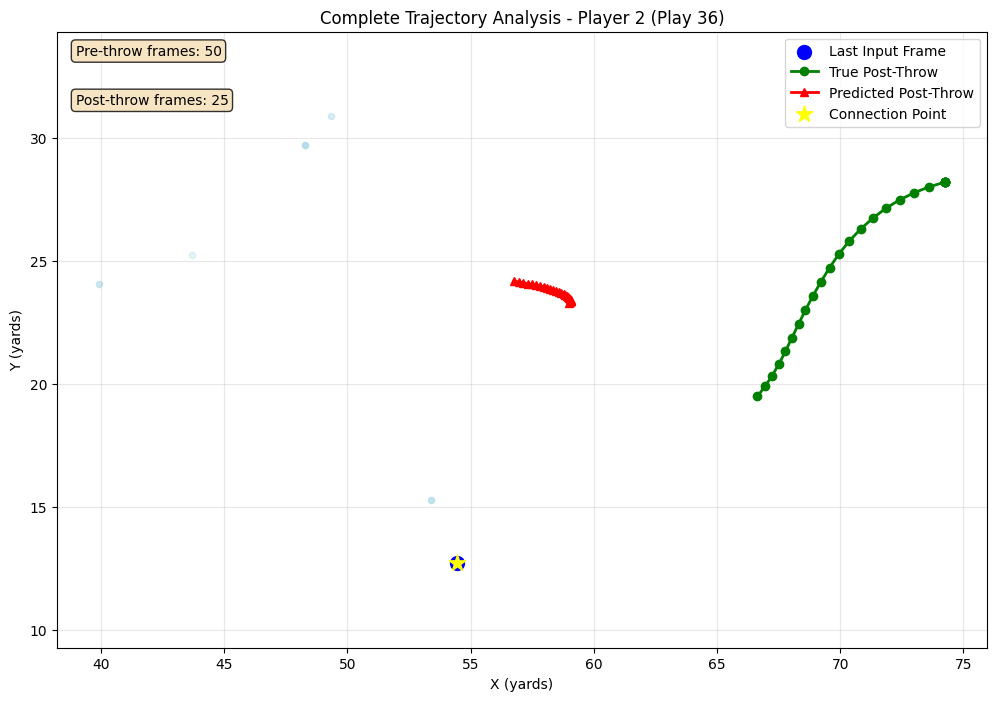


Connection Analysis for Player 2:
Last input position: (54.44, 12.73)
First predicted position: (59.00, 23.28)
First true position: (66.64, 19.50)
Prediction gap: 11.49 yards
True gap: 13.95 yards


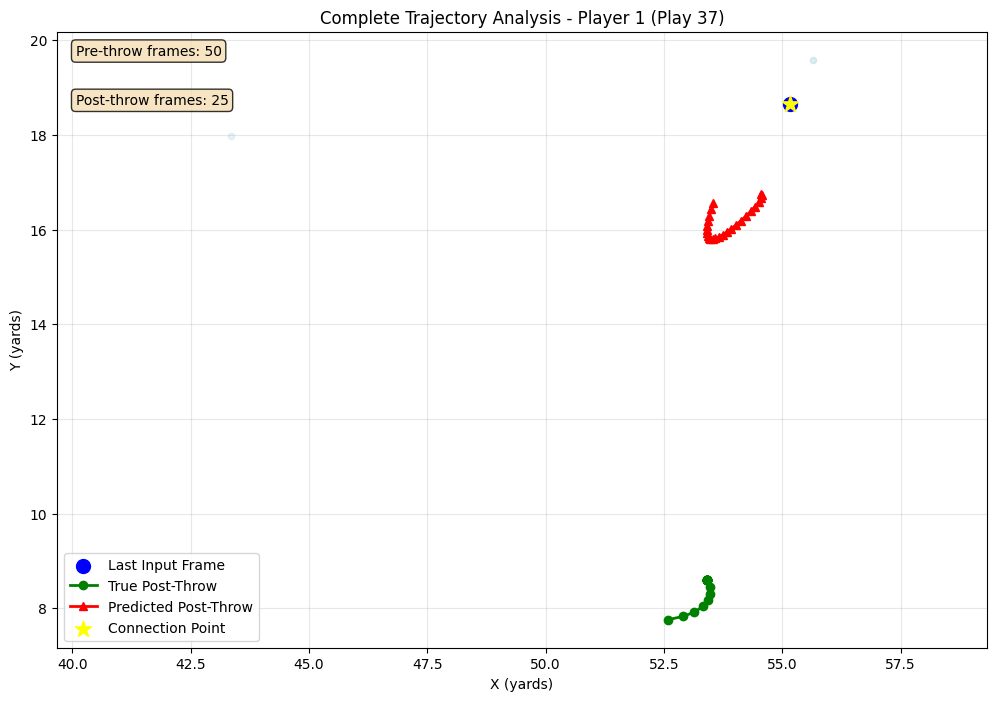


Connection Analysis for Player 1:
Last input position: (55.17, 18.65)
First predicted position: (54.55, 16.76)
First true position: (52.58, 7.76)
Prediction gap: 1.99 yards
True gap: 11.19 yards


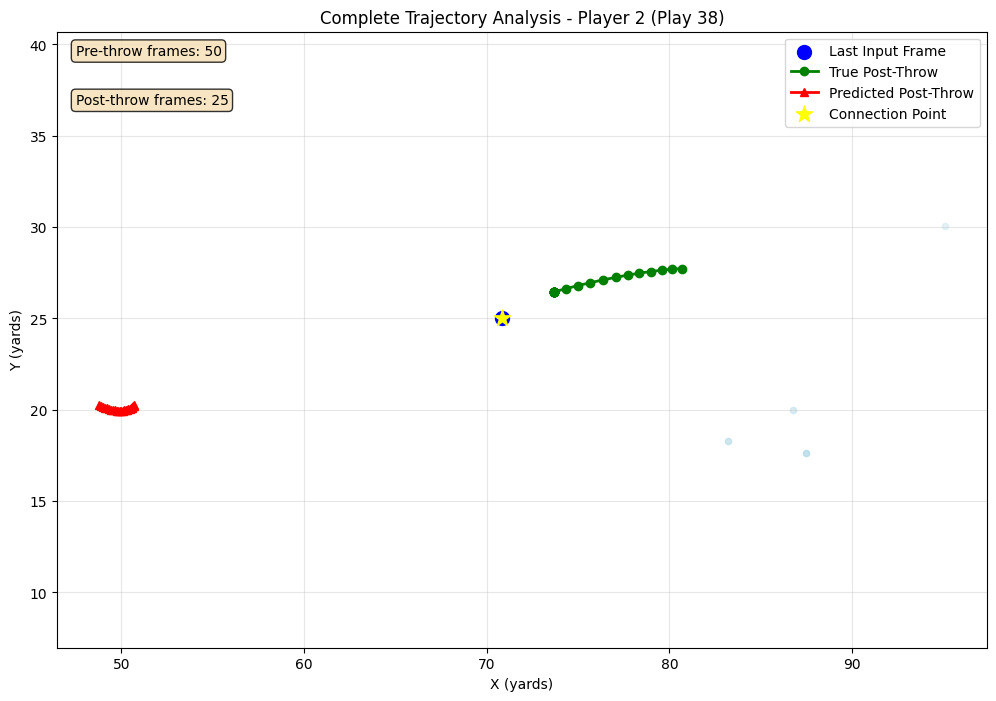


Connection Analysis for Player 2:
Last input position: (70.86, 25.04)
First predicted position: (50.68, 20.26)
First true position: (80.70, 27.73)
Prediction gap: 20.74 yards
True gap: 10.20 yards


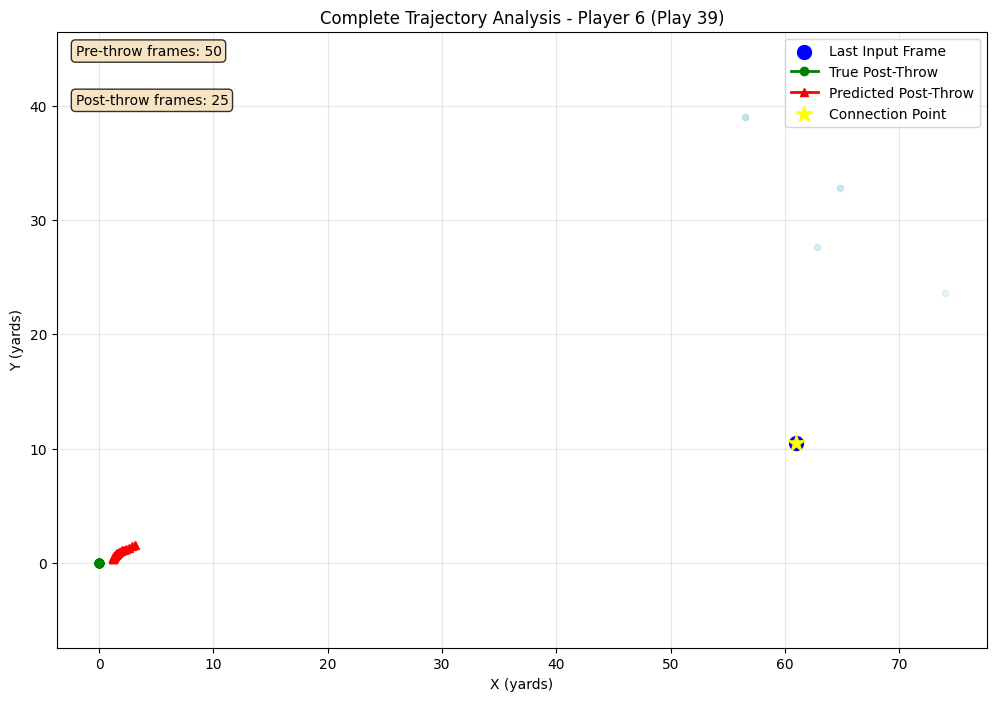


Connection Analysis for Player 6:
Last input position: (61.00, 10.50)
First predicted position: (3.16, 1.56)
First true position: (0.00, 0.00)
Prediction gap: 58.52 yards
True gap: 61.90 yards


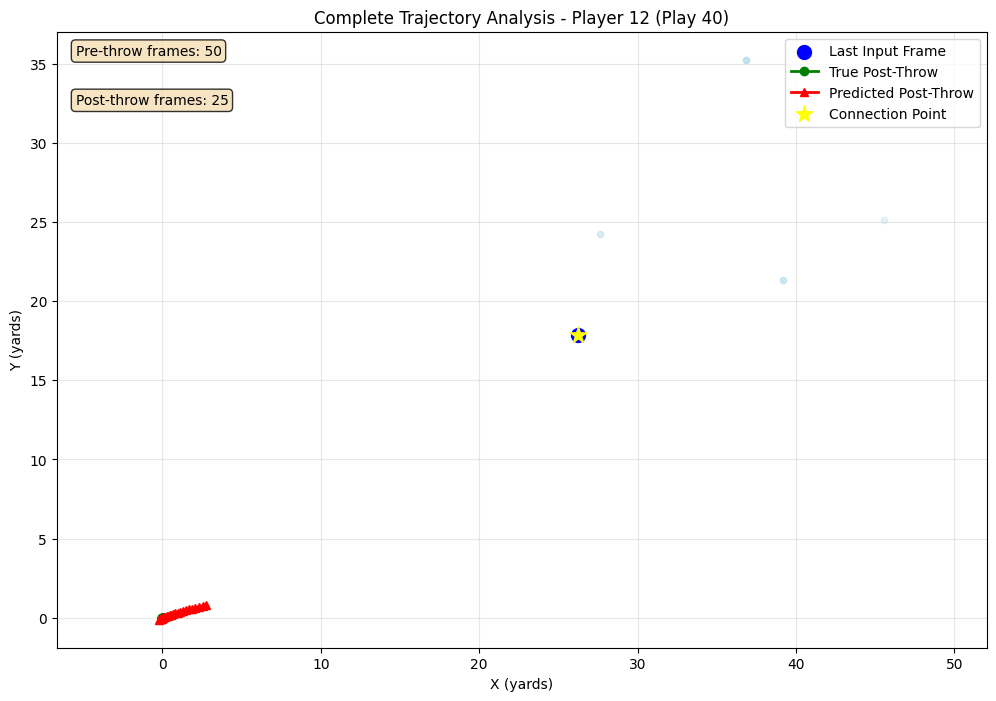


Connection Analysis for Player 12:
Last input position: (26.21, 17.89)
First predicted position: (2.77, 0.80)
First true position: (0.00, 0.00)
Prediction gap: 29.00 yards
True gap: 31.73 yards


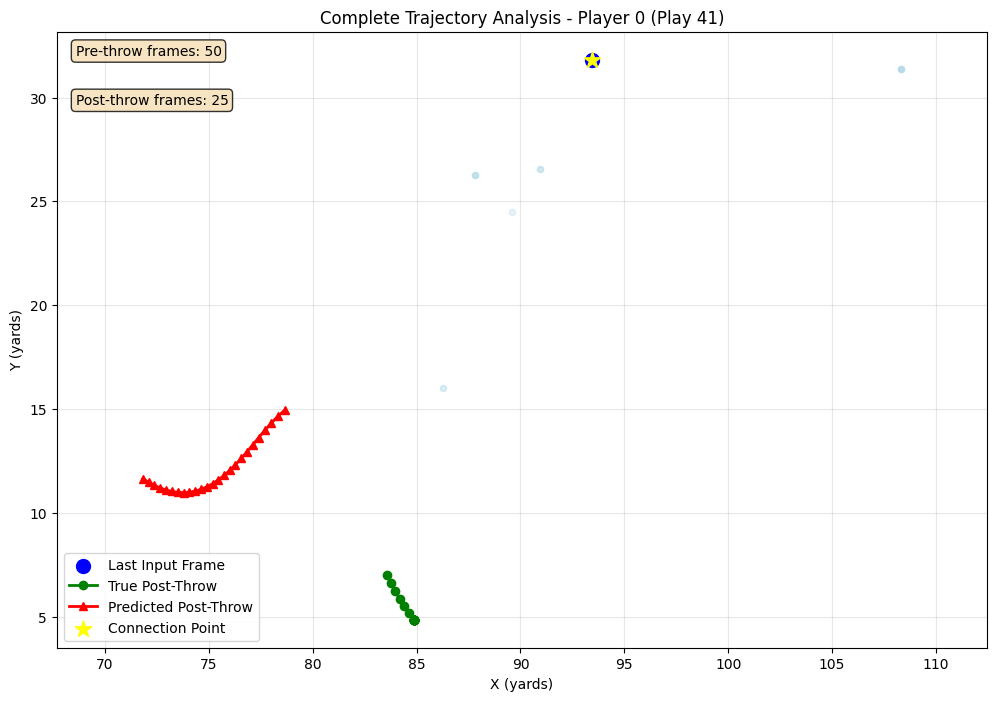


Connection Analysis for Player 0:
Last input position: (93.45, 31.82)
First predicted position: (78.66, 14.96)
First true position: (83.57, 7.02)
Prediction gap: 22.43 yards
True gap: 26.70 yards


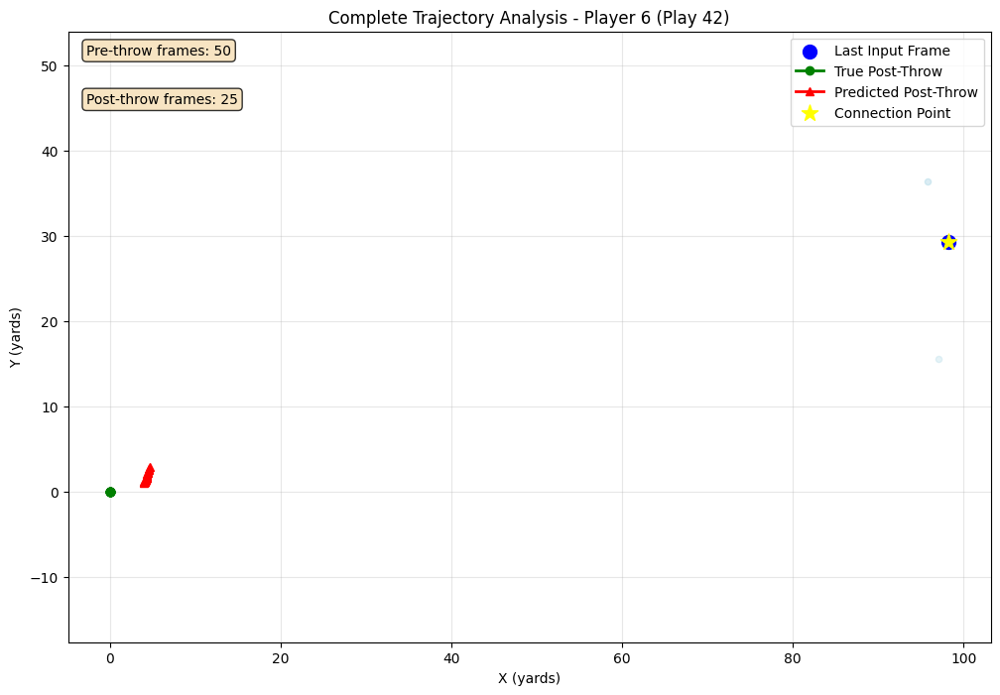


Connection Analysis for Player 6:
Last input position: (98.27, 29.32)
First predicted position: (4.69, 2.95)
First true position: (0.00, 0.00)
Prediction gap: 97.22 yards
True gap: 102.55 yards


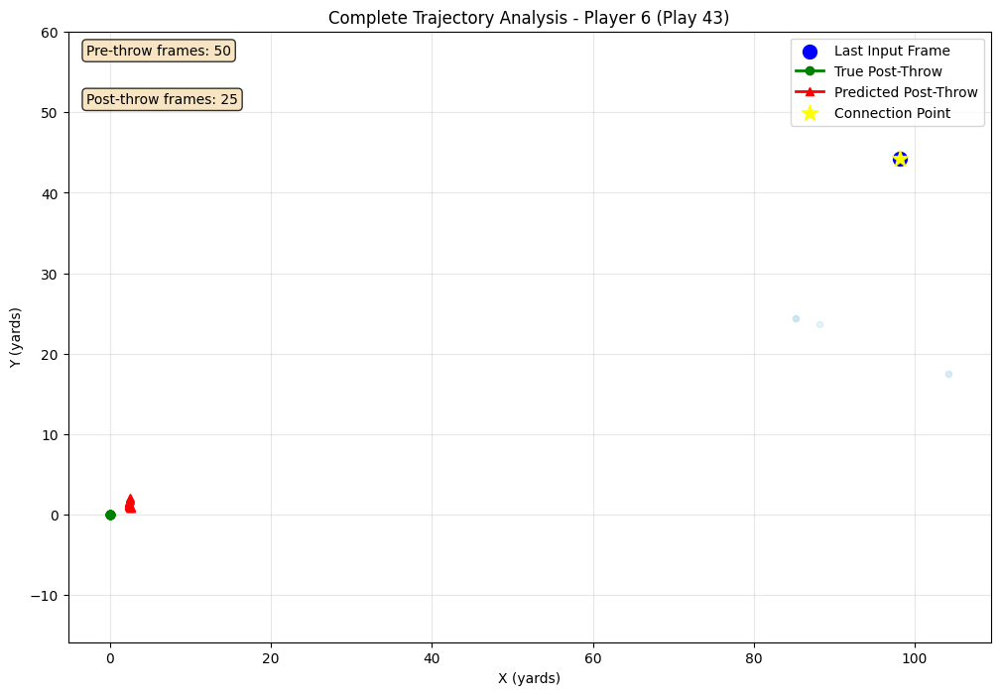


Connection Analysis for Player 6:
Last input position: (98.18, 44.20)
First predicted position: (2.51, 2.04)
First true position: (0.00, 0.00)
Prediction gap: 104.55 yards
True gap: 107.67 yards


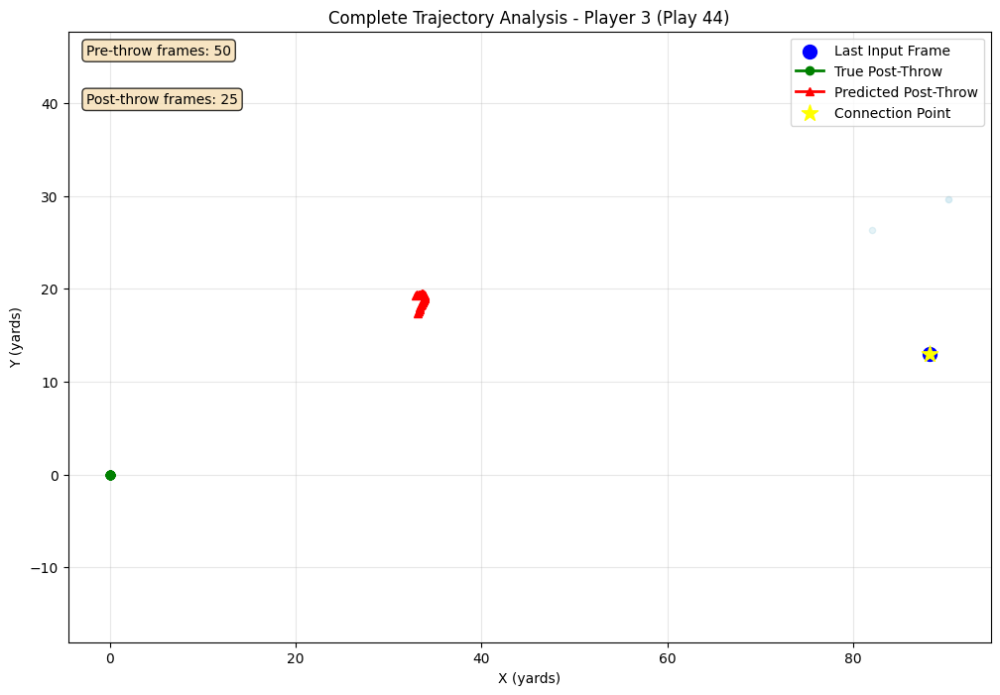


Connection Analysis for Player 3:
Last input position: (88.22, 13.01)
First predicted position: (33.15, 17.41)
First true position: (0.00, 0.00)
Prediction gap: 55.24 yards
True gap: 89.17 yards


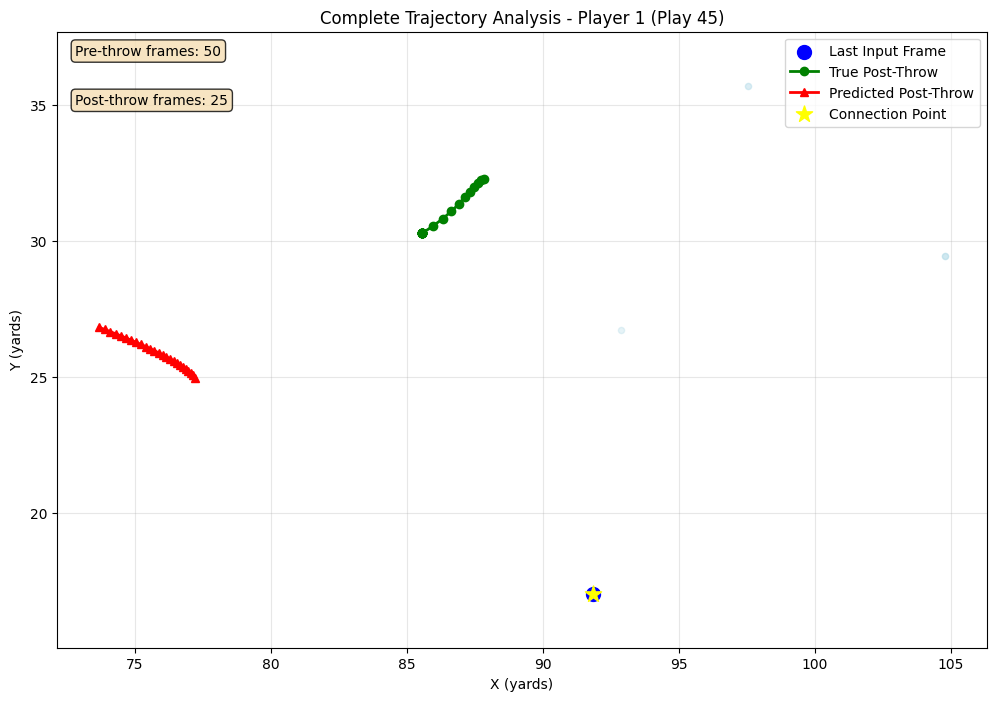


Connection Analysis for Player 1:
Last input position: (91.86, 17.02)
First predicted position: (77.22, 24.97)
First true position: (87.85, 32.28)
Prediction gap: 16.66 yards
True gap: 15.78 yards


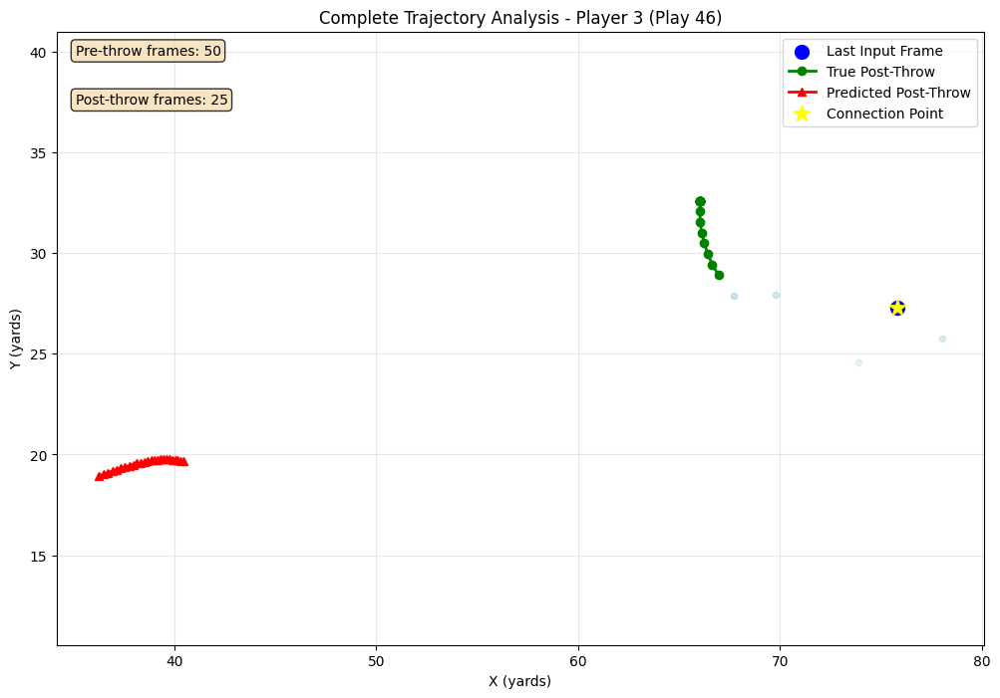


Connection Analysis for Player 3:
Last input position: (75.82, 27.27)
First predicted position: (40.45, 19.68)
First true position: (66.95, 28.90)
Prediction gap: 36.18 yards
True gap: 9.02 yards


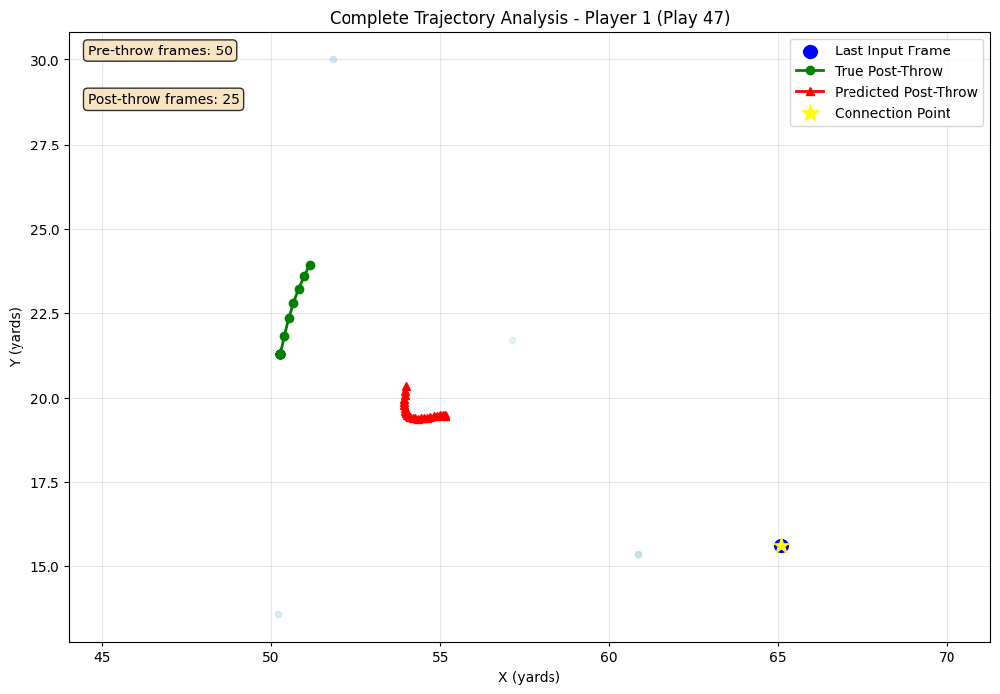


Connection Analysis for Player 1:
Last input position: (65.11, 15.61)
First predicted position: (55.17, 19.46)
First true position: (51.14, 23.92)
Prediction gap: 10.66 yards
True gap: 16.25 yards


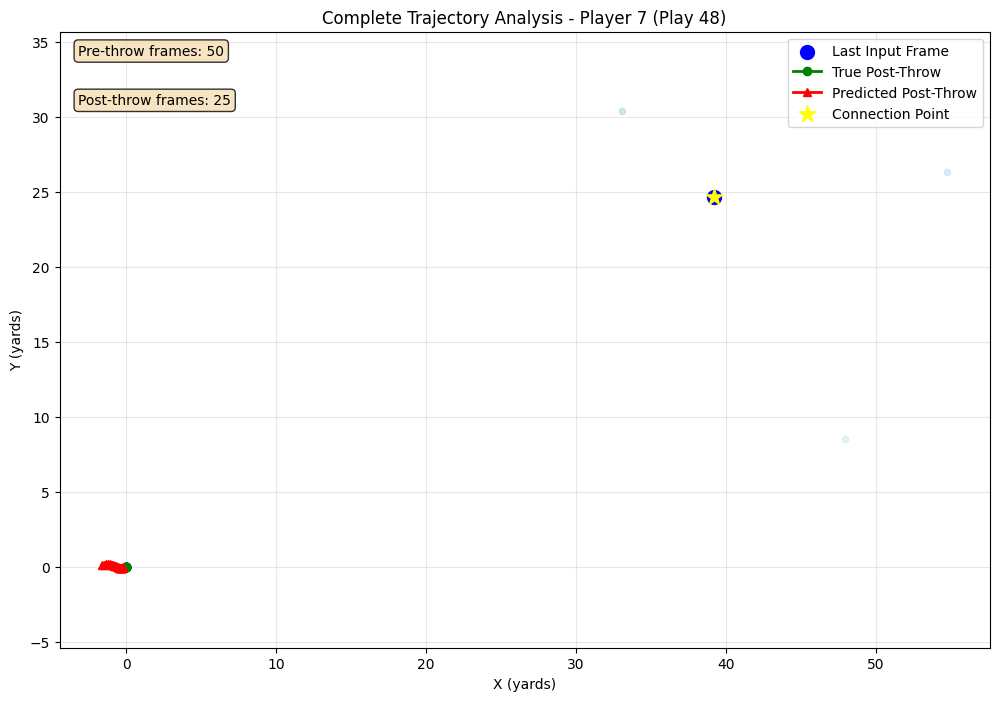


Connection Analysis for Player 7:
Last input position: (39.21, 24.66)
First predicted position: (-1.62, 0.12)
First true position: (0.00, 0.00)
Prediction gap: 47.64 yards
True gap: 46.32 yards


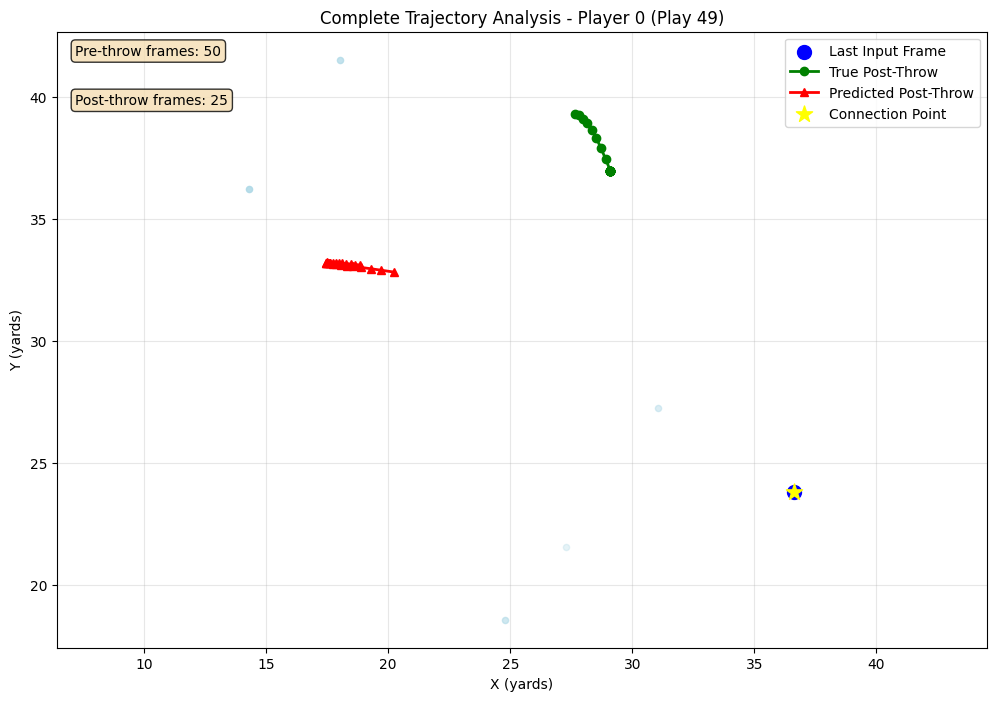


Connection Analysis for Player 0:
Last input position: (36.64, 23.82)
First predicted position: (20.22, 32.82)
First true position: (27.64, 39.29)
Prediction gap: 18.72 yards
True gap: 17.90 yards


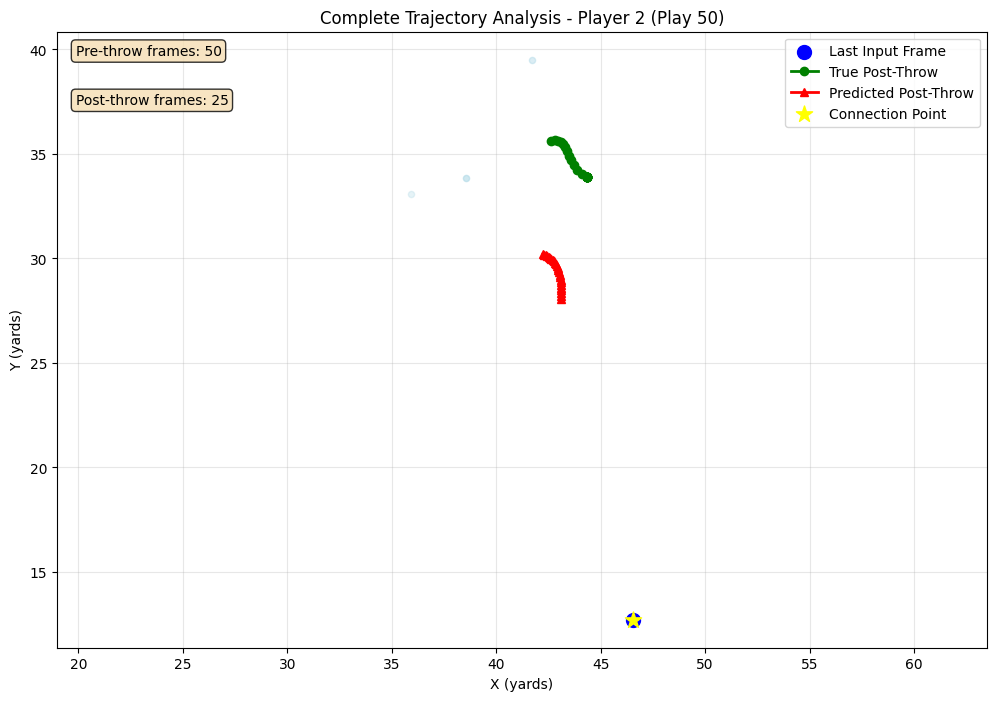


Connection Analysis for Player 2:
Last input position: (46.53, 12.71)
First predicted position: (43.08, 28.07)
First true position: (42.62, 35.62)
Prediction gap: 15.75 yards
True gap: 23.24 yards


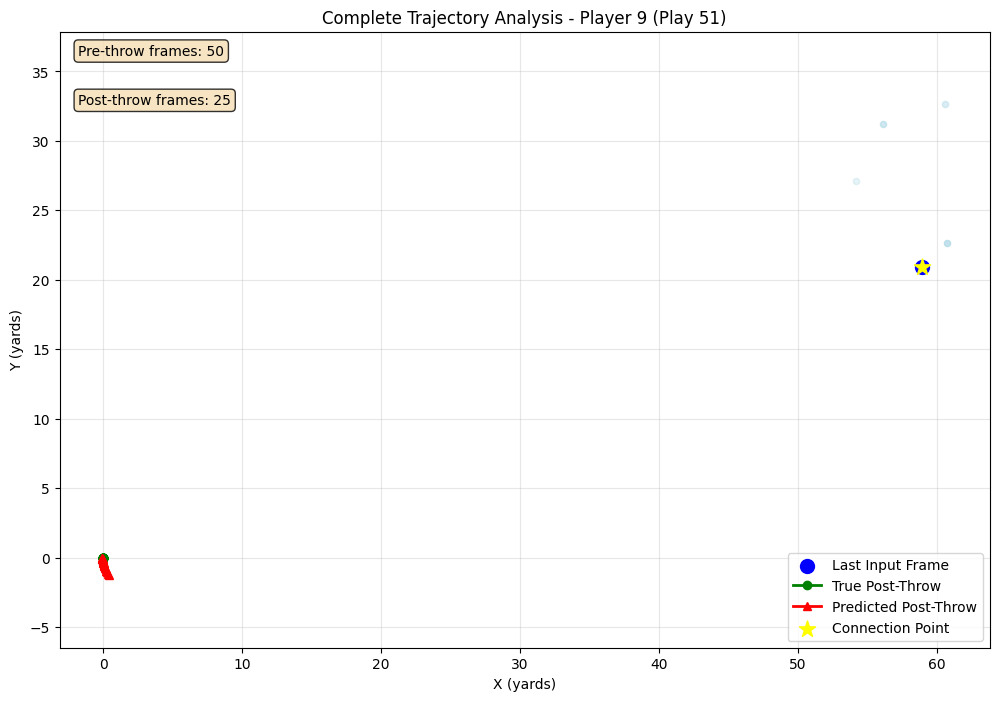


Connection Analysis for Player 9:
Last input position: (58.96, 20.93)
First predicted position: (0.41, -1.26)
First true position: (0.00, 0.00)
Prediction gap: 62.62 yards
True gap: 62.56 yards


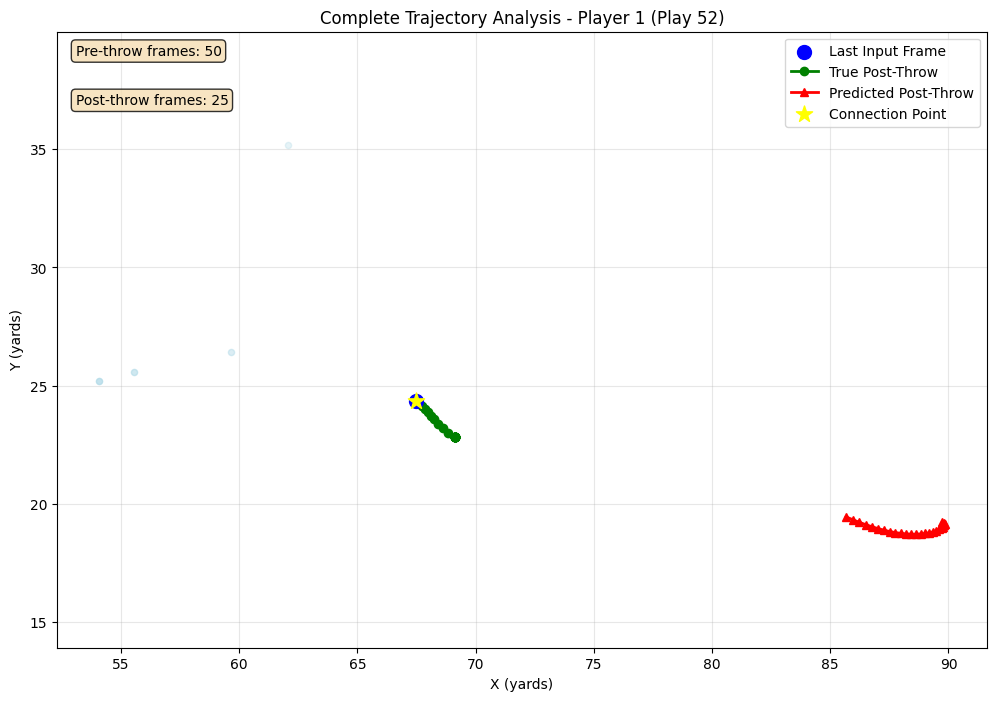


Connection Analysis for Player 1:
Last input position: (67.48, 24.35)
First predicted position: (89.73, 19.22)
First true position: (67.60, 24.26)
Prediction gap: 22.84 yards
True gap: 0.15 yards


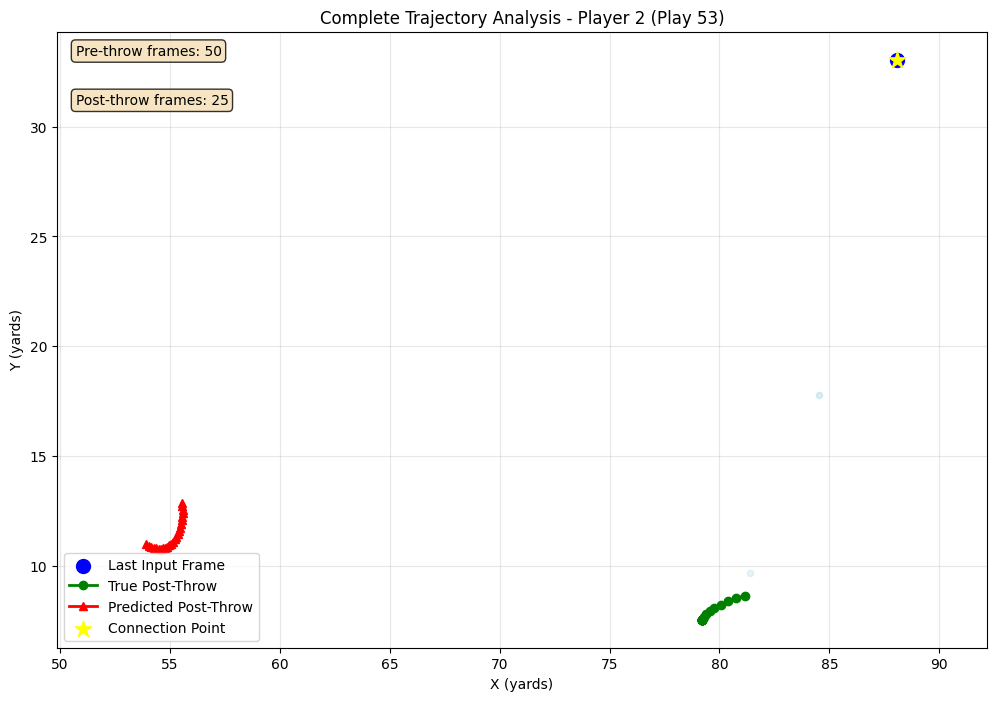


Connection Analysis for Player 2:
Last input position: (88.10, 33.04)
First predicted position: (55.53, 12.85)
First true position: (81.18, 8.66)
Prediction gap: 38.32 yards
True gap: 25.34 yards


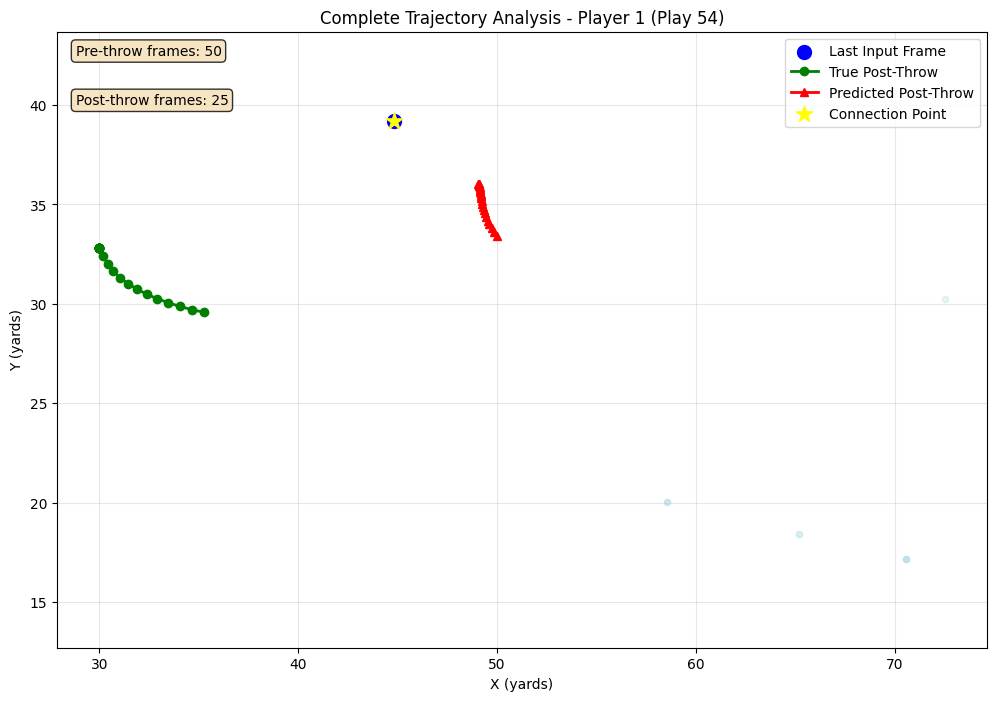


Connection Analysis for Player 1:
Last input position: (44.84, 39.21)
First predicted position: (50.02, 33.41)
First true position: (35.27, 29.57)
Prediction gap: 7.78 yards
True gap: 13.58 yards


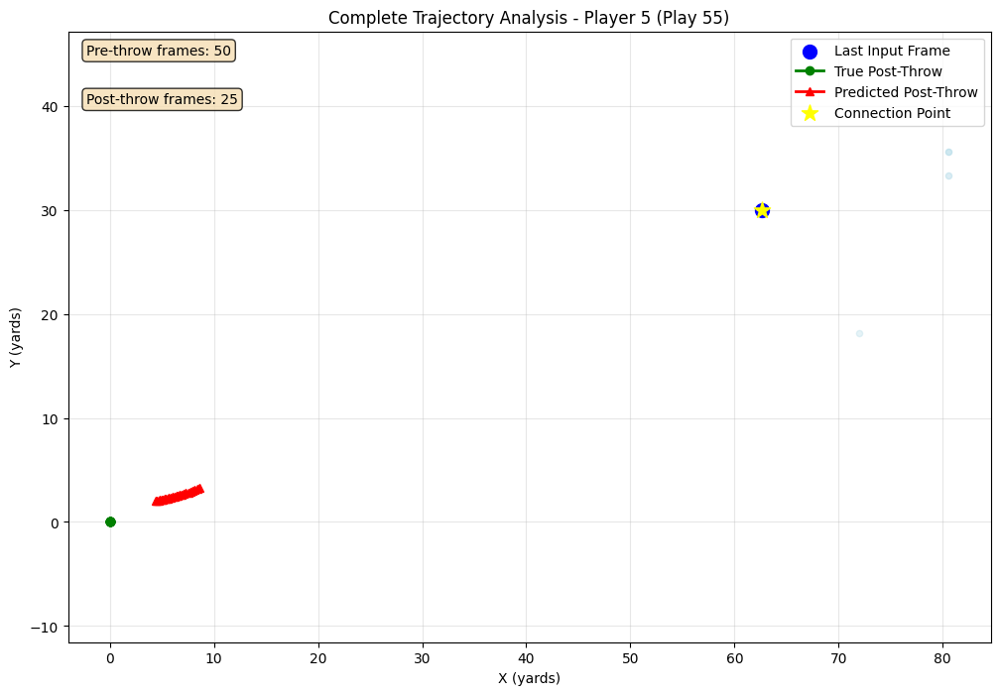


Connection Analysis for Player 5:
Last input position: (62.65, 29.93)
First predicted position: (8.63, 3.29)
First true position: (0.00, 0.00)
Prediction gap: 60.23 yards
True gap: 69.43 yards


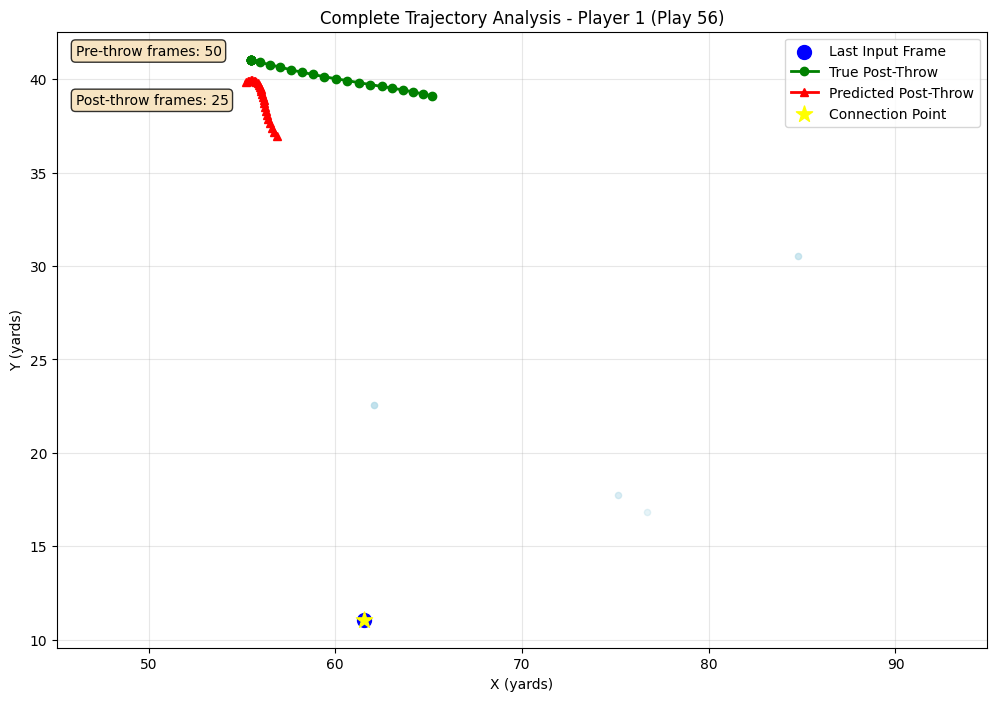


Connection Analysis for Player 1:
Last input position: (61.52, 11.06)
First predicted position: (56.90, 36.98)
First true position: (65.16, 39.12)
Prediction gap: 26.32 yards
True gap: 28.30 yards


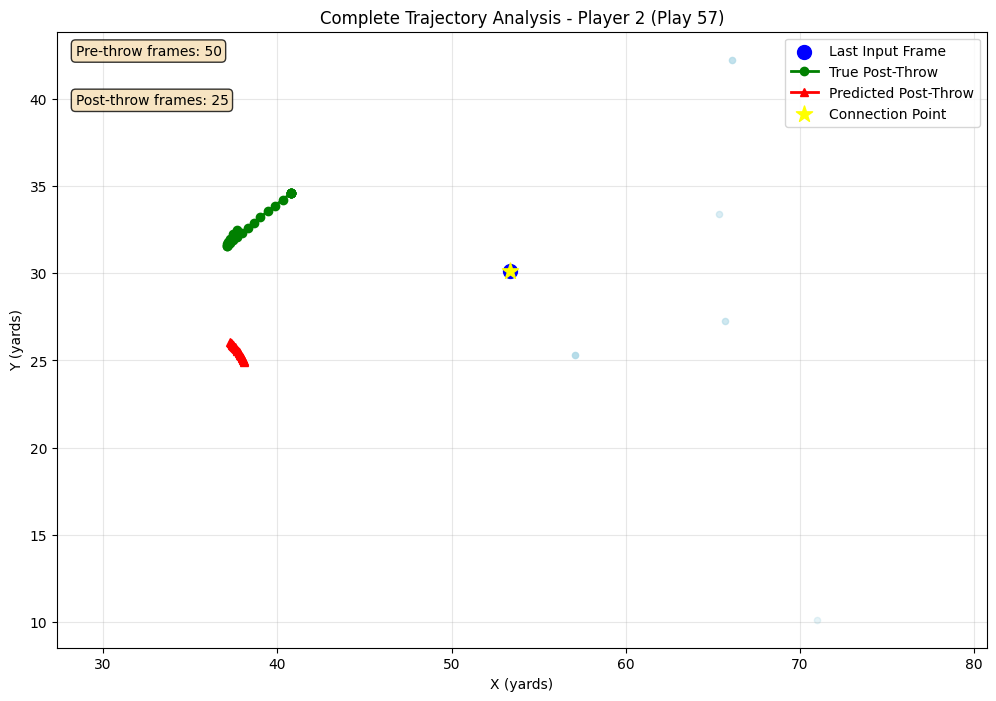


Connection Analysis for Player 2:
Last input position: (53.37, 30.11)
First predicted position: (38.08, 24.93)
First true position: (37.66, 32.50)
Prediction gap: 16.14 yards
True gap: 15.89 yards


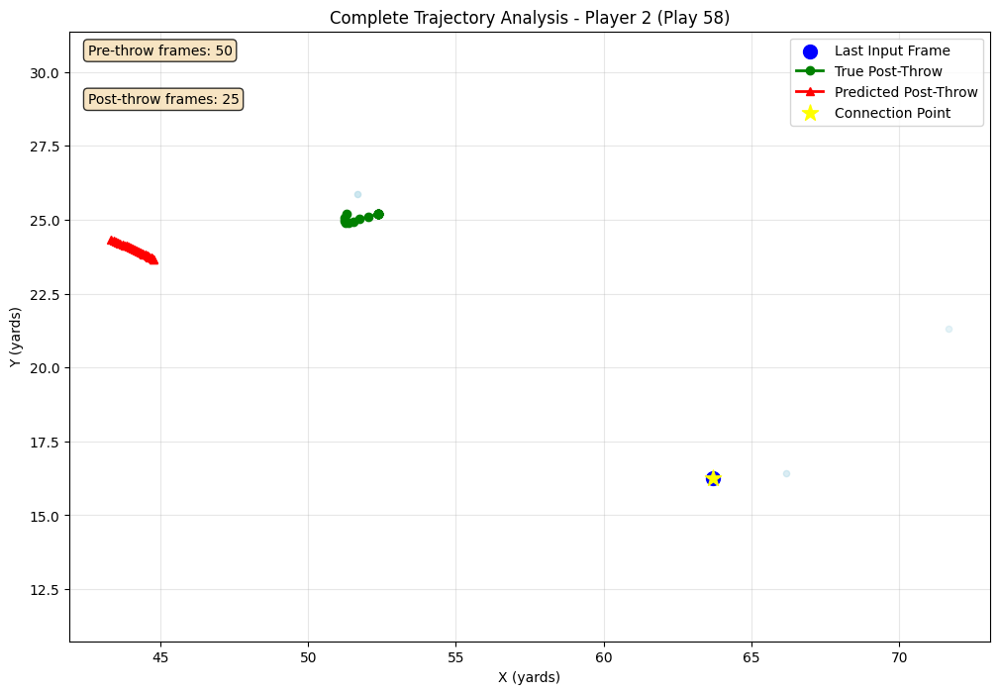


Connection Analysis for Player 2:
Last input position: (63.70, 16.24)
First predicted position: (44.78, 23.64)
First true position: (51.29, 25.20)
Prediction gap: 20.32 yards
True gap: 15.31 yards


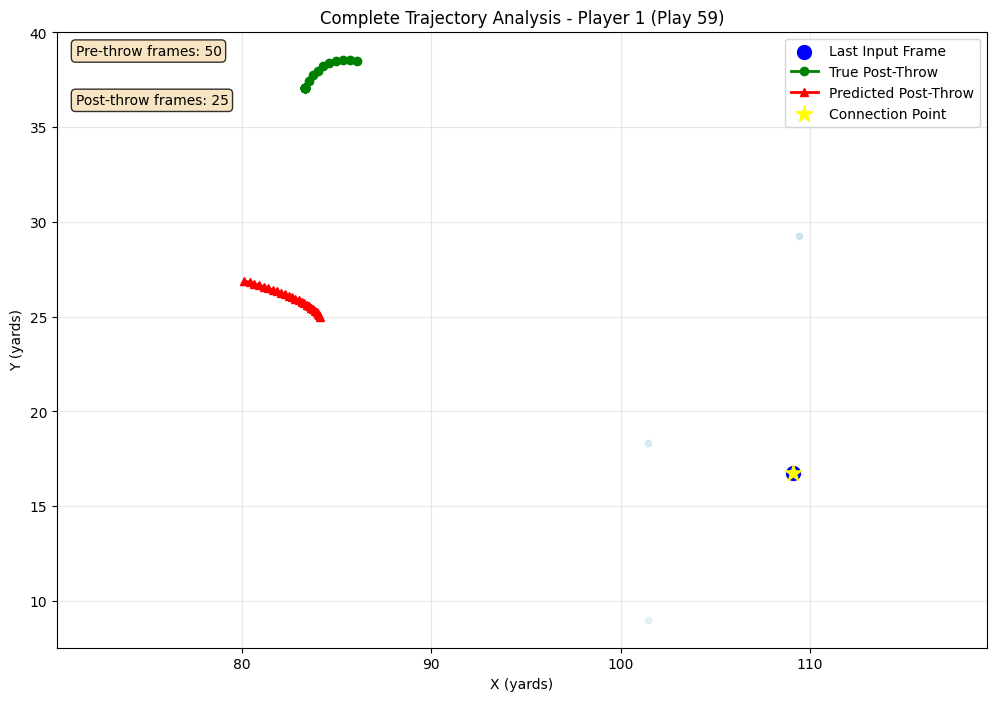


Connection Analysis for Player 1:
Last input position: (109.11, 16.75)
First predicted position: (84.13, 25.01)
First true position: (86.11, 38.50)
Prediction gap: 26.31 yards
True gap: 31.66 yards


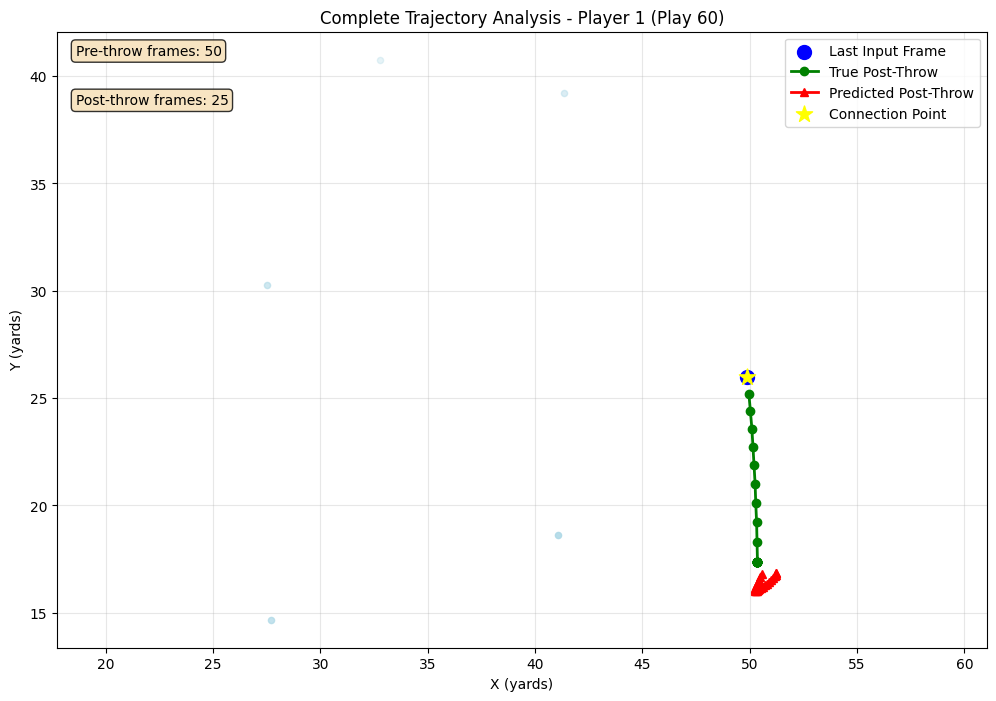


Connection Analysis for Player 1:
Last input position: (49.87, 25.99)
First predicted position: (51.23, 16.86)
First true position: (49.96, 25.20)
Prediction gap: 9.23 yards
True gap: 0.80 yards


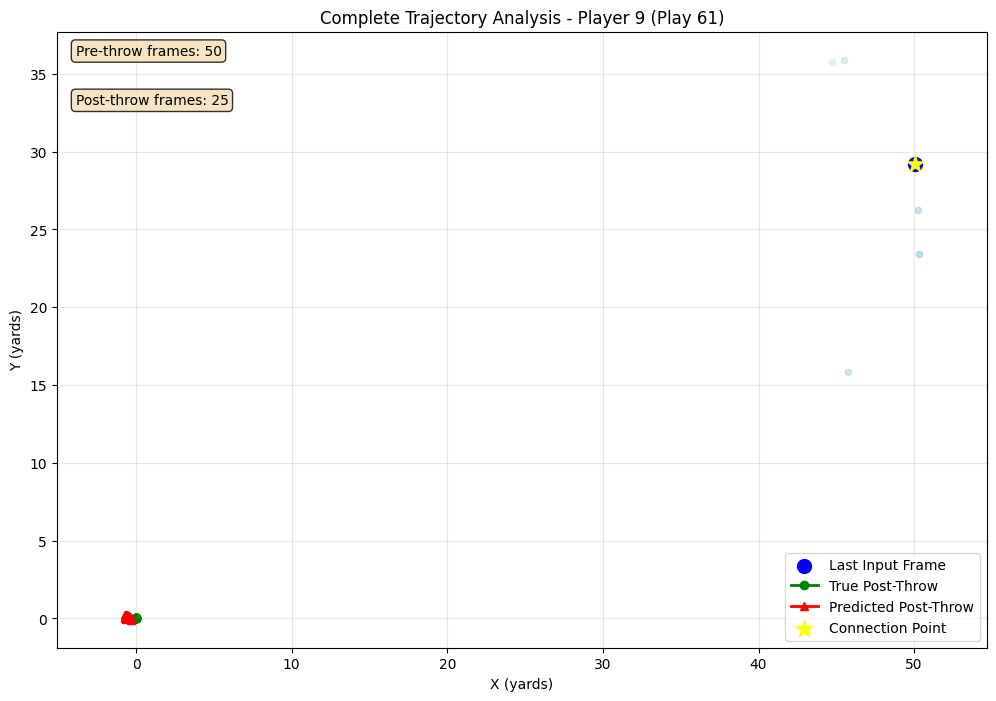


Connection Analysis for Player 9:
Last input position: (50.03, 29.20)
First predicted position: (-0.64, -0.04)
First true position: (0.00, 0.00)
Prediction gap: 58.50 yards
True gap: 57.93 yards


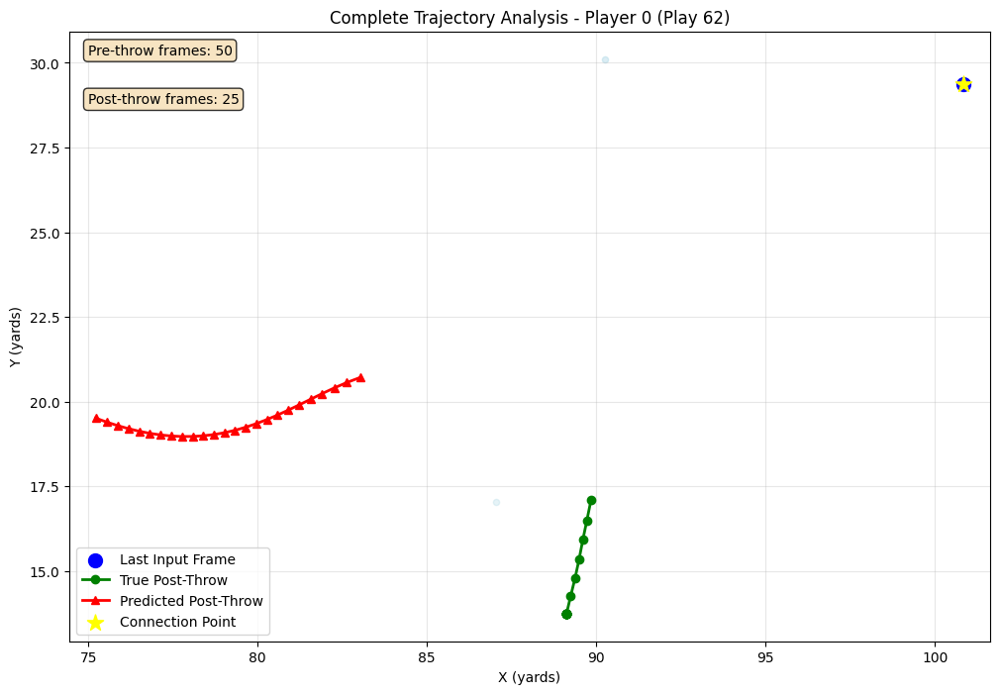


Connection Analysis for Player 0:
Last input position: (100.85, 29.36)
First predicted position: (83.02, 20.71)
First true position: (89.84, 17.08)
Prediction gap: 19.81 yards
True gap: 16.49 yards


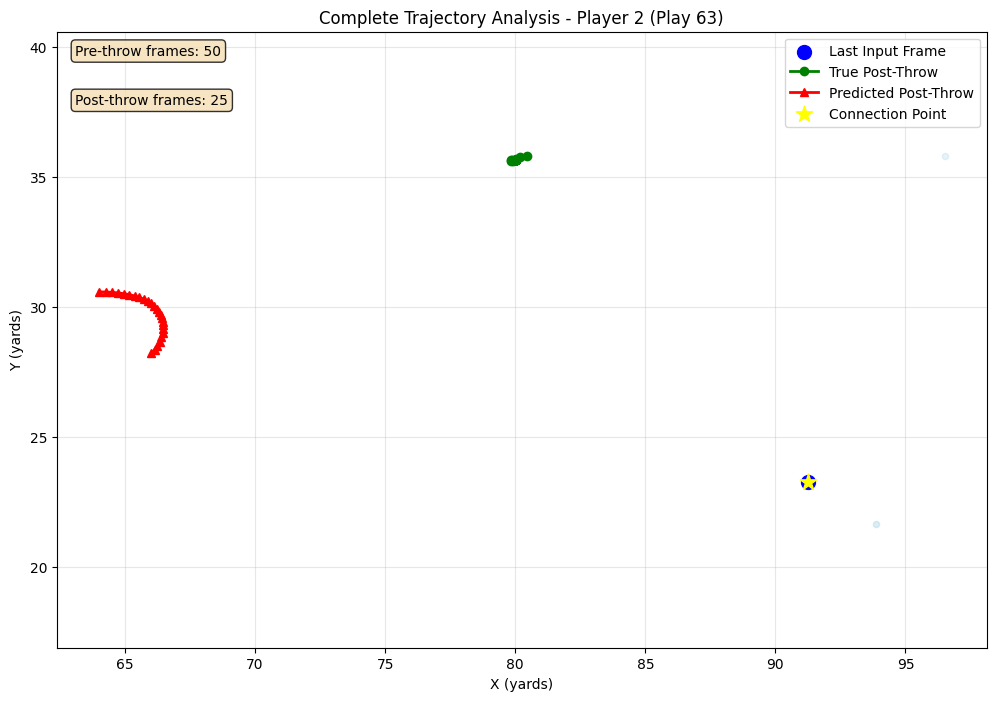


Connection Analysis for Player 2:
Last input position: (91.24, 23.28)
First predicted position: (66.01, 28.22)
First true position: (80.44, 35.82)
Prediction gap: 25.71 yards
True gap: 16.55 yards


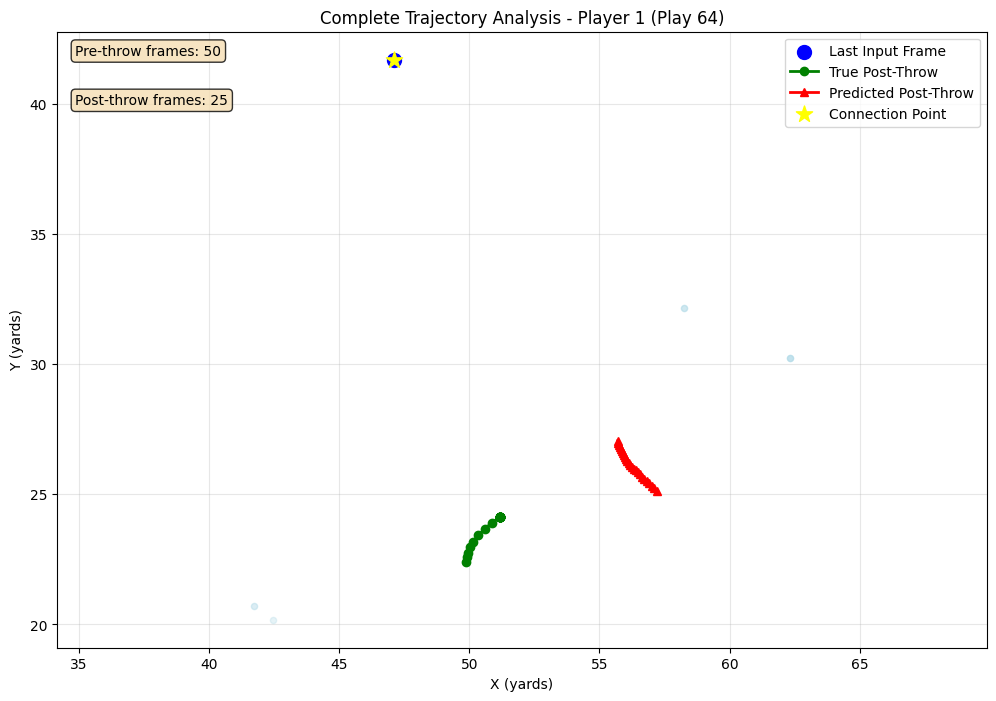


Connection Analysis for Player 1:
Last input position: (47.11, 41.69)
First predicted position: (57.21, 25.12)
First true position: (49.89, 22.40)
Prediction gap: 19.40 yards
True gap: 19.49 yards


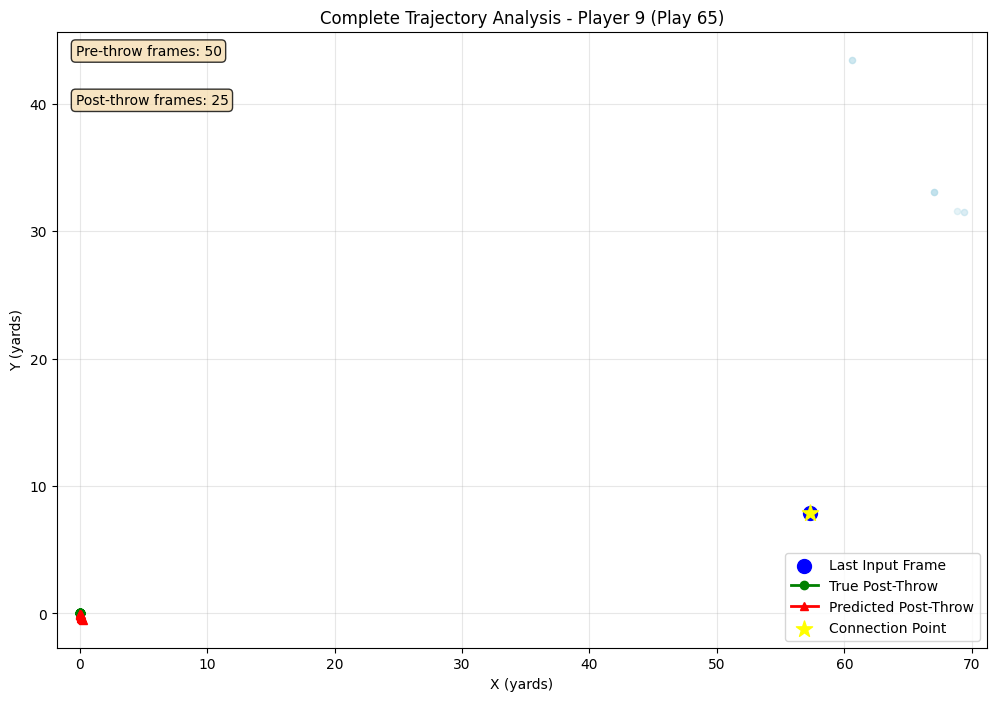


Connection Analysis for Player 9:
Last input position: (57.31, 7.86)
First predicted position: (0.25, -0.49)
First true position: (0.00, 0.00)
Prediction gap: 57.66 yards
True gap: 57.85 yards


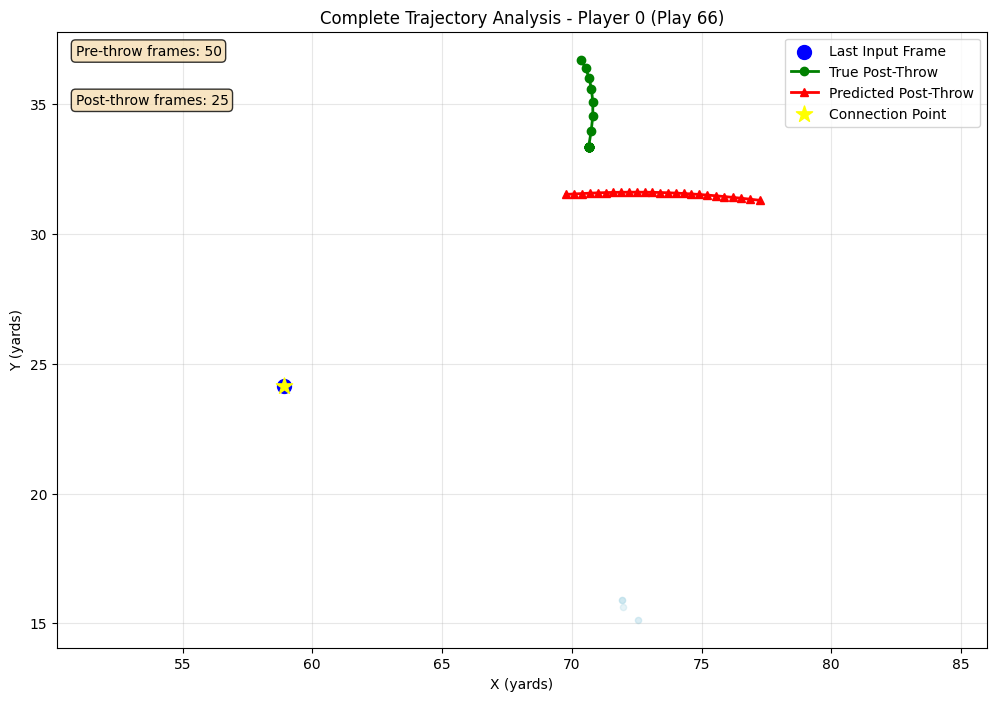


Connection Analysis for Player 0:
Last input position: (58.91, 24.14)
First predicted position: (77.25, 31.30)
First true position: (70.35, 36.72)
Prediction gap: 19.69 yards
True gap: 17.00 yards


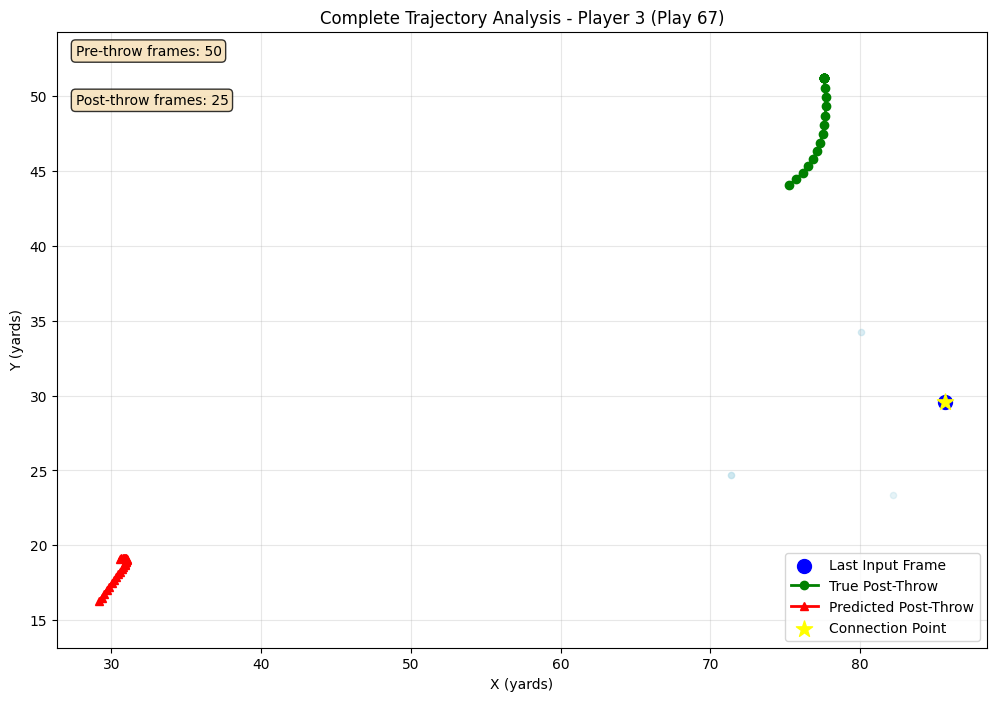


Connection Analysis for Player 3:
Last input position: (85.64, 29.56)
First predicted position: (29.18, 16.26)
First true position: (75.26, 44.08)
Prediction gap: 58.01 yards
True gap: 17.85 yards


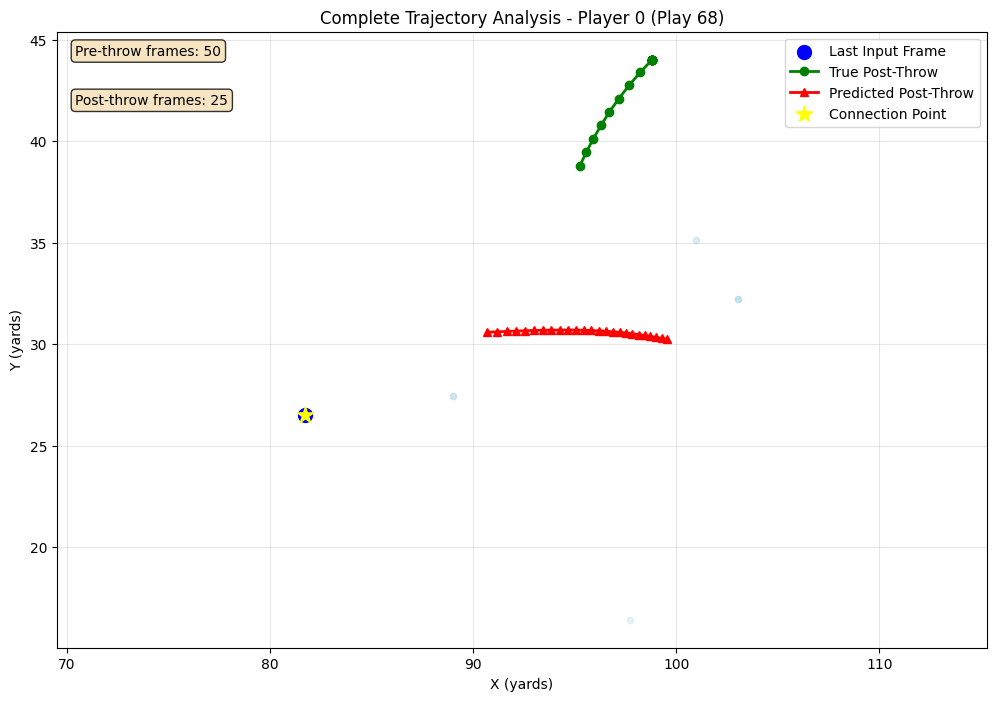


Connection Analysis for Player 0:
Last input position: (81.73, 26.50)
First predicted position: (99.54, 30.23)
First true position: (95.26, 38.80)
Prediction gap: 18.20 yards
True gap: 18.29 yards


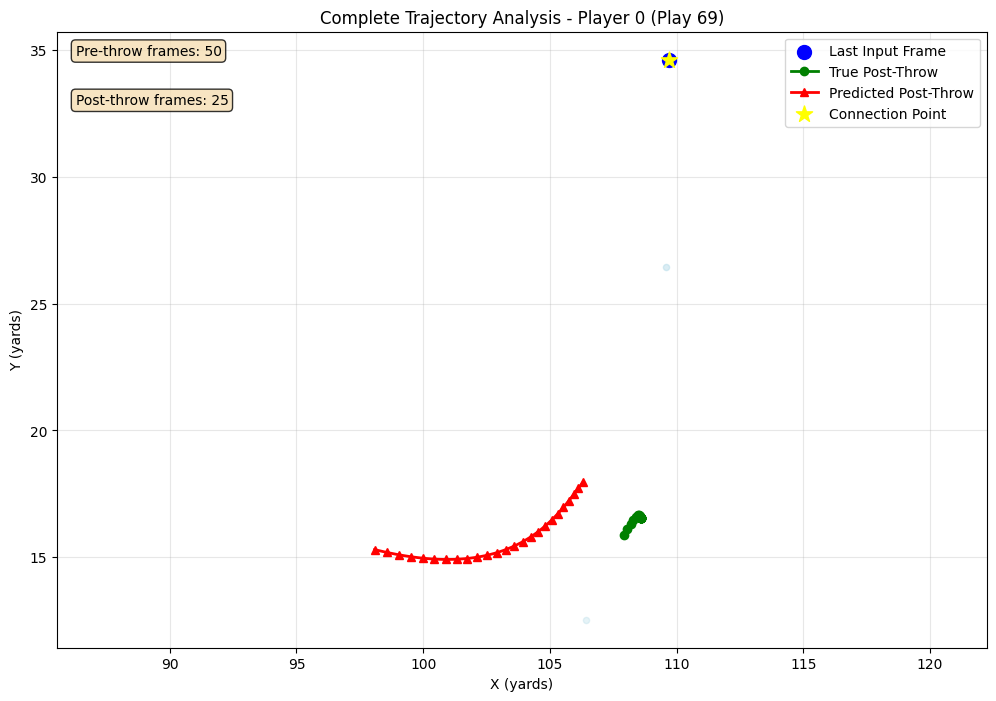


Connection Analysis for Player 0:
Last input position: (109.71, 34.63)
First predicted position: (106.31, 17.96)
First true position: (107.91, 15.88)
Prediction gap: 17.02 yards
True gap: 18.84 yards


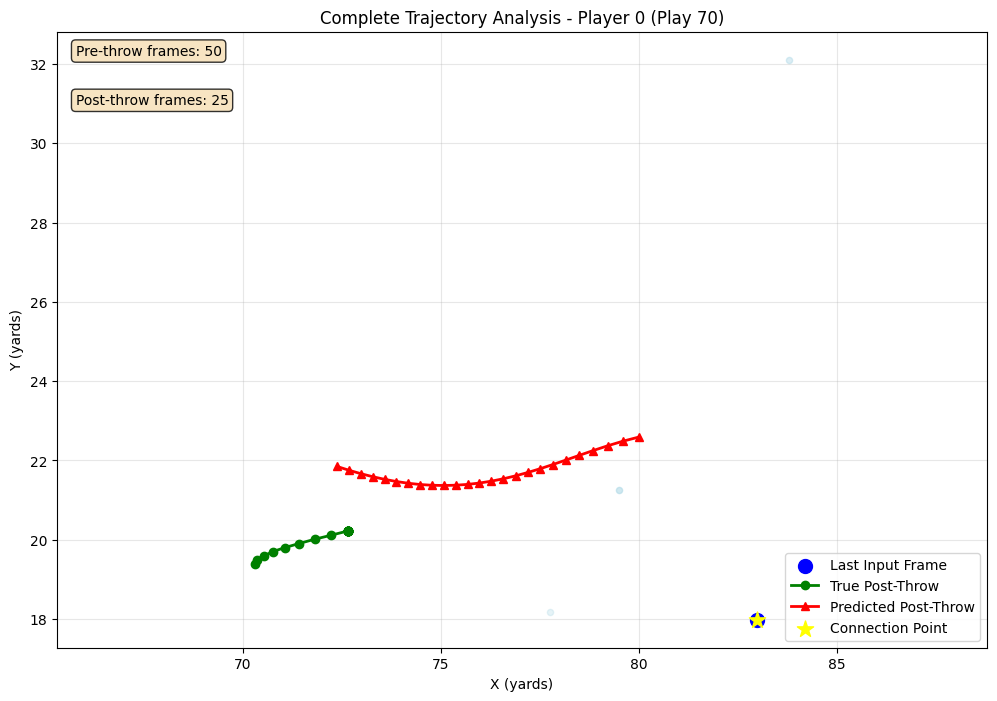


Connection Analysis for Player 0:
Last input position: (82.98, 17.98)
First predicted position: (79.99, 22.59)
First true position: (70.31, 19.38)
Prediction gap: 5.49 yards
True gap: 12.75 yards


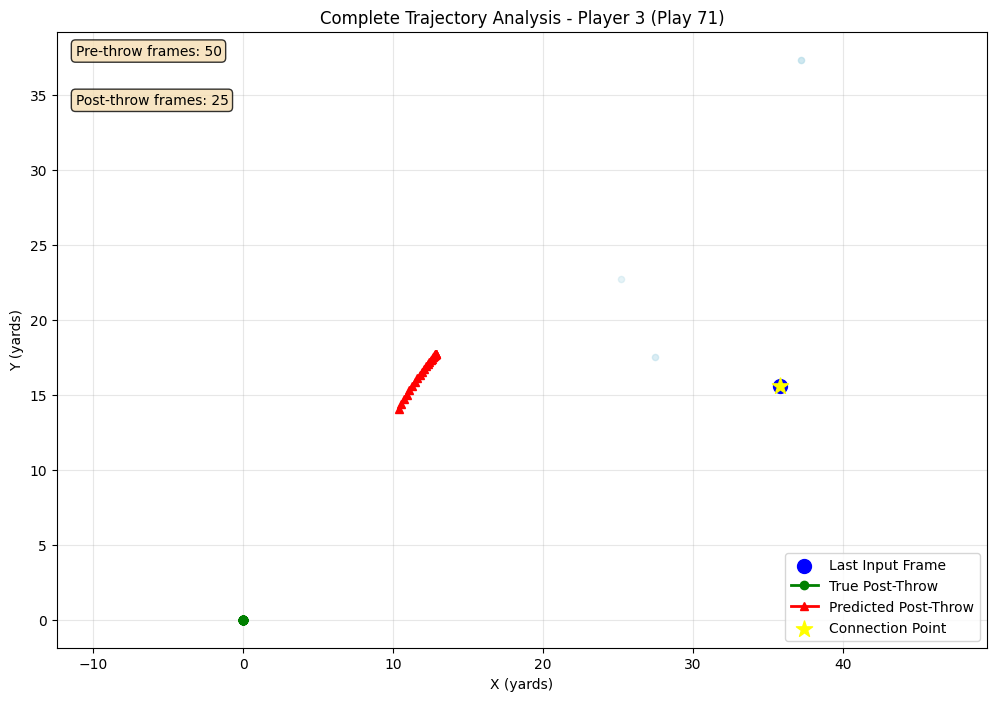


Connection Analysis for Player 3:
Last input position: (35.80, 15.60)
First predicted position: (10.39, 14.05)
First true position: (0.00, 0.00)
Prediction gap: 25.46 yards
True gap: 39.05 yards


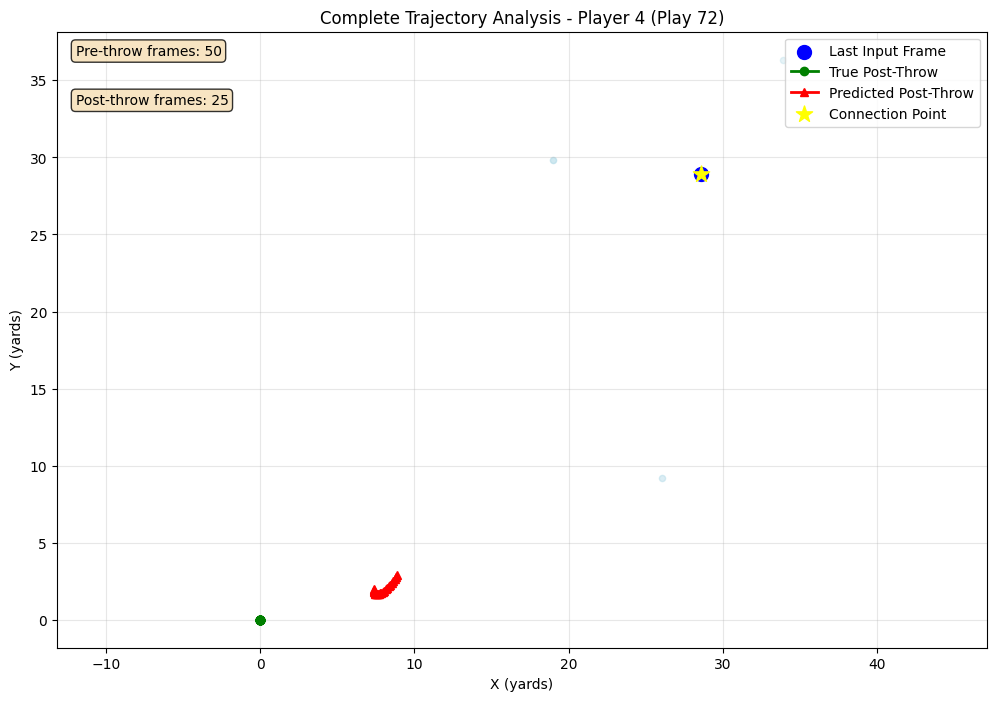


Connection Analysis for Player 4:
Last input position: (28.56, 28.92)
First predicted position: (8.86, 2.92)
First true position: (0.00, 0.00)
Prediction gap: 32.62 yards
True gap: 40.65 yards


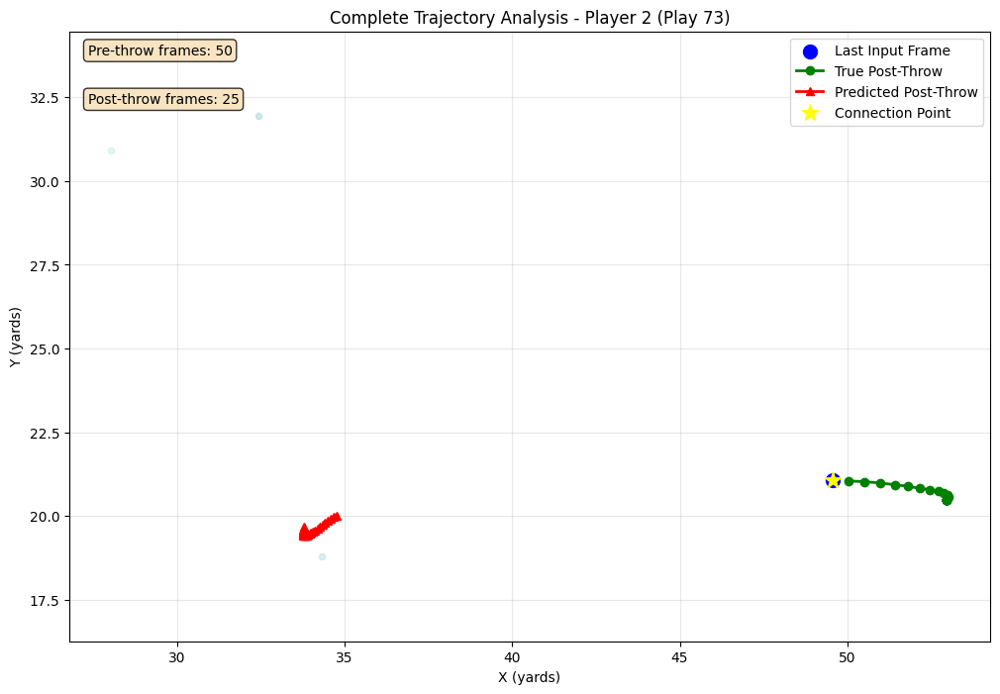


Connection Analysis for Player 2:
Last input position: (49.57, 21.06)
First predicted position: (34.77, 20.02)
First true position: (50.04, 21.05)
Prediction gap: 14.83 yards
True gap: 0.47 yards


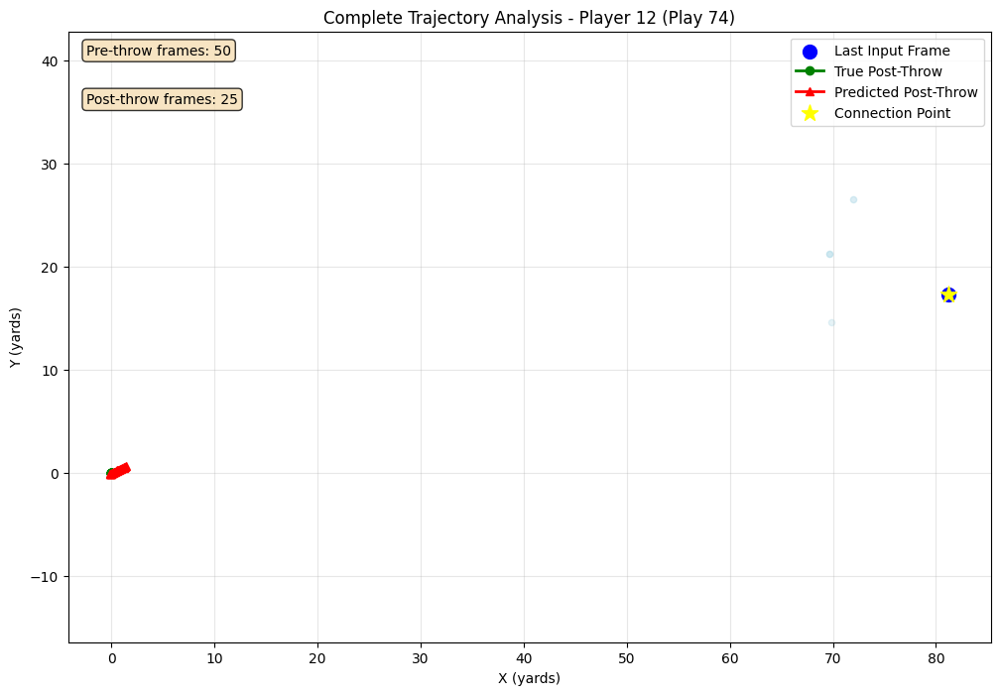


Connection Analysis for Player 12:
Last input position: (81.23, 17.27)
First predicted position: (1.44, 0.66)
First true position: (0.00, 0.00)
Prediction gap: 81.51 yards
True gap: 83.05 yards


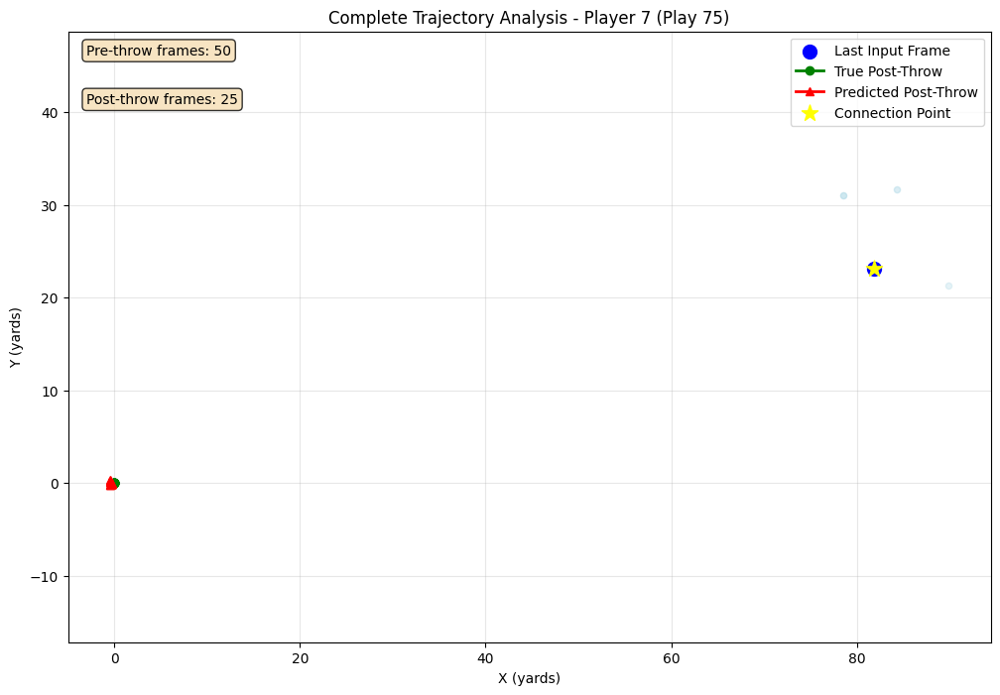


Connection Analysis for Player 7:
Last input position: (81.89, 23.16)
First predicted position: (-0.47, 0.35)
First true position: (0.00, 0.00)
Prediction gap: 85.46 yards
True gap: 85.10 yards


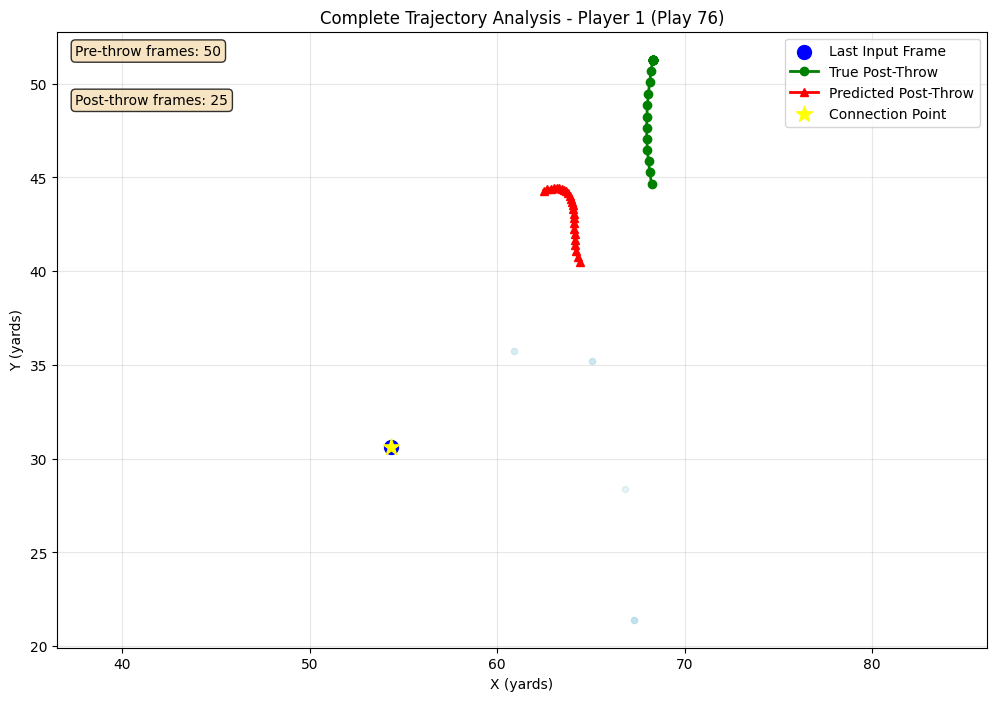


Connection Analysis for Player 1:
Last input position: (54.34, 30.64)
First predicted position: (64.41, 40.49)
First true position: (68.24, 44.67)
Prediction gap: 14.09 yards
True gap: 19.75 yards


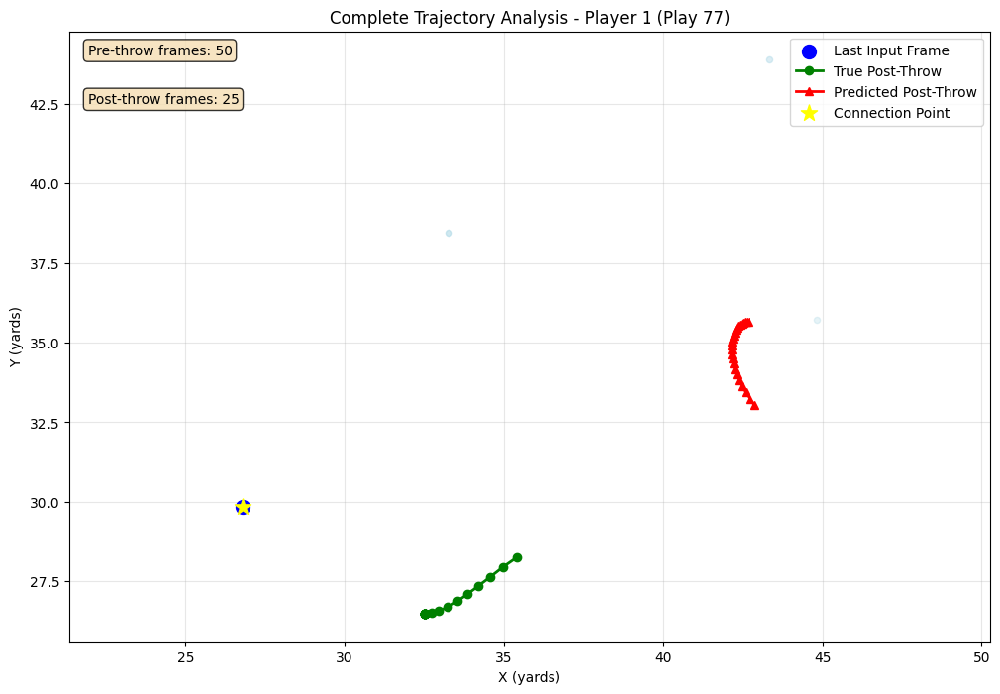


Connection Analysis for Player 1:
Last input position: (26.80, 29.84)
First predicted position: (42.88, 33.03)
First true position: (35.40, 28.25)
Prediction gap: 16.39 yards
True gap: 8.75 yards


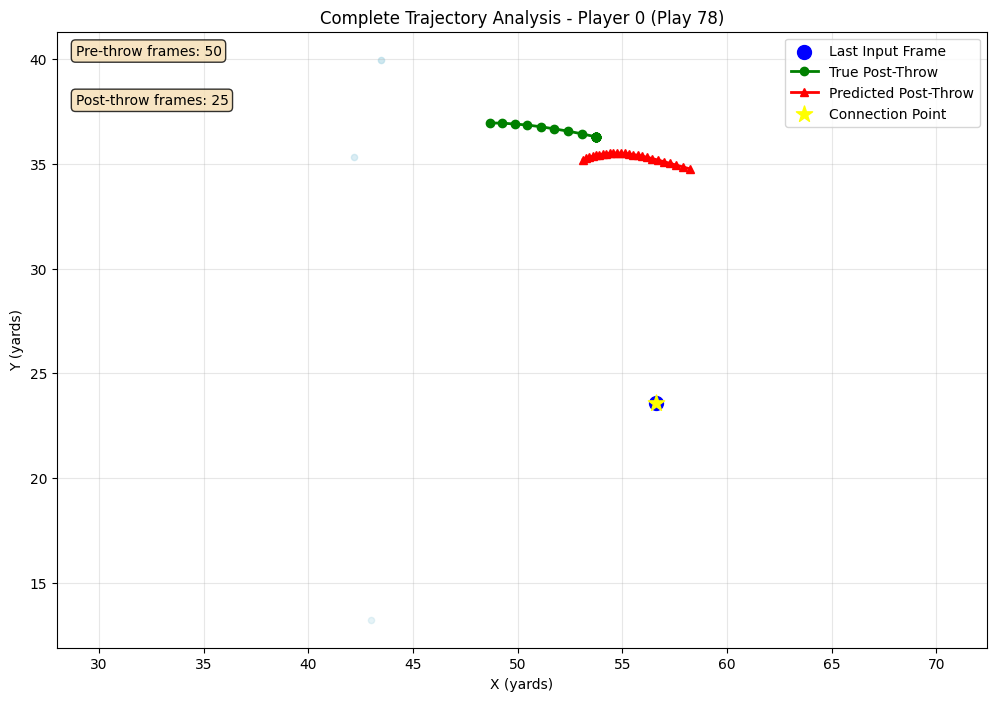


Connection Analysis for Player 0:
Last input position: (56.62, 23.58)
First predicted position: (58.24, 34.76)
First true position: (48.70, 36.96)
Prediction gap: 11.30 yards
True gap: 15.55 yards


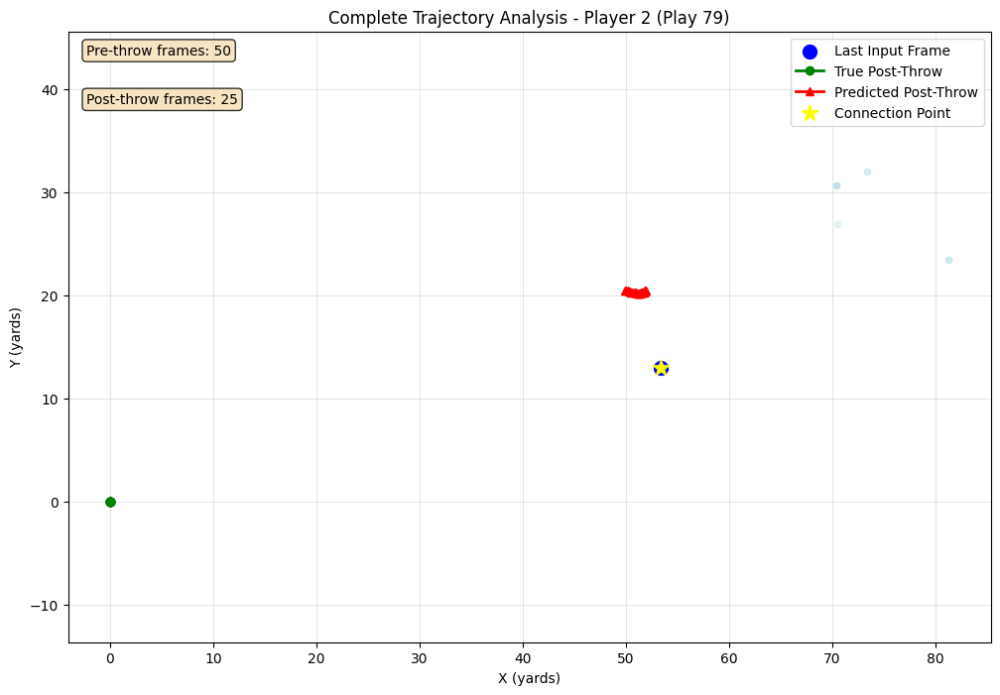


Connection Analysis for Player 2:
Last input position: (53.43, 12.97)
First predicted position: (51.91, 20.50)
First true position: (0.00, 0.00)
Prediction gap: 7.68 yards
True gap: 54.98 yards


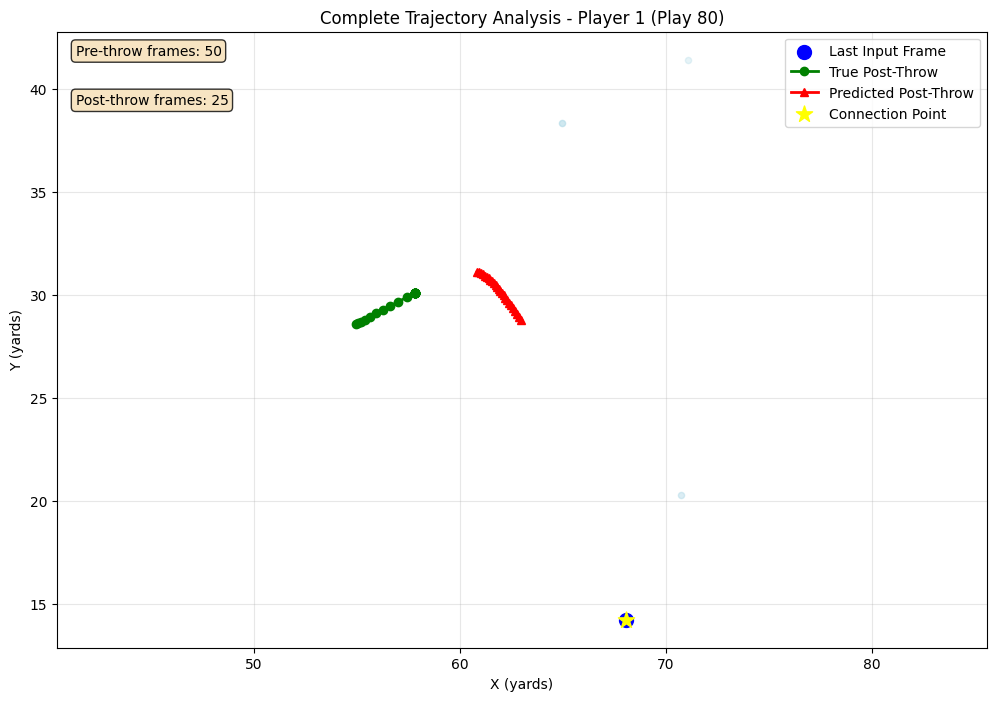


Connection Analysis for Player 1:
Last input position: (68.06, 14.25)
First predicted position: (62.98, 28.80)
First true position: (54.94, 28.62)
Prediction gap: 15.41 yards
True gap: 19.46 yards


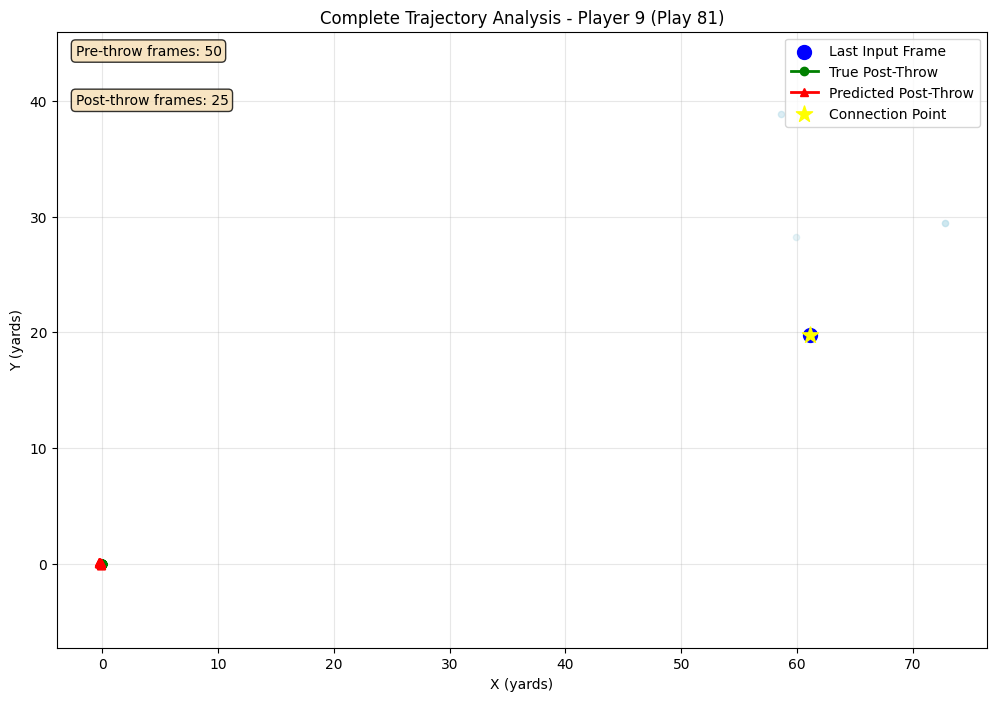


Connection Analysis for Player 9:
Last input position: (61.15, 19.77)
First predicted position: (-0.21, 0.04)
First true position: (0.00, 0.00)
Prediction gap: 64.45 yards
True gap: 64.27 yards


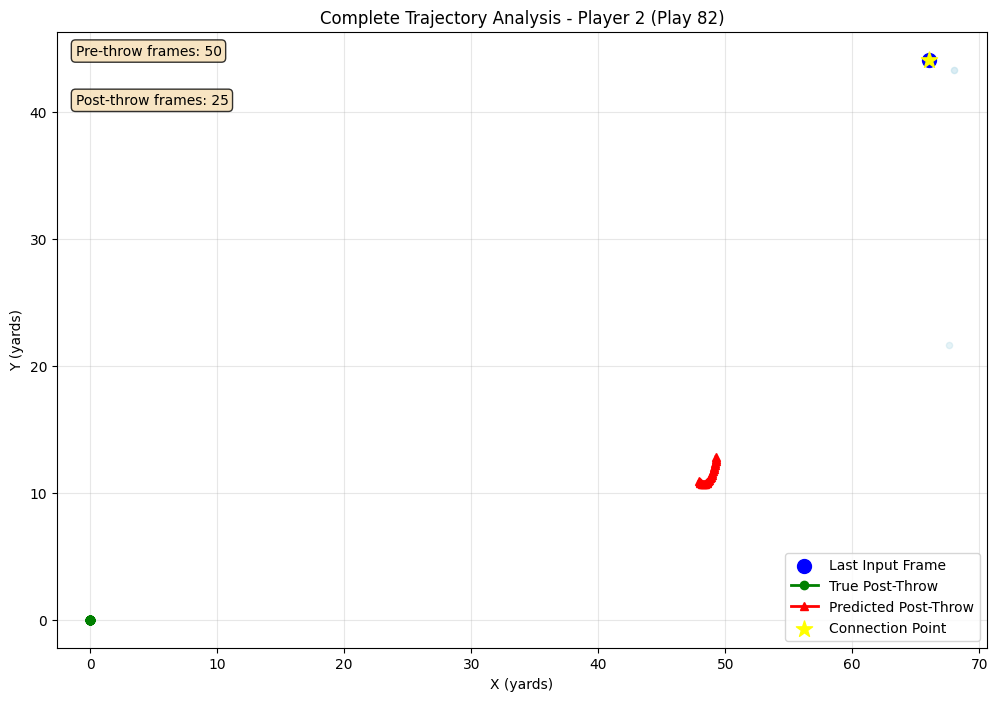


Connection Analysis for Player 2:
Last input position: (66.08, 44.09)
First predicted position: (49.27, 12.83)
First true position: (0.00, 0.00)
Prediction gap: 35.50 yards
True gap: 79.44 yards


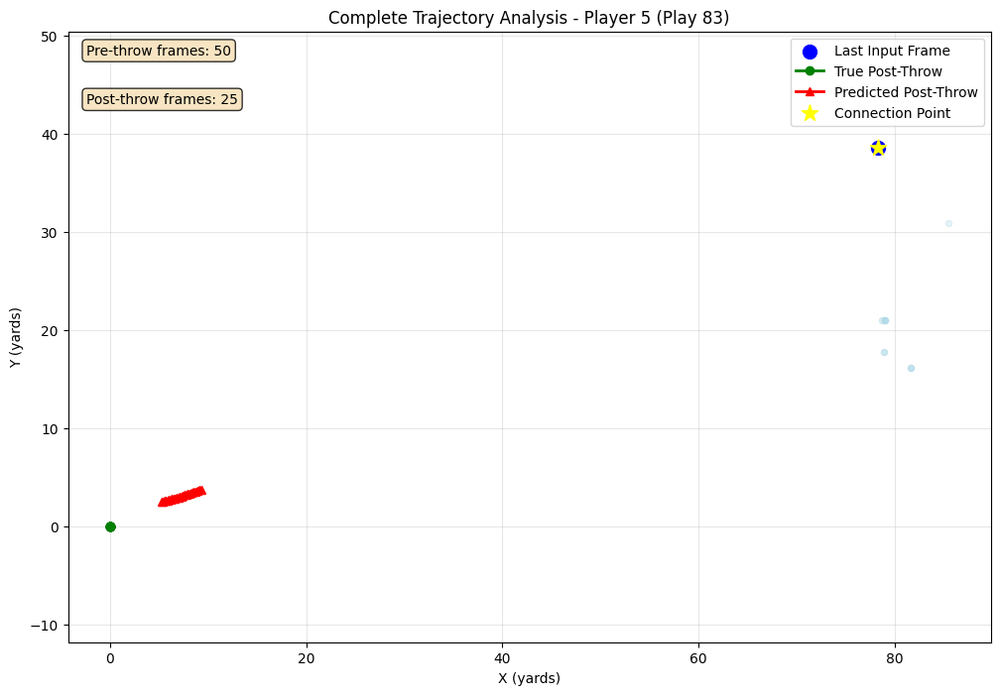


Connection Analysis for Player 5:
Last input position: (78.22, 38.66)
First predicted position: (9.33, 3.77)
First true position: (0.00, 0.00)
Prediction gap: 77.22 yards
True gap: 87.25 yards


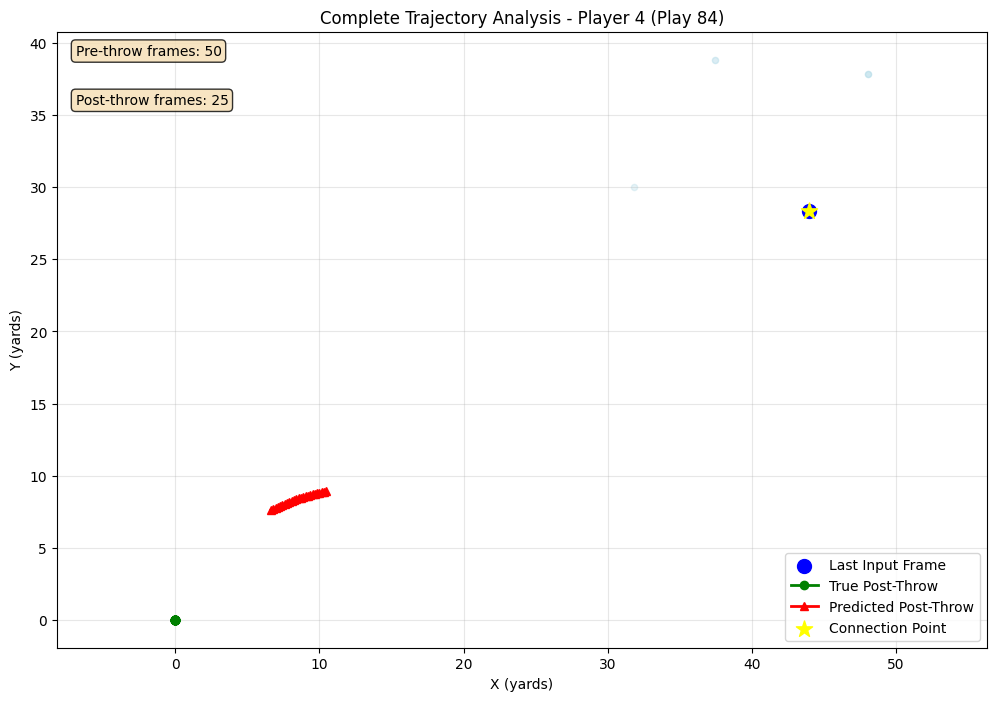


Connection Analysis for Player 4:
Last input position: (43.93, 28.36)
First predicted position: (10.43, 8.91)
First true position: (0.00, 0.00)
Prediction gap: 38.73 yards
True gap: 52.29 yards


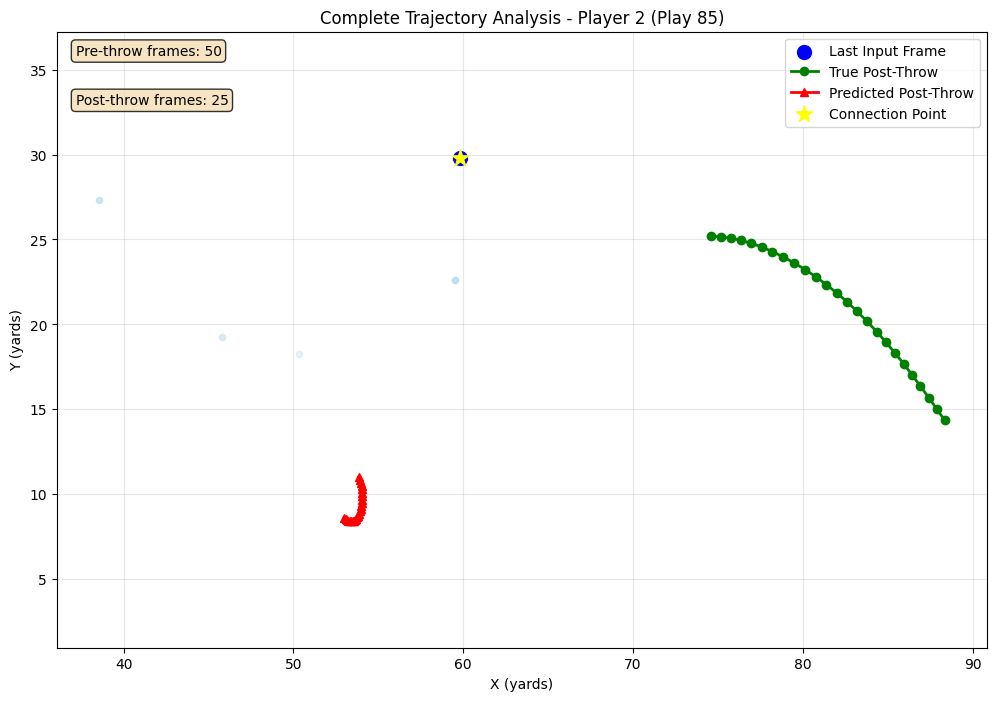


Connection Analysis for Player 2:
Last input position: (59.79, 29.80)
First predicted position: (53.83, 11.01)
First true position: (74.59, 25.19)
Prediction gap: 19.71 yards
True gap: 15.50 yards


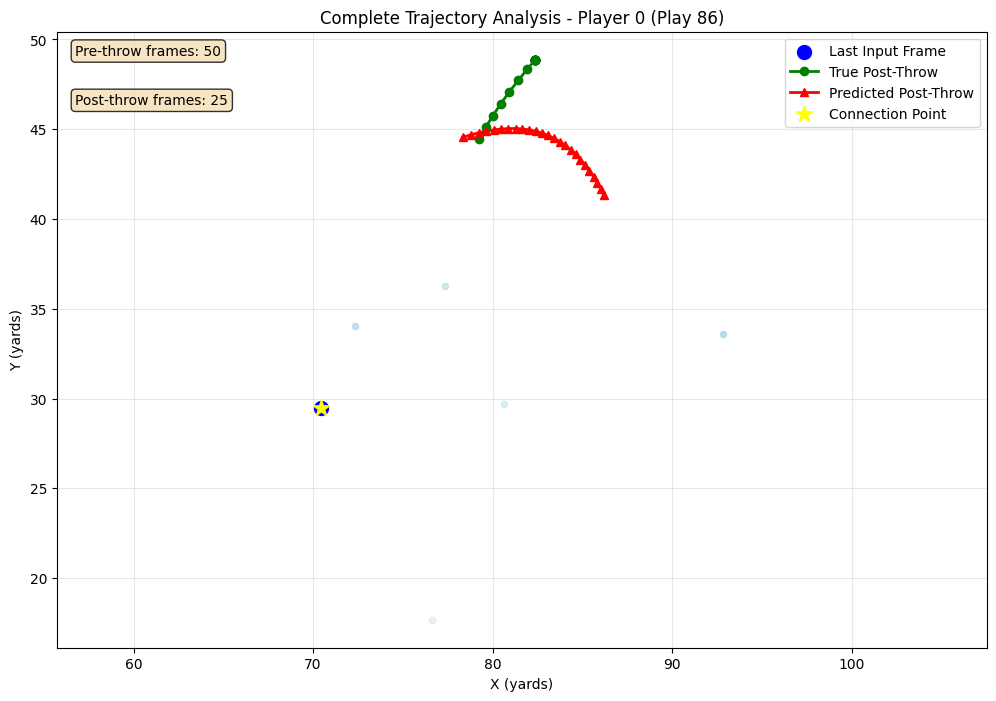


Connection Analysis for Player 0:
Last input position: (70.42, 29.49)
First predicted position: (86.21, 41.35)
First true position: (79.24, 44.43)
Prediction gap: 19.75 yards
True gap: 17.35 yards


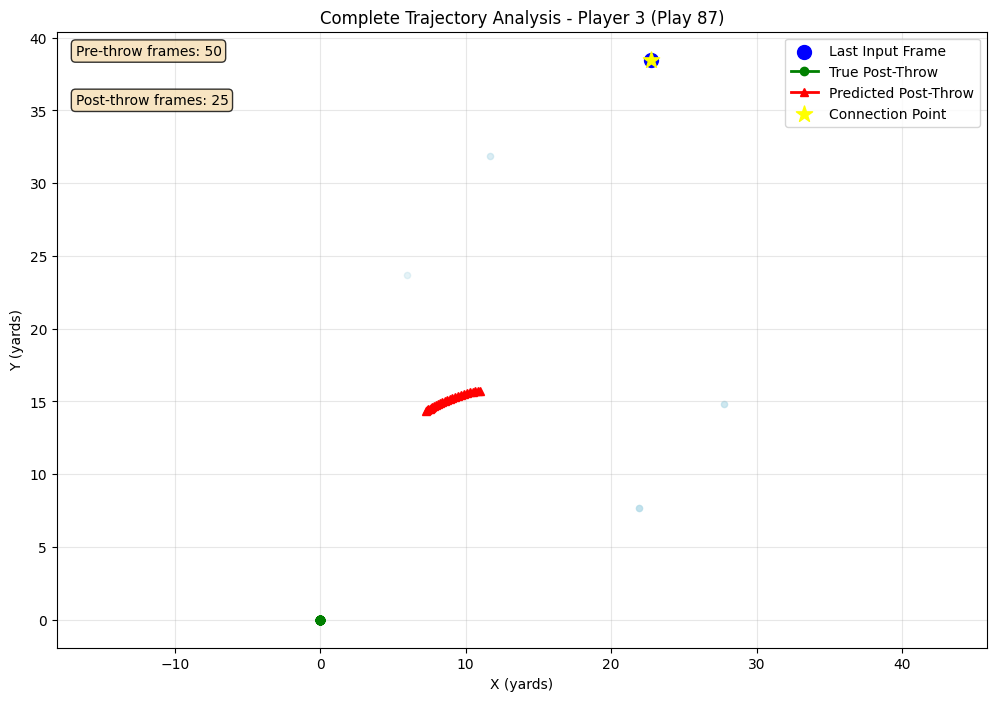


Connection Analysis for Player 3:
Last input position: (22.75, 38.49)
First predicted position: (10.97, 15.74)
First true position: (0.00, 0.00)
Prediction gap: 25.62 yards
True gap: 44.71 yards


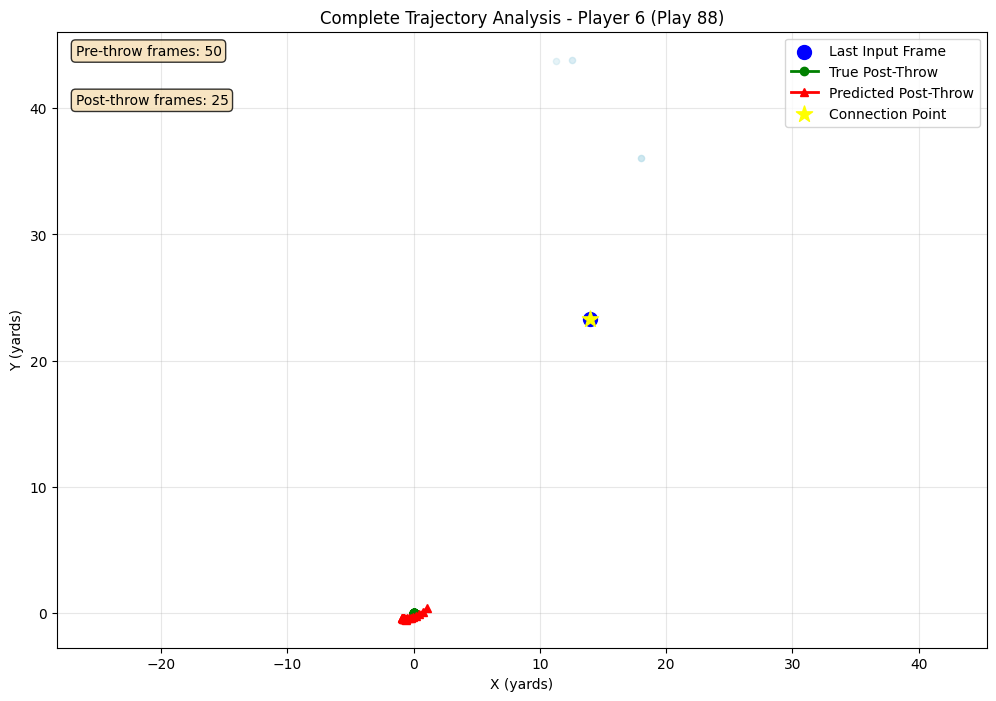


Connection Analysis for Player 6:
Last input position: (13.99, 23.28)
First predicted position: (1.07, 0.38)
First true position: (0.00, 0.00)
Prediction gap: 26.29 yards
True gap: 27.16 yards


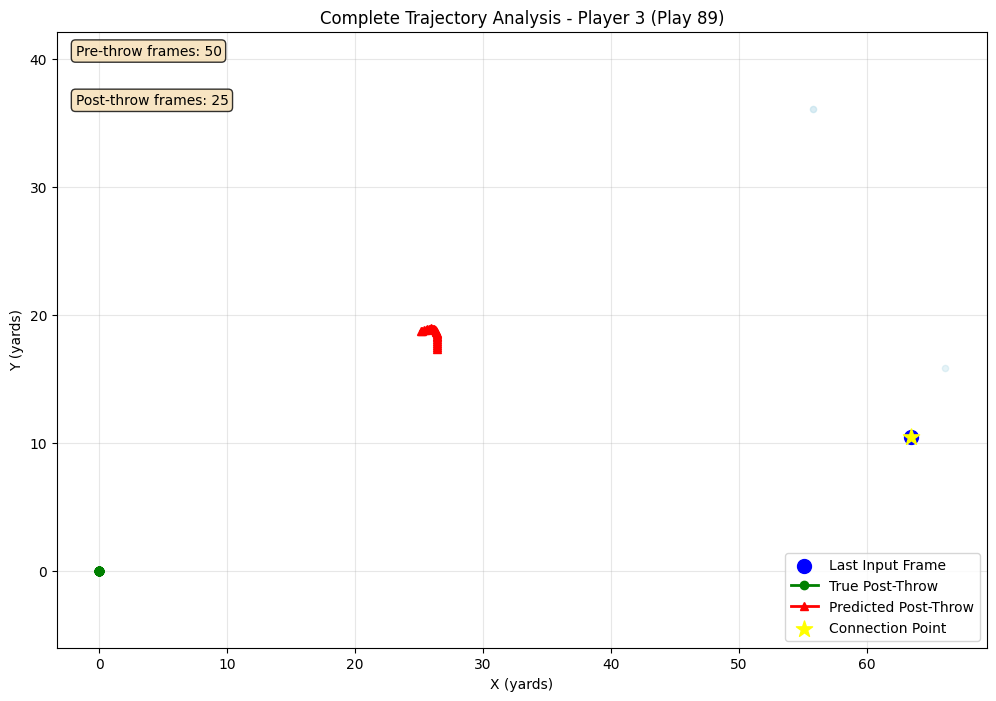


Connection Analysis for Player 3:
Last input position: (63.42, 10.42)
First predicted position: (26.41, 17.30)
First true position: (0.00, 0.00)
Prediction gap: 37.65 yards
True gap: 64.27 yards


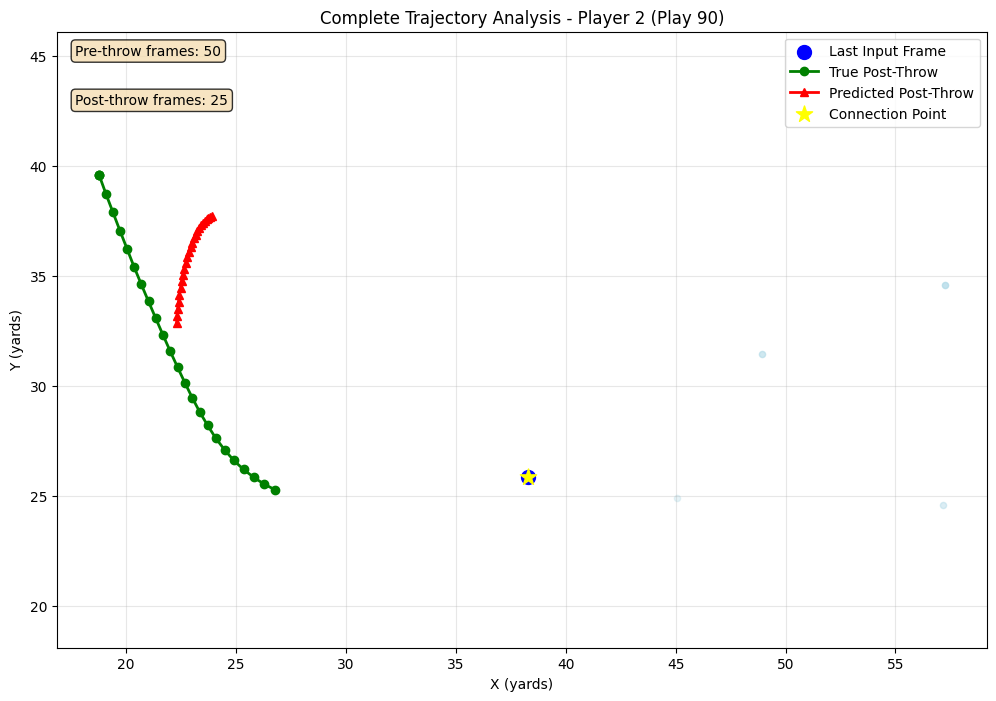


Connection Analysis for Player 2:
Last input position: (38.31, 25.87)
First predicted position: (22.31, 32.87)
First true position: (26.78, 25.29)
Prediction gap: 17.47 yards
True gap: 11.54 yards


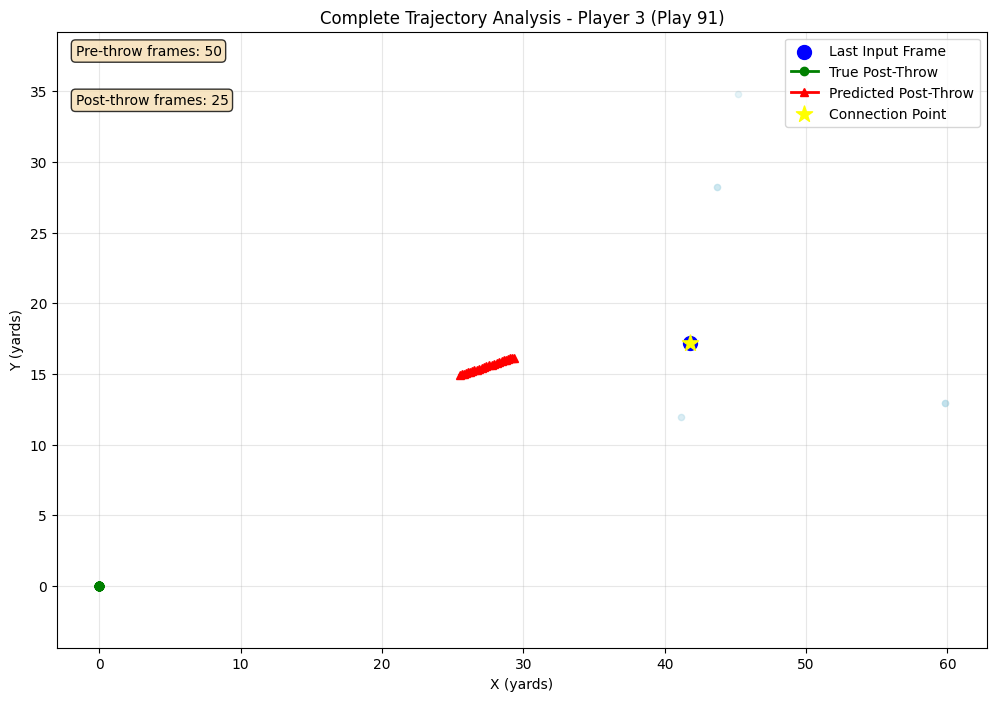


Connection Analysis for Player 3:
Last input position: (41.79, 17.19)
First predicted position: (29.32, 16.15)
First true position: (0.00, 0.00)
Prediction gap: 12.52 yards
True gap: 45.19 yards


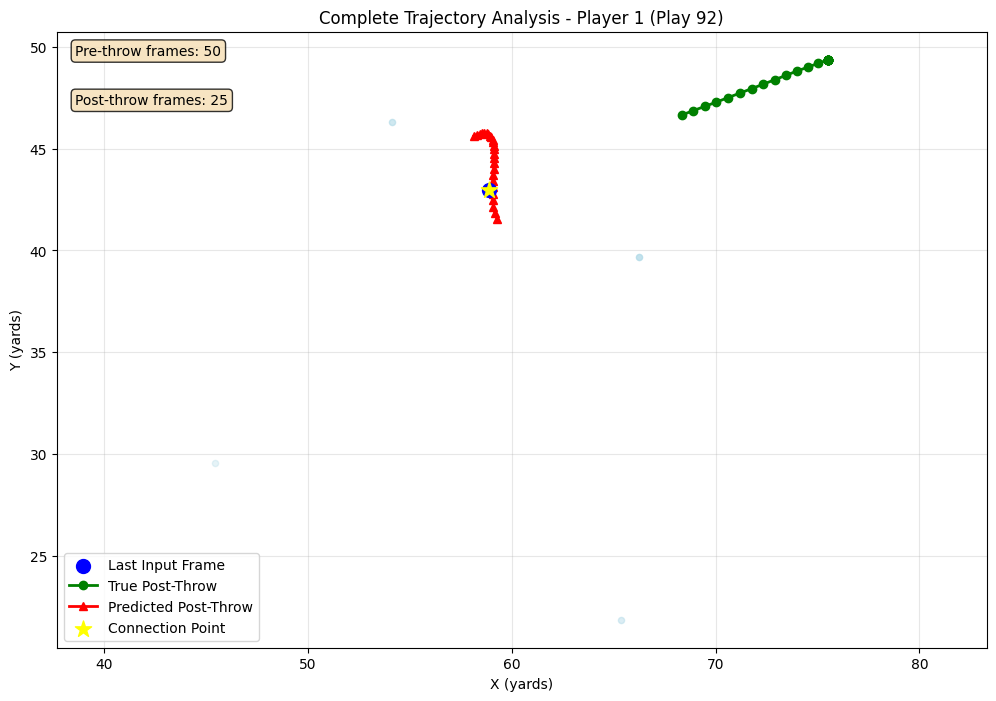


Connection Analysis for Player 1:
Last input position: (58.86, 42.95)
First predicted position: (59.27, 41.55)
First true position: (68.35, 46.65)
Prediction gap: 1.46 yards
True gap: 10.19 yards


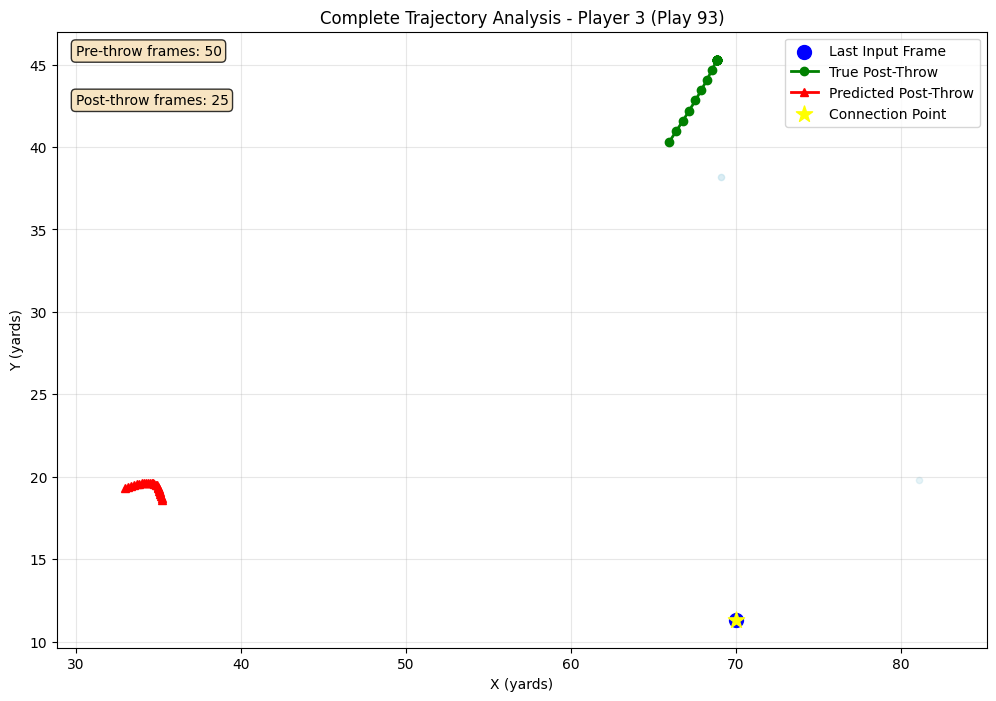


Connection Analysis for Player 3:
Last input position: (70.05, 11.33)
First predicted position: (35.23, 18.58)
First true position: (65.98, 40.32)
Prediction gap: 35.57 yards
True gap: 29.27 yards


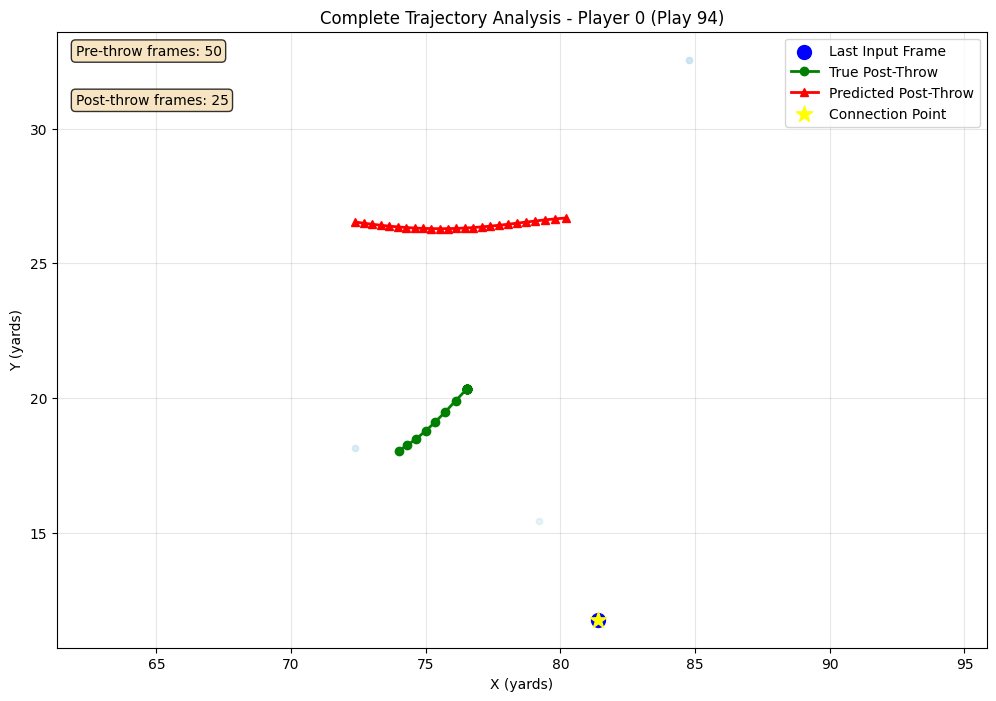


Connection Analysis for Player 0:
Last input position: (81.40, 11.77)
First predicted position: (80.19, 26.68)
First true position: (73.99, 18.04)
Prediction gap: 14.96 yards
True gap: 9.71 yards


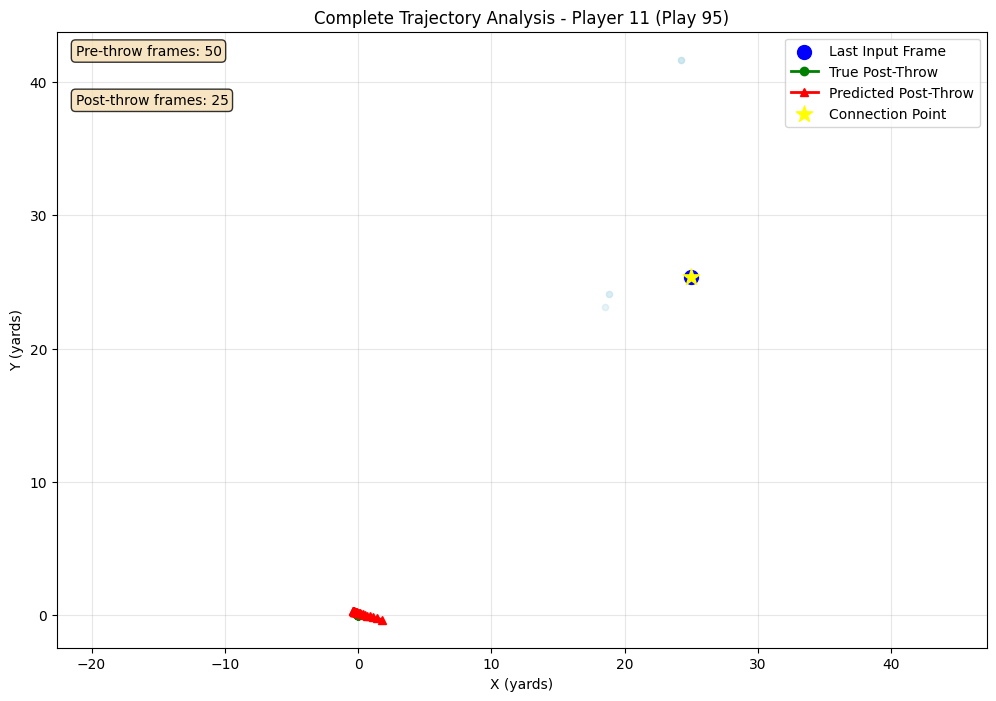


Connection Analysis for Player 11:
Last input position: (24.97, 25.36)
First predicted position: (1.81, -0.35)
First true position: (0.00, 0.00)
Prediction gap: 34.60 yards
True gap: 35.59 yards


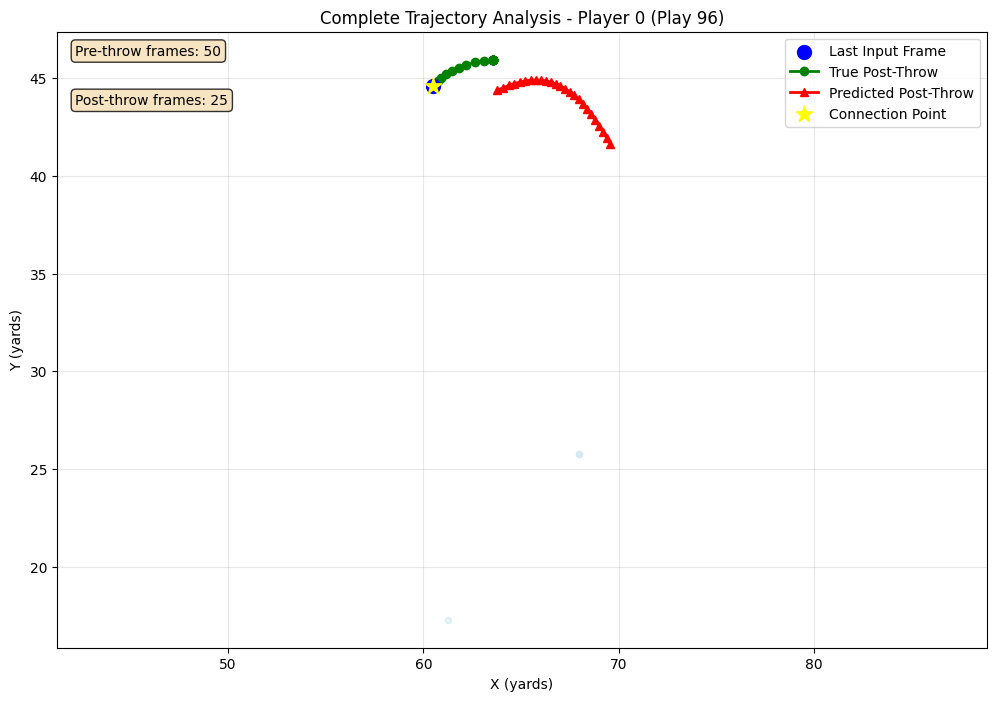


Connection Analysis for Player 0:
Last input position: (60.50, 44.58)
First predicted position: (69.57, 41.63)
First true position: (60.60, 44.73)
Prediction gap: 9.54 yards
True gap: 0.18 yards


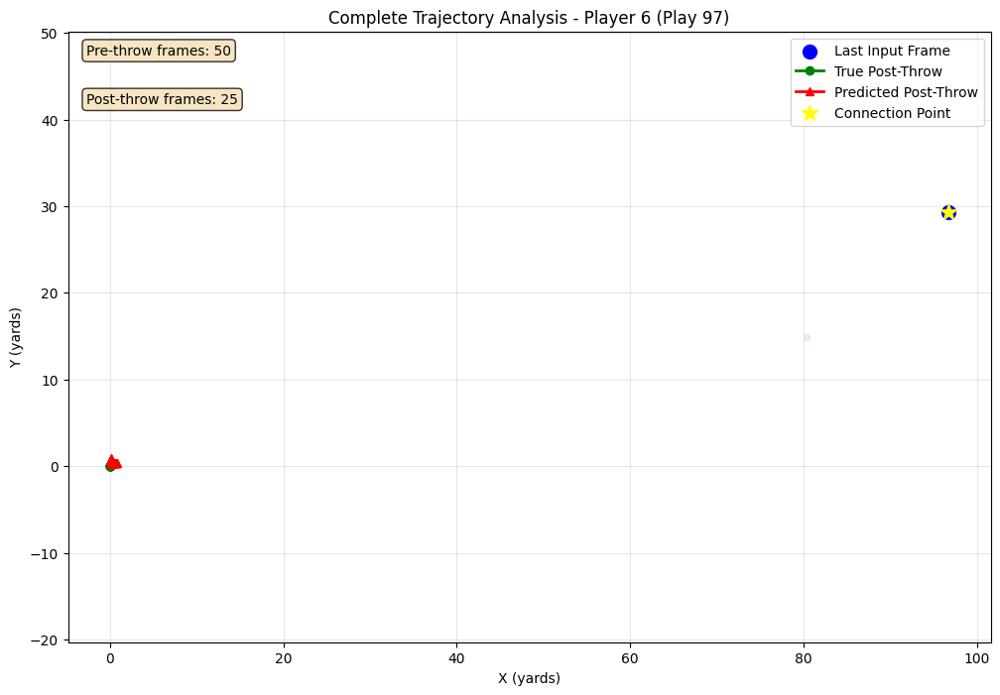


Connection Analysis for Player 6:
Last input position: (96.73, 29.31)
First predicted position: (0.16, 0.88)
First true position: (0.00, 0.00)
Prediction gap: 100.67 yards
True gap: 101.07 yards


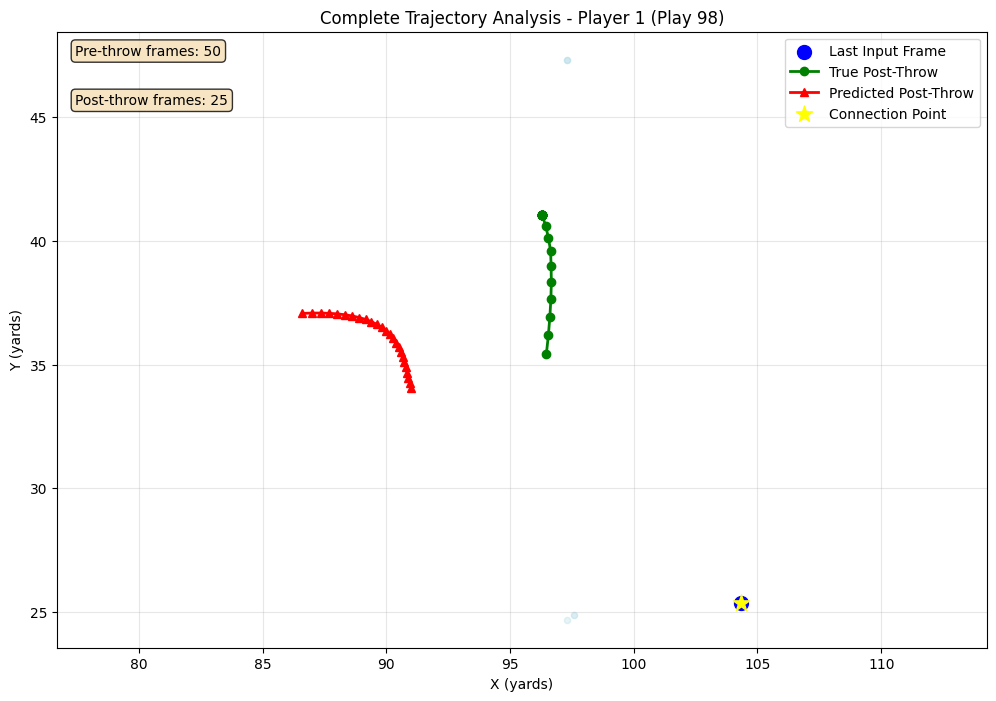


Connection Analysis for Player 1:
Last input position: (104.34, 25.36)
First predicted position: (91.01, 34.06)
First true position: (96.47, 35.44)
Prediction gap: 15.91 yards
True gap: 12.79 yards


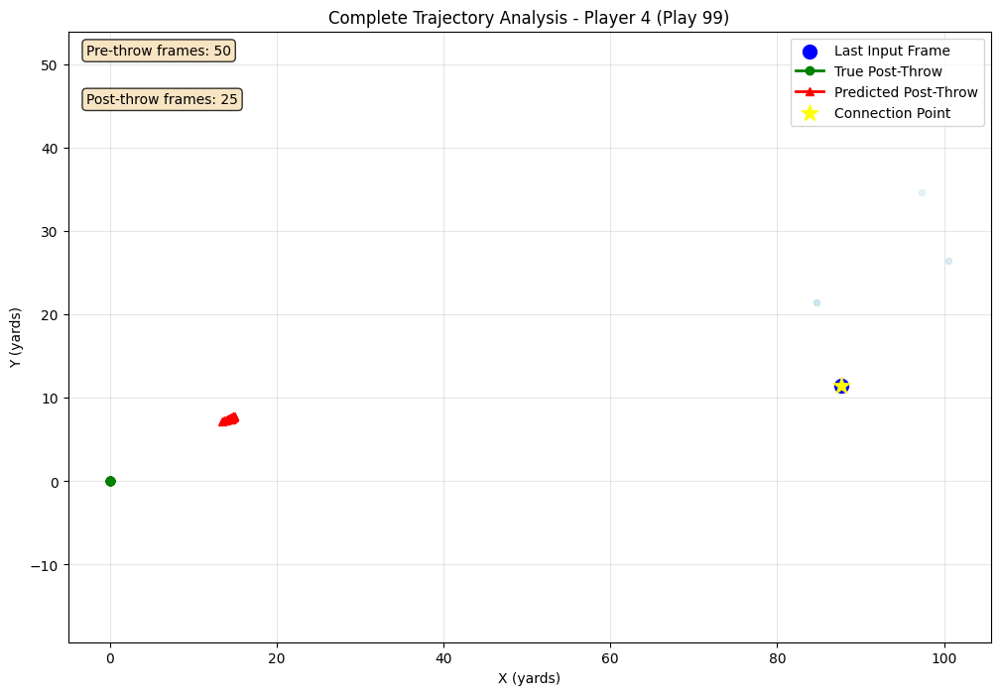


Connection Analysis for Player 4:
Last input position: (87.71, 11.51)
First predicted position: (13.52, 7.24)
First true position: (0.00, 0.00)
Prediction gap: 74.31 yards
True gap: 88.46 yards


In [24]:
# Visualize pre-throw path + predicted + true post-throw paths
import matplotlib.pyplot as plt
import numpy as np

for sample_idx in range(20, 100):
    target_player_idx = 0  # or use mask to find target player

    # Get input data (pre-throw frames)
    X_sample = torch.tensor(X_data[sample_idx:sample_idx+1], dtype=torch.float32, device=device)
    mask = masks[sample_idx]

    # Get the last frame of input data (pre-throw)
    last_input_frame = X_sample[0, -1, :, :2].cpu().numpy()  # Last frame, all players, x,y coords
    last_input_frame_denorm = last_input_frame.copy()
    last_input_frame_denorm[:, 0] *= FIELD_X
    last_input_frame_denorm[:, 1] *= FIELD_Y

    # Get predictions (post-throw)
    graph_model.eval()
    with torch.no_grad():
        adj_intra_seq = adj_intra_all[sample_idx:sample_idx+1]
        adj_bipartite_seq = adj_bipartite_all[sample_idx:sample_idx+1]
        adj_to_landing_seq = adj_to_landing_all[sample_idx:sample_idx+1]
        
        Y_pred_graph = graph_model(
            X_sample, 
            adj_intra_seq, 
            adj_bipartite_seq, 
            adj_to_landing_seq
        ).cpu().numpy()[0]

    # Get true post-throw data
    Y_true = Y_data[sample_idx]
    Y_true_denorm = Y_true.copy()
    Y_true_denorm[..., 0] *= FIELD_X
    Y_true_denorm[..., 1] *= FIELD_Y

    Y_pred_graph_denorm = Y_pred_graph.copy()
    Y_pred_graph_denorm[..., 0] *= FIELD_X
    Y_pred_graph_denorm[..., 1] *= FIELD_Y

    # Find target player
    if mask.sum() > 0:
        target_player_idx = np.where(mask == 1)[0][0]
    else:
        target_player_idx = 0

    # Plot the complete trajectory
    plt.figure(figsize=(12, 8))

    # Plot pre-throw path (input frames) - show multiple frames
    for frame_idx in range(0, X_sample.shape[1], 10):  # Every 10th frame
        frame_data = X_sample[0, frame_idx, :, :2].cpu().numpy()
        frame_data_denorm = frame_data.copy()
        frame_data_denorm[:, 0] *= FIELD_X
        frame_data_denorm[:, 1] *= FIELD_Y
        
        alpha = 0.3 + 0.7 * (frame_idx / X_sample.shape[1])  # Fade in over time
        plt.scatter(frame_data_denorm[target_player_idx, 0], 
                    frame_data_denorm[target_player_idx, 1], 
                    c='lightblue', alpha=alpha, s=20)

    # Plot last input frame (connection point)
    plt.scatter(last_input_frame_denorm[target_player_idx, 0], 
                last_input_frame_denorm[target_player_idx, 1], 
                c='blue', s=100, marker='o', label='Last Input Frame', zorder=5)

    # Plot true post-throw path
    plt.plot(Y_true_denorm[:, target_player_idx, 0], 
            Y_true_denorm[:, target_player_idx, 1], 
            'g-o', linewidth=2, markersize=6, label='True Post-Throw', zorder=3)

    # Plot predicted post-throw path
    plt.plot(Y_pred_graph_denorm[:, target_player_idx, 0], 
            Y_pred_graph_denorm[:, target_player_idx, 1], 
            'r-^', linewidth=2, markersize=6, label='Predicted Post-Throw', zorder=4)

    # Highlight the connection point
    plt.scatter(last_input_frame_denorm[target_player_idx, 0], 
                last_input_frame_denorm[target_player_idx, 1], 
                c='yellow', s=150, marker='*', label='Connection Point', zorder=6)

    plt.title(f'Complete Trajectory Analysis - Player {target_player_idx} (Play {sample_idx})')
    plt.xlabel('X (yards)')
    plt.ylabel('Y (yards)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.axis('equal')

    # Add text annotations
    plt.text(0.02, 0.98, f'Pre-throw frames: {X_sample.shape[1]}', 
            transform=plt.gca().transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    plt.text(0.02, 0.90, f'Post-throw frames: {Y_true.shape[0]}', 
            transform=plt.gca().transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    plt.show()

    # Print connection analysis
    last_input_pos = last_input_frame_denorm[target_player_idx]
    first_pred_pos = Y_pred_graph_denorm[0, target_player_idx]
    first_true_pos = Y_true_denorm[0, target_player_idx]

    print(f"\nConnection Analysis for Player {target_player_idx}:")
    print(f"Last input position: ({last_input_pos[0]:.2f}, {last_input_pos[1]:.2f})")
    print(f"First predicted position: ({first_pred_pos[0]:.2f}, {first_pred_pos[1]:.2f})")
    print(f"First true position: ({first_true_pos[0]:.2f}, {first_true_pos[1]:.2f})")
    print(f"Prediction gap: {np.linalg.norm(last_input_pos - first_pred_pos):.2f} yards")
    print(f"True gap: {np.linalg.norm(last_input_pos - first_true_pos):.2f} yards")


In [25]:
# Generate submission file using Transformer Model (first model)
import pandas as pd
import numpy as np
import torch

# Load test data
test_input = pd.read_csv("test_input.csv")
test_submission_format = pd.read_csv("sample_submission.csv")

print(f"Test input shape: {test_input.shape}")
print(f"Test submission format shape: {test_submission_format.shape}")

# Process test data similar to training data
test_input_processed = test_input.copy()

# Drop columns that were dropped in training
drop_cols = ["player_name", "player_height", "player_weight", "player_birth_date"]
test_input_processed.drop(columns=drop_cols, inplace=True, errors="ignore")

# Apply same preprocessing as training data
cat_cols = ["player_position", "player_role", "player_side", "play_direction"]

# Use the same encoders from training
for col in cat_cols:
    if col in test_input_processed.columns:
        test_input_processed[col] = encoders[col].transform(test_input_processed[col].astype(str))

# Normalize continuous fields
test_input_processed["x_norm"] = test_input_processed["x"] / FIELD_X
test_input_processed["y_norm"] = test_input_processed["y"] / FIELD_Y
test_input_processed["s_norm"] = test_input_processed["s"] / test_input_processed["s"].max()
test_input_processed["a_norm"] = test_input_processed["a"] / test_input_processed["a"].max()

# Convert degrees to radians and compute velocity components
test_input_processed["dir_rad"] = np.deg2rad(test_input_processed["dir"])
test_input_processed["vx"] = test_input_processed["s_norm"] * np.cos(test_input_processed["dir_rad"])
test_input_processed["vy"] = test_input_processed["s_norm"] * np.sin(test_input_processed["dir_rad"])

# Ball-relative features
test_input_processed["x_rel_to_ball"] = (test_input_processed["x"] - test_input_processed["ball_land_x"]) / FIELD_X
test_input_processed["y_rel_to_ball"] = (test_input_processed["y"] - test_input_processed["ball_land_y"]) / FIELD_Y
test_input_processed["dist_to_ball"] = np.sqrt(
    (test_input_processed["x_rel_to_ball"] ** 2) + (test_input_processed["y_rel_to_ball"] ** 2)
)

print("Test data preprocessing completed!")


Test input shape: (49753, 23)
Test submission format shape: (5837, 3)
Test data preprocessing completed!


In [26]:
# Process test data into sequences and generate predictions with Transformer Model
feature_cols = [
    "x_norm", "y_norm", "vx", "vy", "a_norm",
    "player_position", "player_role", "player_side", "play_direction",
    "x_rel_to_ball", "y_rel_to_ball", "dist_to_ball",
]

# Group test data by plays
test_plays = test_input_processed.groupby(["game_id", "play_id"])

# Process each test play
test_predictions = []

for (game_id, play_id), play_df in test_plays:
    # Sort by frame_id
    frames_in = play_df.sort_values("frame_id")
    
    # Group by frame
    grouped_frames = []
    for frame_id, frame_df in frames_in.groupby("frame_id"):
        mat = frame_df[feature_cols].to_numpy()
        if mat.shape[0] < 22:  # handle missing players
            mat = np.pad(mat, ((0, 22 - mat.shape[0]), (0, 0)), mode="constant")
        grouped_frames.append(mat)
    
    if not grouped_frames:
        continue
        
    X_seq = np.stack(grouped_frames)
    
    # Pad or truncate to MAX_INPUT_FRAMES
    if X_seq.shape[0] < MAX_INPUT_FRAMES:
        pad_len = MAX_INPUT_FRAMES - X_seq.shape[0]
        last_frame = X_seq[-1:]
        pad_frames = np.repeat(last_frame, pad_len, axis=0)
        X_seq = np.concatenate([X_seq, pad_frames], axis=0)
    else:
        X_seq = X_seq[:MAX_INPUT_FRAMES]
    
    # Convert to tensor and predict
    X_tensor = torch.tensor(X_seq, dtype=torch.float32).unsqueeze(0).to(device)  # Add batch dimension
    
    model.eval()
    with torch.no_grad():
        pred = model(X_tensor).cpu().numpy()[0]  # Remove batch dimension
    
    # Store predictions with metadata
    test_predictions.append({
        'game_id': game_id,
        'play_id': play_id,
        'predictions': pred  # Shape: (25, 22, 2)
    })

print(f"Processed {len(test_predictions)} test plays")


Processed 143 test plays


In [27]:
# Create submission file for Transformer Model
submission_transformer = []

for pred_data in test_predictions:
    game_id = pred_data['game_id']
    play_id = pred_data['play_id']
    predictions = pred_data['predictions']  # Shape: (25, 22, 2)
    
    # Get the specific players/frames to predict for this play
    play_test_data = test_submission_format[
        (test_submission_format['id'].str.startswith(f"{game_id}_{play_id}"))
    ]
    
    for _, row in play_test_data.iterrows():
        # Parse the ID to get nfl_id and frame_id
        id_parts = row['id'].split('_')
        nfl_id = int(id_parts[2])
        frame_id = int(id_parts[3])
        
        # Find the player index in our prediction array
        # We need to map nfl_id to player index (0-21)
        play_input_data = test_input_processed[
            (test_input_processed['game_id'] == game_id) & 
            (test_input_processed['play_id'] == play_id)
        ]
        
        # Get unique nfl_ids and create mapping
        unique_nfl_ids = play_input_data['nfl_id'].unique()
        nfl_id_to_idx = {nfl_id: idx for idx, nfl_id in enumerate(unique_nfl_ids)}
        
        if nfl_id in nfl_id_to_idx:
            player_idx = nfl_id_to_idx[nfl_id]
            
            # Get prediction for this player and frame
            if player_idx < 22 and frame_id <= 25:
                pred_x = predictions[frame_id - 1, player_idx, 0] * FIELD_X  # Denormalize
                pred_y = predictions[frame_id - 1, player_idx, 1] * FIELD_Y  # Denormalize
                
                submission_transformer.append({
                    'id': row['id'],
                    'x': pred_x,
                    'y': pred_y
                })
            else:
                # Default prediction if player not found
                submission_transformer.append({
                    'id': row['id'],
                    'x': 0.0,
                    'y': 0.0
                })
        else:
            # Default prediction if player not found
            submission_transformer.append({
                'id': row['id'],
                'x': 0.0,
                'y': 0.0
            })

# Convert to DataFrame and save
submission_df_transformer = pd.DataFrame(submission_transformer)
submission_df_transformer.to_csv('submission_transformer.csv', index=False)

print(f"Transformer model submission saved: {len(submission_df_transformer)} predictions")
print(f"Sample predictions:")
print(submission_df_transformer.head())


Transformer model submission saved: 5837 predictions
Sample predictions:
                      id          x         y
0  2024120805_74_54586_1  19.911484  8.547074
1  2024120805_74_54586_2  19.911484  8.547074
2  2024120805_74_54586_3  19.911484  8.547074
3  2024120805_74_54586_4  19.911484  8.547074
4  2024120805_74_54586_5  19.911484  8.547074


In [28]:
# Generate submission file using Graph Model (third model)
print("Generating predictions with Graph Model...")

# Process test data into sequences for graph model
test_predictions_graph = []

for (game_id, play_id), play_df in test_plays:
    # Sort by frame_id
    frames_in = play_df.sort_values("frame_id")
    
    # Group by frame
    grouped_frames = []
    for frame_id, frame_df in frames_in.groupby("frame_id"):
        mat = frame_df[feature_cols].to_numpy()
        if mat.shape[0] < 22:  # handle missing players
            mat = np.pad(mat, ((0, 22 - mat.shape[0]), (0, 0)), mode="constant")
        grouped_frames.append(mat)
    
    if not grouped_frames:
        continue
        
    X_seq = np.stack(grouped_frames)
    
    # Pad or truncate to MAX_INPUT_FRAMES
    if X_seq.shape[0] < MAX_INPUT_FRAMES:
        pad_len = MAX_INPUT_FRAMES - X_seq.shape[0]
        last_frame = X_seq[-1:]
        pad_frames = np.repeat(last_frame, pad_len, axis=0)
        X_seq = np.concatenate([X_seq, pad_frames], axis=0)
    else:
        X_seq = X_seq[:MAX_INPUT_FRAMES]
    
    # Compute adjacency matrices for this test play
    # Create a temporary dataframe for adjacency computation
    temp_df = play_df.copy()
    temp_df = temp_df.sort_values("frame_id")
    
    # Compute adjacency matrices
    adj_intra, adj_bipartite, adj_to_landing = compute_adjacency_seq(
        X_seq.reshape(1, X_seq.shape[0], X_seq.shape[1], X_seq.shape[2]), 
        temp_df
    )
    
    # Convert to tensor and predict
    X_tensor = torch.tensor(X_seq, dtype=torch.float32).unsqueeze(0).to(device)
    adj_intra = adj_intra.to(device)
    adj_bipartite = adj_bipartite.to(device)
    adj_to_landing = adj_to_landing.to(device)
    
    graph_model.eval()
    with torch.no_grad():
        pred = graph_model(X_tensor, adj_intra, adj_bipartite, adj_to_landing).cpu().numpy()[0]
    
    # Store predictions with metadata
    test_predictions_graph.append({
        'game_id': game_id,
        'play_id': play_id,
        'predictions': pred  # Shape: (25, 22, 2)
    })

print(f"Processed {len(test_predictions_graph)} test plays with Graph Model")


Generating predictions with Graph Model...
Processed 143 test plays with Graph Model


In [29]:
# Create submission file for Graph Model
submission_graph = []

for pred_data in test_predictions_graph:
    game_id = pred_data['game_id']
    play_id = pred_data['play_id']
    predictions = pred_data['predictions']  # Shape: (25, 22, 2)
    
    # Get the specific players/frames to predict for this play
    play_test_data = test_submission_format[
        (test_submission_format['id'].str.startswith(f"{game_id}_{play_id}"))
    ]
    
    for _, row in play_test_data.iterrows():
        # Parse the ID to get nfl_id and frame_id
        id_parts = row['id'].split('_')
        nfl_id = int(id_parts[2])
        frame_id = int(id_parts[3])
        
        # Find the player index in our prediction array
        play_input_data = test_input_processed[
            (test_input_processed['game_id'] == game_id) & 
            (test_input_processed['play_id'] == play_id)
        ]
        
        # Get unique nfl_ids and create mapping
        unique_nfl_ids = play_input_data['nfl_id'].unique()
        nfl_id_to_idx = {nfl_id: idx for idx, nfl_id in enumerate(unique_nfl_ids)}
        
        if nfl_id in nfl_id_to_idx:
            player_idx = nfl_id_to_idx[nfl_id]
            
            # Get prediction for this player and frame
            if player_idx < 22 and frame_id <= 25:
                pred_x = predictions[frame_id - 1, player_idx, 0] * FIELD_X  # Denormalize
                pred_y = predictions[frame_id - 1, player_idx, 1] * FIELD_Y  # Denormalize
                
                submission_graph.append({
                    'id': row['id'],
                    'x': pred_x,
                    'y': pred_y
                })
            else:
                # Default prediction if player not found
                submission_graph.append({
                    'id': row['id'],
                    'x': 0.0,
                    'y': 0.0
                })
        else:
            # Default prediction if player not found
            submission_graph.append({
                'id': row['id'],
                'x': 0.0,
                'y': 0.0
            })

# Convert to DataFrame and save
submission_df_graph = pd.DataFrame(submission_graph)
submission_df_graph.to_csv('submission_graph.csv', index=False)

print(f"Graph model submission saved: {len(submission_df_graph)} predictions")
print(f"Sample predictions:")
print(submission_df_graph.head())

print("\n" + "="*50)
print("SUBMISSION FILES GENERATED:")
print("1. submission_transformer.csv - Transformer Model predictions")
print("2. submission_graph.csv - Graph Model predictions")
print("="*50)


Graph model submission saved: 5837 predictions
Sample predictions:
                      id          x          y
0  2024120805_74_54586_1  44.216763  17.872927
1  2024120805_74_54586_2  44.377998  18.099335
2  2024120805_74_54586_3  44.546940  18.324568
3  2024120805_74_54586_4  44.717476  18.545555
4  2024120805_74_54586_5  44.884506  18.759718

SUBMISSION FILES GENERATED:
1. submission_transformer.csv - Transformer Model predictions
2. submission_graph.csv - Graph Model predictions
